# Did they follow the same route?
## From two GPS traces to a decision we can defend

**Part 2 · Model Prototyping · Cabify Data Science Challenge**

> ### In six lines
>
> 1. **Simple geometry is enough.** Eight measurements and an XGBoost give 94.3 % balanced accuracy on test. A 42-variable vector, a t2vec adaptation and a hybrid do not improve on that in any defensible way: their paired confidence intervals include zero.
> 2. **The limit is not the model, it is the label.** 83 % of journeys are judged by a single person, and the panel is eight annotators with different criteria: one marks «they differ» 65 % of the time and another 40 %. The model agrees 98 % with the lenient annotator and 88 % with the strict one. It has learned a particular threshold, not a truth.
> 3. **Translated into money, the median deviation is 11 cents** on an average fare of €4.63. That sounds small until you compare it with the margin: Cabify closed 2025 with 3.3 % EBITDA, so **almost half of all journeys deviate by more than that journey leaves in profit**.
> 4. **The model catches 90.2 % of the cases but recovers 97.4 % of the money:** it fails on the cheap trips. Accuracy understates what it does.
> 5. **The error can be turned into a lever.** With conformal prediction, sending 6 % of journeys to human review brings the automated error down from 6.3 % to 1.9 %; 13 % brings it to 0.5 %. The business picks the point.
> 6. **Recommendation:** deploy basic geometry with conformal prediction, review by economic impact rather than by a fixed rate, and spend the next euro on a second annotation — not on a bigger model. The detail is in [section 11](#recomendacion).

We have two traces of the same journey: the one that was predicted and the one that happened. The label we are given is perceptual: whether a person considers them similar when looking at a map. But the brief motivates the problem from **pricing**, which is set before the trip using the estimated route. Those two questions are not the same, and part of the value of this work lies in measuring how far apart they are: we do that in [section 9](#dinero), after solving the problem as posed.

Two questions guide the walkthrough. The technical one: **do we need to learn a complex representation, or are a few well-chosen geometric measurements enough?** And the business one, which appears in the second half: **what does it cost when the routing engine is wrong, and how much human review is needed to decide the rest automatically?**

We will compare an eight-variable baseline, an interpretable 42-measurement vector, a reduced t2vec adaptation with a reconstruction decoder and a classifier, and a combination of vectors. We add exploratory extensions using the road network and a t2vec version corrected after auditing its reconstruction, both carried out after inspecting the original test set.

The path of the analysis is: understand the votes → build representations → compare on validation → check on test → go back to the routes to understand hits and misses. **The best model will be the one chosen by the rule fixed on validation**, not whichever comes first when sorting the test results.

| Method we try | What the classifier receives | Why try it | What it may lose or cost |
|---|---|---|---|
| Basic geometry + XGBoost | 8 measurements: both lengths, relative difference, endpoints, mean separations and discrete maximum | Check how much a small, understandable baseline already solves | Summarises each pair; may dilute the weight of a localised detour |
| Interpretable vector + XGBoost | 42 measurements, including the previous 8: far-apart proportions, segments, IoU, turns and ordering | Explicitly represent the differences we proposed looking at on a map | More variables do not necessarily add new information; they can overfit |
| Reduced t2vec + neural classifier | Two 64-dimensional embeddings, plus their absolute difference and product: 256 values | Learn patterns without labels before learning the human judgement | The later audit found failed reconstruction and a defect in the sampled loss; it is not a valid benchmark of the original t2vec |
| Interpretable vector + t2vec + XGBoost | The 42 measurements and the 256 values above: 298 in total | Check whether what was learned complements what we measured by hand | More complexity; it could add noise without improving stably |
| Reduced t2vec with corrected loss + classifier | The same architecture and vector comparison, retrained with a fully normalised objective | Fix the handling of the end-of-sequence token and evaluate reconstruction and classification separately | It still needs data and adequate resolution; documented as a new experiment |
| Road graph and travel times + XGBoost, alone and with geometry | Street variables, connectivity, estimated times and map-match quality | Separate geometric closeness from connectivity and cost of driving | Current map, approximations and uncertain matches; exploratory comparison made after the original test |

**These are not just difference vectors.** The baseline already keeps the individual lengths; t2vec keeps both full embeddings in addition to their comparison. We have not run an ablation of «concatenation only» against «differences only»: answering that would require testing it on validation.

> The results that follow come from the real challenge file. They are not simulations. The estimates for the photography experiment belong to the previous notebook.

The brief mentions 5,000 selected journeys. The linked file contains **2,386 distinct journeys**. The 3,000/1,000/1,000 request is read as training/validation/test; we keep its 60/20/20 proportion without duplicating journeys: **1,432 / 477 / 477**.

In [1]:
from pathlib import Path
import sys, json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.patches import FancyBboxPatch
from IPython.display import display, Markdown

ROOT = Path.cwd()
sys.path.insert(0,str(ROOT/'src'))
os.environ.setdefault('MPLCONFIGDIR','/private/tmp/cabify-mpl')
from routes.data import load_data
from routes.features import build_features, project_pair, clean_line, sample_line, BASE_FEATURES
from routes.road_graph import load_graph

# Antes de reproducir las figuras: python scripts/run_routes.py
# Este notebook lee los resultados congelados; no vuelve a seleccionar con test.
R = ROOT/'results/routes'
def read(name):return json.loads((R/name).read_text())
audit=read('audit.json'); metrics=read('metrics.json'); frozen=read('frozen_selection.json')
details=read('training_details.json'); encoder=read('t2vec_manifest.json')
comparisons=read('comparisons.json'); graph_status=read('road_graph_status.json')
df,routes=load_data()
features=build_features()
predictions=pd.DataFrame(read('predictions.json')).set_index('journey_id')

INK,TEAL,ORANGE,RED,MUTED,BG='#193441','#117C83','#E87524','#B74F4F','#637781','#FAF9F5'
plt.rcParams.update({'figure.facecolor':BG,'axes.facecolor':BG,'savefig.facecolor':BG,
 'font.family':'DejaVu Sans','font.size':11,'text.color':INK,'axes.labelcolor':INK,
 'axes.spines.top':False,'axes.spines.right':False,'axes.titleweight':'bold',
 'axes.titlelocation':'left','axes.titlesize':13,'figure.dpi':110,'savefig.dpi':150})
FIG=ROOT/'figures/routes';FIG.mkdir(parents=True,exist_ok=True)
def finish(fig,name,note='Challenge dataset · reproducible results · seed 20261014'):
    fig.text(.02,.015,note,fontsize=9,color=MUTED)
    fig.tight_layout(rect=(0,.05,1,.95))
    fig.savefig(FIG/(name+'.png'),bbox_inches='tight')
    plt.show();plt.close(fig)
names={'geometria_base':'Basic geometry','vector_interpretable':'Interpretable vector',
       't2vec_decoder_clasificador':'t2vec + classifier','hibrido_vector_t2vec':'Vector + t2vec'}

## 1. Before modelling: how many examples do we actually have?

A row is an **annotation**, not a new journey. On top of that, some people appear several times for the same journey. Counting those rows as independent votes would over-weight that person.

We apply a rule that predates training:

1. An annotator counts at most once per journey.
2. Their identical repeated answers collapse into one.
3. If they combine «I don't know» with a single decision, we keep the decision.
4. If the same person says both «the same» and «they differ», their vote is undetermined.
5. Across different people, we keep the disagreement instead of inventing certainty.

We find **123 additional records for the same annotator-journey pair**, with seven contradictory annotator-journey pairs. This does not mean the remaining votes are objective truth.

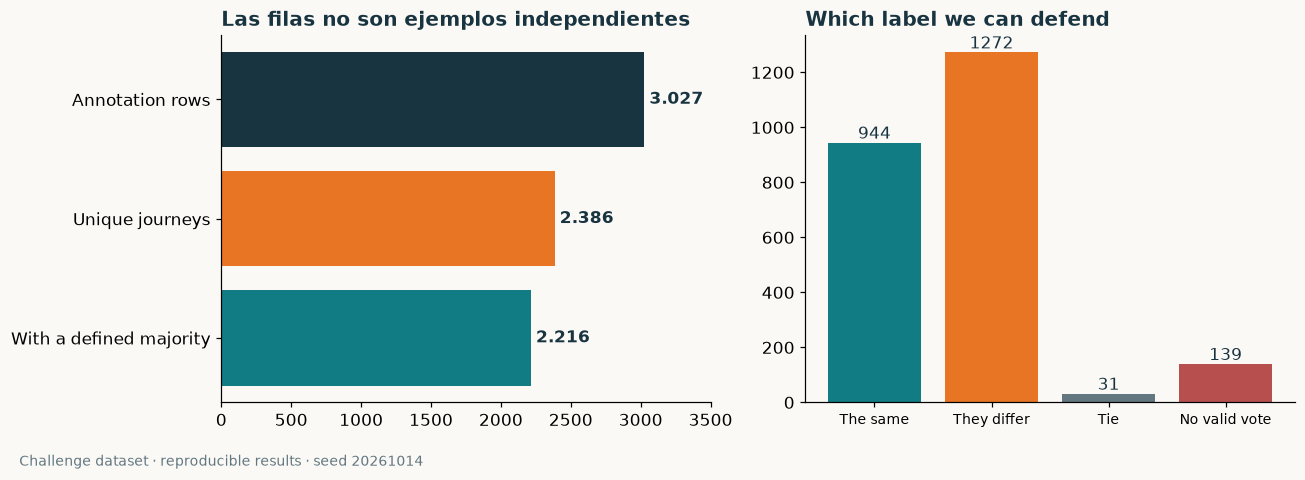

status,They differ,The same,Tie,No valid vote
split,,,,
test,255,188,7,27
train,763,567,18,84
val,254,189,6,28


In [2]:
counts=df.status.value_counts()
fig,axs=plt.subplots(1,2,figsize=(12,4.6))
labels=['Annotation rows','Unique journeys','With a defined majority']
values=[audit['n_records'],len(df),int(df.target_hard.notna().sum())]
axs[0].barh(labels[::-1],values[::-1],color=[TEAL,ORANGE,INK])
for y,v in enumerate(values[::-1]):axs[0].text(v+35,y,f'{v:,}'.replace(',','.'),va='center',weight='bold')
axs[0].set_xlim(0,3500);axs[0].set_title('Las filas no son ejemplos independientes')
status_order=['same','different','tie','unknown']
axs[1].bar(['The same','They differ','Tie','No valid vote'],
           [counts.get(k,0) for k in status_order],color=[TEAL,ORANGE,MUTED,RED])
for i,k in enumerate(status_order):axs[1].text(i,counts.get(k,0)+15,str(counts.get(k,0)),ha='center')
axs[1].set_title('Which label we can defend');axs[1].tick_params(axis='x',labelsize=9)
finish(fig,'01_muestra_y_etiquetas')
display(pd.crosstab(df.split,df.status).rename(columns={'same':'The same','different':'They differ','tie':'Tie','unknown':'No valid vote'}))

### 1.1 Are there no nulls, or are there no data problems?

Those are different questions. First we check the original file: missing fields, null JSON values and empty contents. Then we look inside the coordinate lists. A field called «route» can exist and still not contain a usable trajectory.

Each point must have two finite numbers in the order **[latitude, longitude]**, with latitude between −90 and 90 and longitude between −180 and 180. The route also needs at least two distinct positions. Passing these checks guarantees neither GPS accuracy nor that the trace follows a road.

**Scope of this addition:** this EDA was incorporated after the models had been evaluated; we place it here to make the notebook easier to read. Structural quality is audited across the whole file. The distributions we connect to modelling decisions are studied on training data; the comparison across splits is descriptive. No models, labels, filters or thresholds are changed on the basis of this analysis.

In [3]:
import hashlib
from pyproj import Geod
raw_records=json.loads((ROOT/'data/raw/challenge_dataset.json').read_text())
raw_fields=['journey_id','annotator','annotation','estimated_route','real_route']
missing_report=[]
for field in raw_fields:
    present=[row[field] for row in raw_records if field in row]
    missing_report.append({'Campo':field,'Filas revisadas':len(raw_records),
        'Campo ausente':sum(field not in row for row in raw_records),
        'Valor null':sum(value is None for value in present),
        'Empty (text or list)':sum(isinstance(value,(str,list,dict)) and len(value)==0 for value in present)})
missing_report=pd.DataFrame(missing_report).set_index('Campo')
display(missing_report)

# One geometry per journey: repeated annotations do not inflate this count.
unique_raw={}
for row in raw_records:
    unique_raw.setdefault(row['journey_id'],row)
geod=Geod(ellps='WGS84')
route_rows=[];quality={}
for field,kind in [('estimated_route','Estimated'),('real_route','Real')]:
    checks={'Rutas revisadas':len(unique_raw),'Route missing, null or empty':0,
            'Points with invalid structure':0,'Componentes de coordenada null':0,
            'Non-numeric or non-finite points':0,'Puntos fuera de rango':0,
            'Routes with fewer than 2 distinct positions':0,'Puntos (0, 0)':0}
    for jid,row in unique_raw.items():
        value=row.get(field)
        if not isinstance(value,list) or not value:
            checks['Route missing, null or empty']+=1
            continue
        valid=[]
        for point in value:
            if not isinstance(point,list) or len(point)!=2:
                checks['Points with invalid structure']+=1
                continue
            nulls=sum(x is None for x in point)
            checks['Componentes de coordenada null']+=nulls
            if nulls:continue
            if not all(isinstance(x,(int,float)) and not isinstance(x,bool) and np.isfinite(x) for x in point):
                checks['Non-numeric or non-finite points']+=1
                continue
            lat,lon=point
            if abs(lat)>90 or abs(lon)>180:
                checks['Puntos fuera de rango']+=1
                continue
            checks['Puntos (0, 0)']+=int(lat==0 and lon==0)
            valid.append(point)
        coords=np.asarray(valid,float)
        if len(coords)<2 or len(np.unique(coords,axis=0))<2:
            checks['Routes with fewer than 2 distinct positions']+=1
            continue
        # Nunca calculamos sobre una ruta reparada silenciosamente.
        if len(valid)!=len(value):continue
        _,_,steps=geod.inv(coords[:-1,1],coords[:-1,0],coords[1:,1],coords[1:,0])
        adjacent=(np.diff(coords,axis=0)==0).all(axis=1)
        feature_length=features.loc[jid,'length_est' if kind=='Estimated' else 'length_real']
        route_rows.append(dict(journey_id=jid,split=df.loc[jid,'split'],kind=kind,
            n_points=len(coords),n_repeated_adjacent=int(adjacent.sum()),n_steps=len(steps),
            length_km=float(feature_length/1000),geodesic_length_km=float(steps.sum()/1000),
            max_step_m=float(steps.max()),median_step_m=float(np.median(steps)),
            points_per_km=float(len(coords)/(feature_length/1000)),
            geometry_hash=hashlib.sha256(coords.tobytes()).hexdigest()))
    quality[kind]=checks
route_eda=pd.DataFrame(route_rows)
quality=pd.DataFrame(quality)
display(quality)
assert len(route_eda)==2*len(df), 'There are invalid routes: review before modelling, do not impute coordinates automatically.'
feature_checks=pd.Series({
    'Journeys with no probabilistic target (no valid votes)':int(df.target_soft.isna().sum()),
    'Journeys with no binary majority (no votes or a tie)':int(df.target_hard.isna().sum()),
    'NaN values across the 42 geometric variables':int(features.isna().to_numpy().sum()),
    'Infinite values across the 42 geometric variables':int(np.isinf(features.to_numpy()).sum()),
    'Variables constantes en entrenamiento':int((features.loc[df.index[df.split=='train']].nunique()<=1).sum())
},name='Recuento')
display(feature_checks.to_frame())
train_ids=df.index[df.split=='train']
train_routes=route_eda[route_eda.split=='train'].copy()
train_features=features.loc[train_ids].join(df[['status','n_unique_annotators','n_votes']])

,Filas revisadas,Campo ausente,Valor null,Empty (text or list)
Campo,,,,
journey_id,3027,0,0,0
annotator,3027,0,0,0
annotation,3027,0,0,0
estimated_route,3027,0,0,0
real_route,3027,0,0,0


,Estimated,Real
Rutas revisadas,2386,2386
"Route missing, null or empty",0,0
Points with invalid structure,0,0
Componentes de coordenada null,0,0
Non-numeric or non-finite points,0,0
Puntos fuera de rango,0,0
Routes with fewer than 2 distinct positions,0,0
"Puntos (0, 0)",0,0


,Recuento
Journeys with no probabilistic target (no valid votes),139
Journeys with no binary majority (no votes or a tie),170
NaN values across the 42 geometric variables,0
Infinite values across the 42 geometric variables,0
Variables constantes en entrenamiento,0


**Reading:** we find no missing fields, nulls, empty routes or invalid coordinates under these rules. Nor are there missing or infinite values in the computed features. So this file **needs no numerical imputation**.

There is, however, missing supervised information: **139 journeys with no valid vote** and **31 ties**. In total, 170 journeys have no defined binary majority. «I don't know» is a valid human answer, not a null and not a «the same» vote. We do not fill it with the most frequent class. Later on we define how to use the votes we do have.

Variables the schema never contains are missing too: **per-point timestamps, observed duration and a route validated against the road network**. The absence of nulls does not create that information.

### 1.2 How large are these trips?

Let us not confuse the **length of the trip** with the **number of coordinates**. We compute the first by summing the distances between consecutive points of the polyline:

$$L=\sum_{i=1}^{n-1}\|x_{i+1}-x_i\|.$$

The $x_i$ are projected to metres in a local system shared by the pair. This is the length of the trace as represented, not a guarantee of kilometres actually driven. A stretch with no observations is joined by a straight line and may hide curves or a different path altogether.

In the tables and charts that follow, each training journey counts once. We show the **median** and percentiles because a mean can hide the tail of long trips. P95 means that 95 % of routes do not exceed that value.

,Journeys,Minimum,P25,Mediana,Media,P75,P95,Maximum
kind,,,,,,,,
Estimated,1432,0.64,3.70,6.32,8.49,11.21,22.36,56.96
Real,1432,0.66,3.66,6.47,8.45,11.11,22.07,41.05


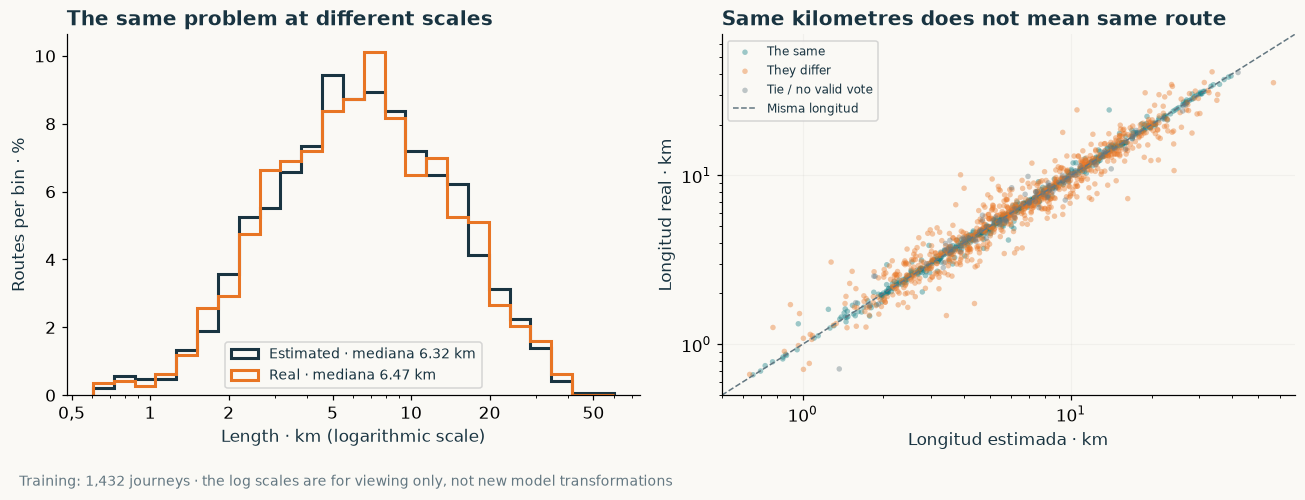

**Reading:** the real route has a median of **6.47 km** y P95 **22.07 km**. The real/estimated length ratio runs from **0.40** to **2.60**: there are routes far shorter or far longer than predicted. The diagonal mixes labels: covering the same kilometres is not enough to decide whether the same streets were taken.

,Estimated · km,Real · km,Etiqueta disponible,Real / estimada
d90bdb26-587d-11ec-8cf5-4d1f2c6278c1,56.96,35.40,They differ,0.62
0c109a2e-52e4-11ec-a8b7-e5cb878fda4e,33.64,41.05,They differ,1.22
085922b6-52ff-11ec-b849-c5be2940f1d4,4.38,1.74,They differ,0.40
8fccb687-58dc-11ec-8b20-c7d4fc907220,3.88,10.08,They differ,2.60


In [4]:
length_summary=train_routes.groupby('kind').length_km.agg(
    Journeys='count',Minimum='min',P25=lambda s:s.quantile(.25),Mediana='median',
    Media='mean',P75=lambda s:s.quantile(.75),P95=lambda s:s.quantile(.95),Maximum='max')
display(length_summary.style.format({c:'{:.2f}' for c in length_summary.columns if c!='Journeys'})
        .set_caption('Longitud en km · solo entrenamiento'))

fig,axs=plt.subplots(1,2,figsize=(12,4.8))
bins=np.geomspace(train_routes.length_km.min()*.95,train_routes.length_km.max()*1.05,26)
for kind,color in [('Estimated',INK),('Real',ORANGE)]:
    values=train_routes.loc[train_routes.kind==kind,'length_km']
    axs[0].hist(values,bins=bins,weights=np.full(len(values),100/len(values)),histtype='step',lw=2,
                color=color,label=f'{kind} · mediana {values.median():.2f} km')
axs[0].set_xscale('log')
axs[0].set_xticks([.5,1,2,5,10,20,50],['0,5','1','2','5','10','20','50'])
axs[0].set(xlabel='Length · km (logarithmic scale)',ylabel='Routes per bin · %')
axs[0].set_title('The same problem at different scales');axs[0].legend(fontsize=9)
status_colors={'same':TEAL,'different':ORANGE,'tie':MUTED,'unknown':MUTED}
for status,label in [('same','The same'),('different','They differ'),('tie','Tie / no valid vote'),('unknown',None)]:
    subset=train_features[train_features.status==status]
    axs[1].scatter(subset.length_est/1000,subset.length_real/1000,s=13,alpha=.4,
                   color=status_colors[status],label=label,edgecolors='none',rasterized=True)
lims=[min(train_routes.length_km.min()*.8,.5),train_routes.length_km.max()*1.2]
axs[1].plot(lims,lims,color=MUTED,ls='--',lw=1,label='Misma longitud')
axs[1].set(xscale='log',yscale='log',xlim=lims,ylim=lims,
           xlabel='Longitud estimada · km',ylabel='Longitud real · km')
axs[1].set_title('Same kilometres does not mean same route')
axs[1].legend(fontsize=8);axs[1].grid(alpha=.12)
finish(fig,'eda_01_longitudes','Training: 1,432 journeys · the log scales are for viewing only, not new model transformations')

ratio=train_features.length_real/train_features.length_est
display(Markdown(f'**Reading:** the real route has a median of **{train_features.length_real.median()/1000:.2f} km** '
    f'y P95 **{train_features.length_real.quantile(.95)/1000:.2f} km**. The real/estimated length ratio '
    f'runs from **{ratio.min():.2f}** to **{ratio.max():.2f}**: there are routes far shorter or far longer than predicted. '
    'The diagonal mixes labels: covering the same kilometres is not enough to decide whether the same streets were taken.'))

extreme_ids=pd.Index([
    train_features.length_est.idxmax(),train_features.length_real.idxmax(),ratio.idxmin(),ratio.idxmax()
]).unique()
extremes=train_features.loc[extreme_ids,['length_est','length_real','status']].copy()
extremes[['length_est','length_real']]/=1000
extremes['Real / estimada']=ratio.loc[extreme_ids]
extremes=extremes.rename(columns={'length_est':'Estimated · km','length_real':'Real · km','status':'Etiqueta disponible'})
extremes['Etiqueta disponible']=extremes['Etiqueta disponible'].map(
    {'same':'The same','different':'They differ','tie':'Tie','unknown':'No valid vote'})
display(extremes.style.format({'Estimated · km':'{:.2f}','Real · km':'{:.2f}','Real / estimada':'{:.2f}'})
        .set_caption('Extreme training cases: maximum lengths and minimum/maximum ratios'))

Extremes deserve inspection, not automatic removal. A large detour may be precisely the example we need to recognise. We apply no percentile trimming and delete no long journeys: doing so would first require telling a data error apart from a valid but uncommon route.

### 1.3 Do more points mean better information?

Two 10 km routes can contain 100 and 1,000 points. That does not make the second one ten times longer, nor does it justify giving it ten times the weight. On top of that, some consecutive points repeat exactly the same coordinate: they describe a zero-length step.

We measure three different things: **number of points**, **consecutive repetitions** and **largest distance between two consecutive observations**. The last one flags stretches represented with little information. The 1 km reference shown below is only an inspection marker; it is not a validated rule for detecting errors and no filter is applied with it.

**This is not just a theoretical example:** in 2,376 of the 2,386 journeys — **99.6 %** — the two traces have a different number of points. The median is 249.5 points for the estimated route and 198 for the real one, across the whole file. That they almost never match exactly does not mean every difference is large: this is why we also look at the magnitude of the ratio between the two counts.

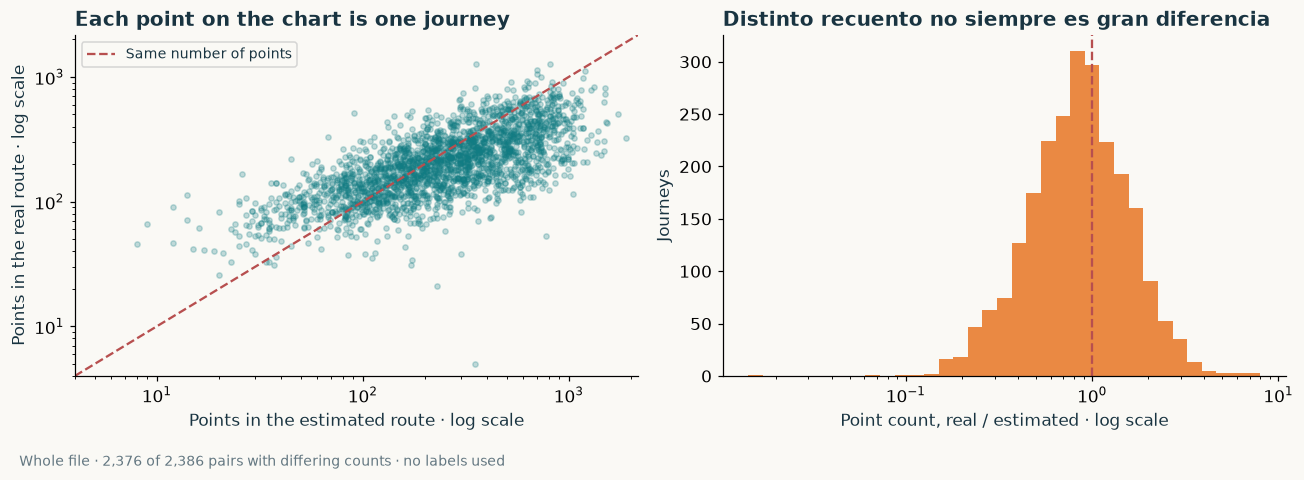

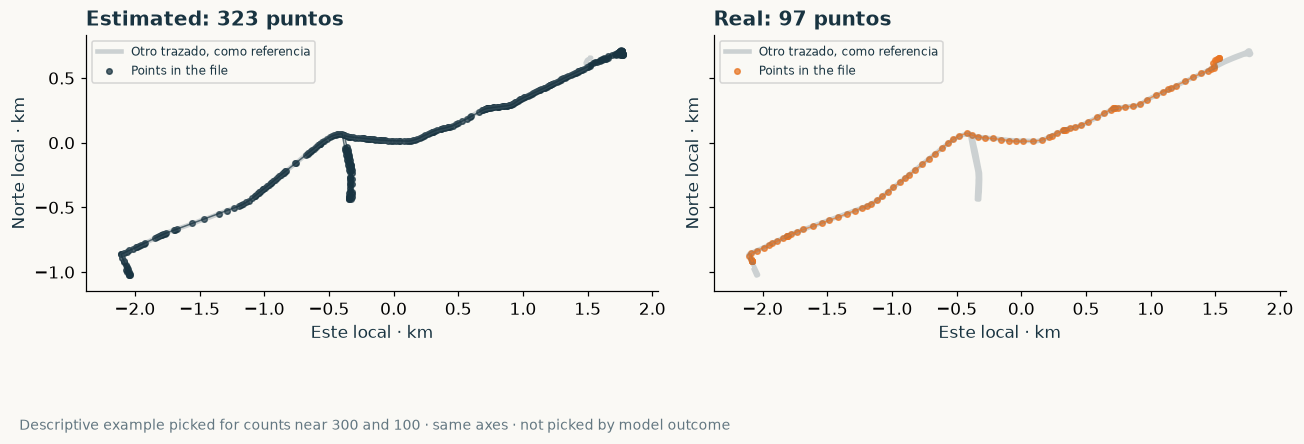

El viaje `7f29deb0-5c8c-11ec-8622-eff6f2c898b6` tiene **323 puntos estimados y 97 reales**. The polylines measure **5.86 km** y **4.14 km**, respectivamente. Count, length and similarity are distinct properties. Overlapping markers can hide repeated coordinates. This example illustrates sampling, without claiming both routes are identical.

,Points per route · training median,Points per km · training median,Pasos de longitud cero · archivo completo,% pasos de longitud cero · archivo completo,Routes with any step >1 km · whole file
Ruta,,,,,
Estimated,258.0,36.9,27156,3.48 %,2
Real,197.0,32.4,109431,19.22 %,133


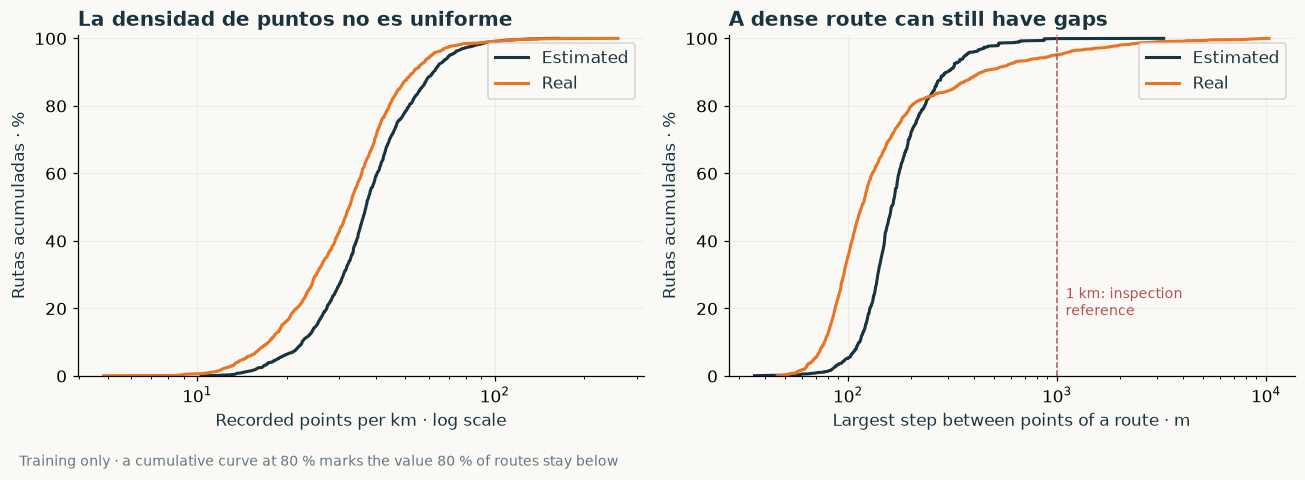

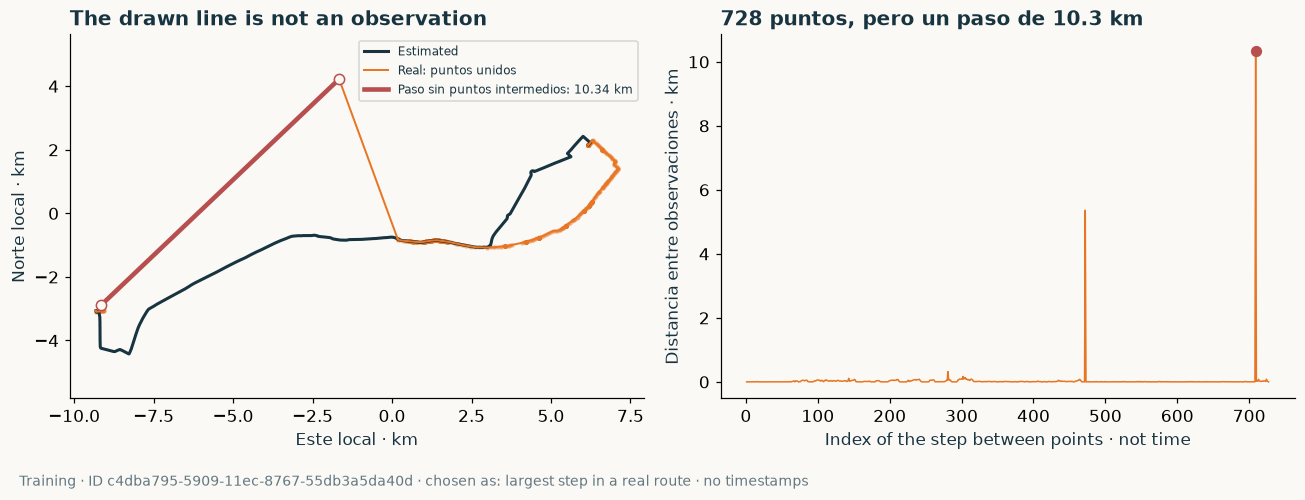

**What it implies:** we do not know whether this gap comes from simplifying the trace, losing records or from some other mechanism. Joining endpoints and resampling creates interpolated positions; it does not recover the streets driven. So a length, IoU or geometric distance can depend on the resolution of the file as well as on the driving.

In [5]:
point_counts=df[['n_estimated','n_real']].copy()
point_counts['ratio']=point_counts.n_real/point_counts.n_estimated
different_counts=int((point_counts.n_estimated!=point_counts.n_real).sum())
assert different_counts==2376
fig,axs=plt.subplots(1,2,figsize=(12,4.6))
axs[0].scatter(point_counts.n_estimated,point_counts.n_real,s=12,alpha=.25,color=TEAL,rasterized=True)
lims=[min(point_counts.n_estimated.min(),point_counts.n_real.min())*.8,
      max(point_counts.n_estimated.max(),point_counts.n_real.max())*1.15]
axs[0].plot(lims,lims,color=RED,ls='--',label='Same number of points')
axs[0].set(xscale='log',yscale='log',xlim=lims,ylim=lims,
    xlabel='Points in the estimated route · log scale',ylabel='Points in the real route · log scale')
axs[0].set_title('Each point on the chart is one journey');axs[0].legend(fontsize=9)
bins=np.geomspace(point_counts.ratio.min(),point_counts.ratio.max(),36)
axs[1].hist(point_counts.ratio,bins=bins,color=ORANGE,alpha=.85)
axs[1].axvline(1,color=RED,ls='--');axs[1].set_xscale('log')
axs[1].set(xlabel='Point count, real / estimated · log scale',ylabel='Journeys')
axs[1].set_title('Distinto recuento no siempre es gran diferencia')
finish(fig,'eda_02a_puntos_por_pareja',f'Whole file · {different_counts:,} of {len(df):,} pairs with differing counts · no labels used')

sampling_example='7f29deb0-5c8c-11ec-8622-eff6f2c898b6'
sample_a,sample_b=project_pair(*routes[sampling_example])
assert len(sample_a)==323 and len(sample_b)==97
fig,axs=plt.subplots(1,2,figsize=(12,5),sharex=True,sharey=True)
both=np.concatenate([sample_a,sample_b])/1000
low=both.min(axis=0);high=both.max(axis=0);padding=np.maximum((high-low)*.07,.05)
for ax,line,other,label,color in zip(axs,[sample_a,sample_b],[sample_b,sample_a],['Estimated','Real'],[INK,ORANGE]):
    ax.plot(other[:,0]/1000,other[:,1]/1000,color=MUTED,alpha=.3,lw=3,label='Otro trazado, como referencia')
    ax.plot(line[:,0]/1000,line[:,1]/1000,color=color,lw=1,alpha=.7)
    ax.scatter(line[:,0]/1000,line[:,1]/1000,s=13,color=color,alpha=.75,label='Points in the file')
    ax.set_title(f'{label}: {len(line)} puntos')
    ax.set(xlim=(low[0]-padding[0],high[0]+padding[0]),ylim=(low[1]-padding[1],high[1]+padding[1]),
           xlabel='Este local · km',ylabel='Norte local · km')
    ax.set_aspect('equal',adjustable='box');ax.legend(fontsize=8)
finish(fig,'eda_02b_ejemplo_323_97','Descriptive example picked for counts near 300 and 100 · same axes · not picked by model outcome')
display(Markdown(f'El viaje `{sampling_example}` tiene **323 puntos estimados y 97 reales**. '
    f'The polylines measure **{features.loc[sampling_example,"length_est"]/1000:.2f} km** y '
    f'**{features.loc[sampling_example,"length_real"]/1000:.2f} km**, respectivamente. '
    'Count, length and similarity are distinct properties. Overlapping markers can hide '
    'repeated coordinates. This example illustrates sampling, without claiming both routes are identical.'))

sampling_rows=[]
for kind,group in route_eda.groupby('kind',sort=False):
    train=group[group.split=='train']
    sampling_rows.append({'Ruta':kind,'Points per route · training median':train.n_points.median(),
        'Points per km · training median':train.points_per_km.median(),
        'Pasos de longitud cero · archivo completo':int(group.n_repeated_adjacent.sum()),
        '% pasos de longitud cero · archivo completo':100*group.n_repeated_adjacent.sum()/group.n_steps.sum(),
        'Routes with any step >1 km · whole file':int((group.max_step_m>1000).sum())})
sampling_summary=pd.DataFrame(sampling_rows).set_index('Ruta')
display(sampling_summary.style.format({'Points per route · training median':'{:.1f}',
    'Points per km · training median':'{:.1f}','% pasos de longitud cero · archivo completo':'{:.2f} %'}))

fig,axs=plt.subplots(1,2,figsize=(12,4.6))
def ecdf(ax,values,color,label):
    values=np.sort(np.asarray(values))
    ax.plot(values,np.arange(1,len(values)+1)/len(values)*100,color=color,label=label,lw=2)
for kind,color in [('Estimated',INK),('Real',ORANGE)]:
    subset=train_routes[train_routes.kind==kind]
    ecdf(axs[0],subset.points_per_km,color,kind)
    ecdf(axs[1],subset.max_step_m,color,kind)
for ax in axs:
    ax.set_xscale('log');ax.set_ylabel('Rutas acumuladas · %');ax.set_ylim(0,101);ax.legend();ax.grid(alpha=.15)
axs[0].set_xlabel('Recorded points per km · log scale')
axs[0].set_title('La densidad de puntos no es uniforme')
axs[1].set_xlabel('Largest step between points of a route · m')
axs[1].set_title('A dense route can still have gaps')
axs[1].axvline(1000,color=RED,ls='--',lw=1)
axs[1].text(1100,18,'1 km: inspection\nreference',color=RED,fontsize=9)
finish(fig,'eda_02_muestreo','Training only · a cumulative curve at 80 % marks the value 80 % of routes stay below')

# Ilustramos el mayor paso entre observaciones de una ruta real de train.
worst=train_routes[train_routes.kind=='Real'].sort_values('max_step_m',ascending=False).iloc[0]
eda_jid=worst.journey_id
eda_a,eda_b=project_pair(*routes[eda_jid])
raw_b=routes[eda_jid][1]
_,_,eda_steps=geod.inv(raw_b[:-1,1],raw_b[:-1,0],raw_b[1:,1],raw_b[1:,0])
largest=int(np.argmax(eda_steps))
fig,axs=plt.subplots(1,2,figsize=(12,4.8))
axs[0].plot(eda_a[:,0]/1000,eda_a[:,1]/1000,color=INK,lw=2,label='Estimated')
axs[0].plot(eda_b[:,0]/1000,eda_b[:,1]/1000,color=ORANGE,lw=1.3,label='Real: puntos unidos')
axs[0].scatter(eda_b[:,0]/1000,eda_b[:,1]/1000,s=4,color=ORANGE,alpha=.35)
segment=eda_b[largest:largest+2]/1000
axs[0].plot(segment[:,0],segment[:,1],color=RED,lw=3,label=f'Paso sin puntos intermedios: {eda_steps[largest]/1000:.2f} km')
axs[0].scatter(segment[:,0],segment[:,1],facecolors=BG,edgecolors=RED,s=45,zorder=5)
axs[0].set_aspect('equal',adjustable='datalim')
axs[0].set(xlabel='Este local · km',ylabel='Norte local · km')
axs[0].set_title('The drawn line is not an observation')
axs[0].legend(fontsize=8)
axs[1].plot(np.arange(1,len(eda_steps)+1),eda_steps/1000,color=ORANGE,lw=1)
axs[1].scatter(largest+1,eda_steps[largest]/1000,color=RED,s=40,zorder=4)
axs[1].set(xlabel='Index of the step between points · not time',ylabel='Distancia entre observaciones · km')
axs[1].set_title(f'{int(worst.n_points)} puntos, pero un paso de {worst.max_step_m/1000:.1f} km')
finish(fig,'eda_03_hueco_trazado',f'Training · ID {eda_jid} · chosen as: largest step in a real route · no timestamps')

display(Markdown('**What it implies:** we do not know whether this gap comes from simplifying the trace, losing records '
    'or from some other mechanism. Joining endpoints and resampling creates interpolated positions; it does not recover the streets driven. '
    'So a length, IoU or geometric distance can depend on the resolution of the file as well as on the driving.'))

In the geometry as implemented we remove **consecutive** repetitions before forming the lines. We keep later revisits to the same place, which may represent a real loop. Means and proportions are computed over positions equally spaced by length, not over the raw points. This reduces the artificial weight of densely recorded areas, but **it does not reconstruct lost information**.

In t2vec we also resample by length, with a maximum of 64 positions, and collapse identical consecutive cells. That cap controls sequence size, although it can lose detail on long routes. Without timestamps we cannot read the repetitions as minutes spent stationary, nor compute speed.

### 1.4 Are we representing the same problem across all splits?

The sample mixes geographic areas and degrees of human certainty. We check both before interpreting any global figure.

The area is not an original field: it is an **approximation** based on where the real route starts and how close that is to a set of predefined city centres, with a maximum radius of 65 km. It is not a validated municipality. We pick the five most frequent areas in training and group the rest so the comparison stays readable.

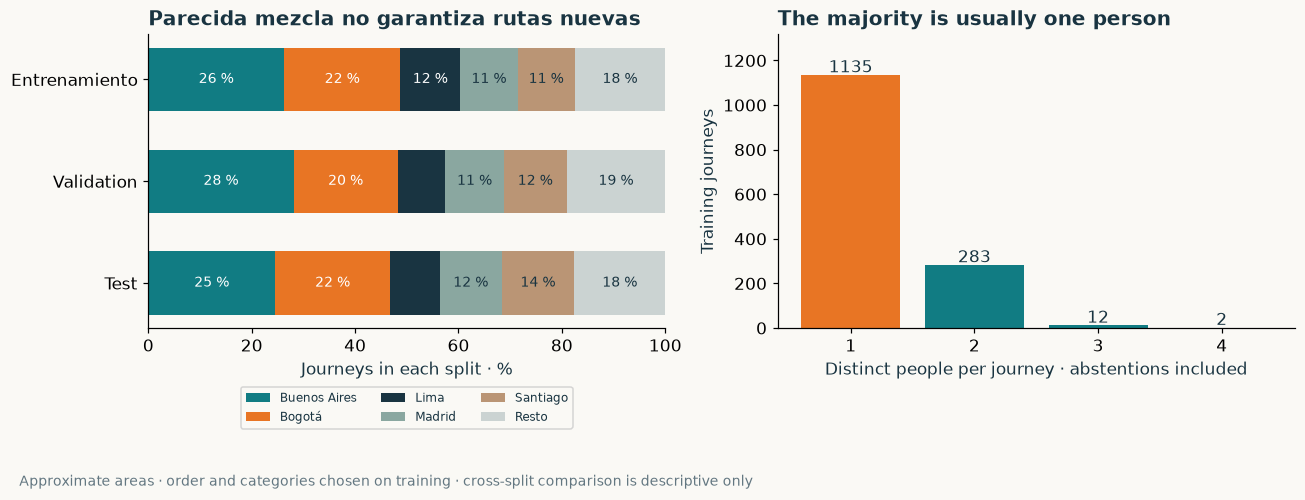

,Journeys,Longitud real mediana · km,Longitud real P95 · km,% with a defined majority,% different among majorities,% real routes with a step >1 km
Conjunto,,,,,,
Entrenamiento,1432,6.47,22.07,92.88,57.37,4.89
Validation,477,6.38,22.08,92.87,57.34,6.29
Test,477,6.58,22.49,92.87,57.56,6.92


**Additional check:** 0 estimated routes and 0 real routes are additional exact copies of the sequence of another journey. The absence of exact copies does not rule out shared streets or corridors. This random split measures performance within a known geographic mix; evaluating a new city would require holding it out explicitly.

status,With a majority,% different among majorities,No majority
length_real,,,
"(0.659, 3.656]",344,56.7 %,14
"(3.656, 6.47]",328,54.6 %,30
"(6.47, 11.11]",322,62.4 %,36
"(11.11, 41.045]",336,56.0 %,22


In [6]:
split_names={'train':'Entrenamiento','val':'Validation','test':'Test'}
top_regions=df.loc[train_ids,'region'].value_counts().head(5).index.tolist()
geo_labels=df.region.where(df.region.isin(top_regions),'Resto')
geo_counts=pd.crosstab(df.split,geo_labels).reindex(index=['train','val','test'],columns=top_regions+['Resto'],fill_value=0)
geo_pct=geo_counts.div(geo_counts.sum(axis=1),axis=0)*100
fig,axs=plt.subplots(1,2,figsize=(12,4.8))
left=np.zeros(3)
palette=[TEAL,ORANGE,INK,'#8AA7A0','#BA9575','#CBD3D2']
for region,color in zip(geo_pct.columns,palette):
    values=geo_pct[region].to_numpy()
    axs[0].barh(np.arange(3),values,left=left,color=color,label=region,height=.62)
    for i,v in enumerate(values):
        if v>=10:axs[0].text(left[i]+v/2,i,f'{v:.0f} %',ha='center',va='center',
                             color='white' if color in palette[:3] else INK,fontsize=9)
    left+=values
axs[0].set_yticks(np.arange(3),[split_names[s] for s in geo_pct.index])
axs[0].invert_yaxis();axs[0].set_xlim(0,100);axs[0].set_xlabel('Journeys in each split · %')
axs[0].set_title('Parecida mezcla no garantiza rutas nuevas')
axs[0].legend(fontsize=8,ncol=3,loc='upper center',bbox_to_anchor=(.5,-.18))
voters=df.loc[train_ids,'n_unique_annotators'].value_counts().sort_index()
axs[1].bar(voters.index.astype(str),voters.values,color=[ORANGE]+[TEAL]*(len(voters)-1))
for i,v in enumerate(voters.values):axs[1].text(i,v+12,str(v),ha='center')
axs[1].set_ylim(0,voters.max()*1.16)
axs[1].set(xlabel='Distinct people per journey · abstentions included',ylabel='Training journeys')
axs[1].set_title('The majority is usually one person')
finish(fig,'eda_04_mezcla_y_anotadores','Approximate areas · order and categories chosen on training · cross-split comparison is descriptive only')

split_rows=[]
for split in ['train','val','test']:
    ids=df.index[df.split==split];part=df.loc[ids];f=features.loc[ids]
    real=route_eda[(route_eda.split==split)&(route_eda.kind=='Real')]
    split_rows.append({'Conjunto':split_names[split],'Journeys':len(part),
        'Longitud real mediana · km':f.length_real.median()/1000,
        'Longitud real P95 · km':f.length_real.quantile(.95)/1000,
        '% with a defined majority':100*part.target_hard.notna().mean(),
        '% different among majorities':100*part.target_hard.dropna().mean(),
        '% real routes with a step >1 km':100*(real.max_step_m>1000).mean()})
split_summary=pd.DataFrame(split_rows).set_index('Conjunto')
display(split_summary.style.format({c:'{:.2f}' for c in split_summary.columns if c!='Journeys'}))

duplicate_geometry={kind:int(group.geometry_hash.duplicated().sum()) for kind,group in route_eda.groupby('kind')}
display(Markdown(f'**Additional check:** {duplicate_geometry["Estimated"]} estimated routes and '
    f'{duplicate_geometry["Real"]} real routes are additional exact copies of the sequence of another journey. '
    'The absence of exact copies does not rule out shared streets or corridors. This random split measures performance '
    'within a known geographic mix; evaluating a new city would require holding it out explicitly.'))

quartiles=pd.qcut(train_features.length_real/1000,4)
length_label=pd.crosstab(quartiles,train_features.status).reindex(columns=['same','different','tie','unknown'],fill_value=0)
length_label['With a majority']=length_label['same']+length_label['different']
length_label['% different among majorities']=100*length_label['different']/length_label['With a majority']
length_label['No majority']=length_label['tie']+length_label['unknown']
display(length_label[['With a majority','% different among majorities','No majority']].style
        .format({'% different among majorities':'{:.1f} %'})
        .set_caption('Training · four groups by real length (km) · descriptive association, not causal'))

The class proportions are similar because the split was stratified by the initial state of the labels. Frequent areas appear in all three splits, but that does not remove dependence between trips that share streets. Besides, most journeys have only one annotator: a 0 or 1 label does not imply unanimity across a broad panel.

Grouping by length helps detect whether the label is associated with trip size. It does not turn that association into a universal rule or into a criterion for dropping observations. We use it as context when interpreting the metrics.

### 1.5 How many people hold up each label?

The previous subsection counted **people who looked at** each journey. Here we count **decided votes**: abstentions
(«I don't know») and annotators who contradict themselves do not add up. This is the number that actually holds up each label.

It matters because the word «majority» suggests a panel and here there almost never is one. A journey with a single vote has a
label every bit as binary as one with three, but **we cannot know whether a second person would have agreed**.
That difference shows up in no aggregate metric; we recover it in section 8.4.

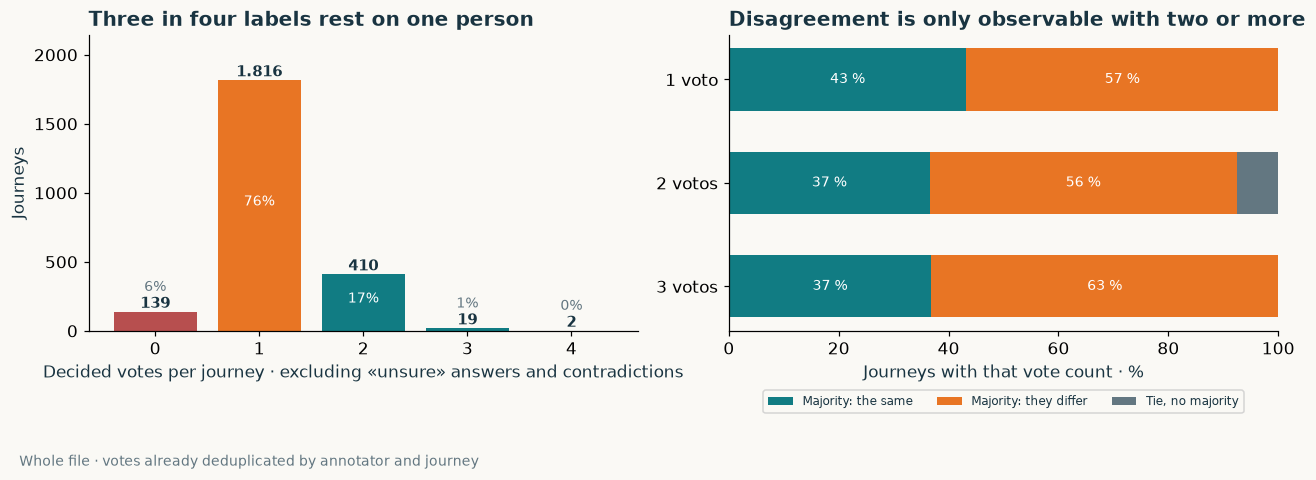

**What can and cannot be measured.** 1.816 journeys have a single vote: in those agreement between people is **unobservable**. Among the 431 with two or more, 31 end in a tie (7.2%), y 7 anotadores se contradicen sobre un mismo viaje. There are also 196 abstentions spread over 190 journeys. The brief explicitly asks for an assessment «according to their own perception»: there is no fixed criterion for how many metres of detour make two routes different. The disagreement is a property of the problem, not a defect of the data.

In [7]:
votes_total=df.n_votes.value_counts().sort_index()
votes_status=pd.crosstab(df.n_votes,df.status).reindex(columns=['same','different','tie','unknown'],fill_value=0)
fig,axs=plt.subplots(1,2,figsize=(12,4.6))
colors=[RED]+[ORANGE]+[TEAL]*(len(votes_total)-2)
axs[0].bar(votes_total.index.astype(str),votes_total.values,color=colors)
for i,v in enumerate(votes_total.values):
    axs[0].text(i,v+28,f'{v:,}'.replace(',','.'),ha='center',weight='bold',fontsize=10)
    axs[0].text(i,v*.5 if v>200 else v+150,f'{v/len(df):.0%}',ha='center',fontsize=9,
                color='white' if v>200 else MUTED)
axs[0].set_ylim(0,votes_total.max()*1.18)
axs[0].set(xlabel='Decided votes per journey · excluding «unsure» answers and contradictions',ylabel='Journeys')
axs[0].set_title('Three in four labels rest on one person')
rows=votes_status.loc[[1,2,3]] if 3 in votes_status.index else votes_status
share=rows.div(rows.sum(axis=1),axis=0)*100
left=np.zeros(len(rows))
for col,color,label in [('same',TEAL,'Majority: the same'),('different',ORANGE,'Majority: they differ'),
                        ('tie',MUTED,'Tie, no majority')]:
    values=share[col].to_numpy()
    axs[1].barh(np.arange(len(rows)),values,left=left,color=color,label=label,height=.6)
    for i,v in enumerate(values):
        if v>=8:axs[1].text(left[i]+v/2,i,f'{v:.0f} %',ha='center',va='center',color='white',fontsize=9)
    left+=values
axs[1].set_yticks(np.arange(len(rows)),[f'{k} voto' if k==1 else f'{k} votos' for k in rows.index])
axs[1].invert_yaxis();axs[1].set_xlim(0,100)
axs[1].set_xlabel('Journeys with that vote count · %')
axs[1].set_title('Disagreement is only observable with two or more')
axs[1].legend(fontsize=8,ncol=3,loc='upper center',bbox_to_anchor=(.5,-.18))
finish(fig,'eda_05_votos_por_ruta','Whole file · votes already deduplicated by annotator and journey')

ties=int((df.status=='tie').sum());multi=int((df.n_votes>=2).sum())
def miles(n):return f'{n:,}'.replace(',','.')
display(Markdown(
    f'**What can and cannot be measured.** {miles(int(votes_total.get(1,0)))} journeys have a single vote: in those '
    f'agreement between people is **unobservable**. Among the {miles(multi)} with two or more, {ties} end in a tie '
    f'({ties/multi:.1%}), y {int(df.n_conflicted_annotators.sum())} anotadores se contradicen sobre un mismo viaje. '
    f'There are also {miles(int(df.n_unknown.sum()))} abstentions spread over {miles(int((df.n_unknown>0).sum()))} journeys. '
    'The brief explicitly asks for an assessment «according to their own perception»: there is no fixed criterion for '
    'how many metres of detour make two routes different. The disagreement is a property of the problem, '
    'not a defect of the data.'))

#### And who votes? The panel is eight people, very unevenly matched

If a label is almost always held up by one person, it is worth knowing **which person**. The panel has eight annotators,
but they do not share the work evenly: the most active one made 44 times as many annotations as the least active.

Two things interest us. **How much each one weighs** — especially on journeys where nobody else voted, because there their criterion
is the label with no counterweight — and **how alike they are** when they overlap on the same journey.

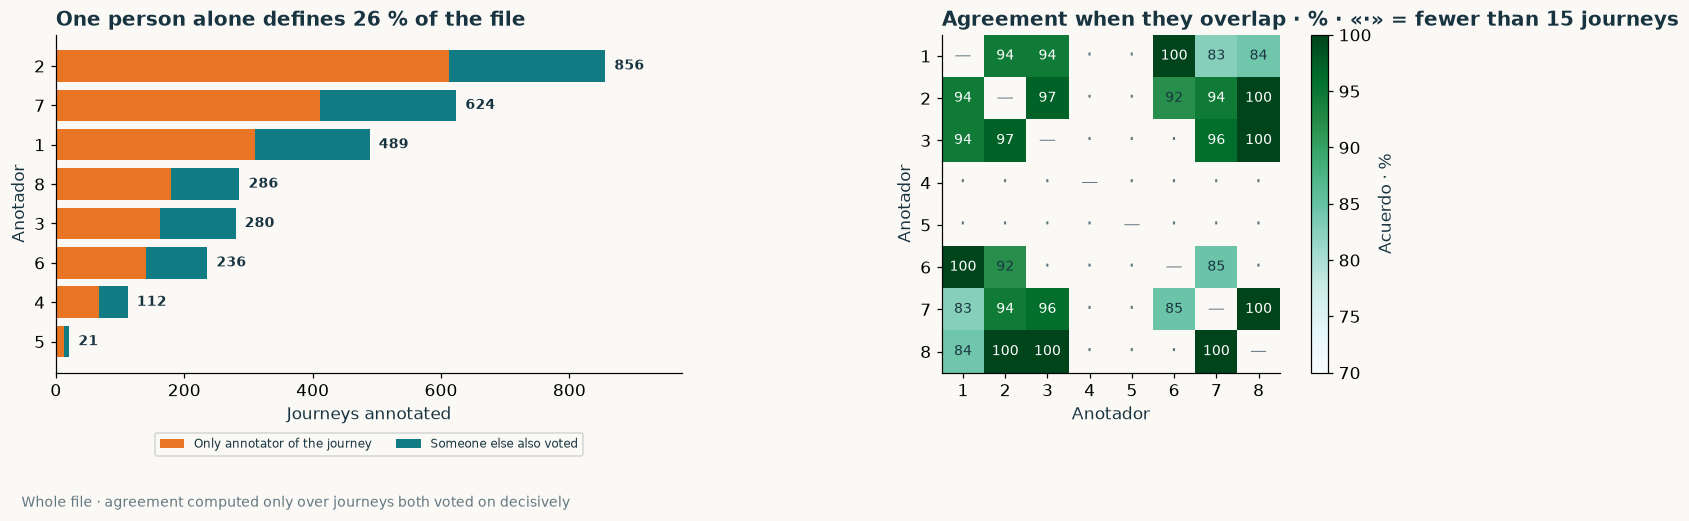

,Annotations,Journeys,Only annotator,% «they differ»,% «unsure»,Self-contradictions
Anotador,,,,,,
1,503,489,311,65.0 %,4.4 %,1
2,918,856,612,56.2 %,8.2 %,6
3,285,280,163,55.4 %,3.9 %,0
4,112,112,67,42.0 %,10.7 %,0
5,21,21,12,57.1 %,19.0 %,0
6,243,236,140,65.0 %,6.2 %,0
7,653,624,412,39.7 %,6.1 %,0
8,292,286,180,51.4 %,8.9 %,0


**Agreement discounting chance.** Two people who say «they differ» most of the time will agree a lot without sharing a criterion. Kappa corrects for that: 1 is perfect agreement, 0 is what chance would give.

,Shared journeys,Acuerdo,Kappa de Cohen
Par,,,
1 y 8,19,84.2 %,0.627
6 y 7,26,84.6 %,0.649
1 y 7,46,82.6 %,0.660
2 y 6,25,92.0 %,0.803
1 y 2,54,94.4 %,0.870
2 y 7,72,94.4 %,0.887
1 y 3,18,94.4 %,0.889
3 y 7,25,96.0 %,0.915
2 y 3,35,97.1 %,0.938


In [8]:
from itertools import combinations
from collections import defaultdict, Counter
by_journey=defaultdict(lambda: defaultdict(set))
for row in raw_records: by_journey[row['journey_id']][row['annotator']].add(row['annotation'])
decided=lambda labels: labels-{"I don't know"}

annotator_rows=[]
for ann in sorted({row['annotator'] for row in raw_records}):
    mine=[row for row in raw_records if row['annotator']==ann]
    journeys={row['journey_id'] for row in mine}
    sole=sum(1 for j in journeys if set(by_journey[j])=={ann})
    conflicted=sum(1 for j in journeys if len(decided(by_journey[j][ann]))>1)
    counts=Counter(row['annotation'] for row in mine)
    annotator_rows.append({'Anotador':ann,'Annotations':len(mine),'Journeys':len(journeys),
        'Only annotator':sole,'Alongside others':len(journeys)-sole,
        '% «they differ»':100*counts['They differ']/len(mine),
        '% «unsure»':100*counts["I don't know"]/len(mine),
        'Self-contradictions':conflicted})
panel=pd.DataFrame(annotator_rows).set_index('Anotador')

agreement=defaultdict(lambda:[0,0])
for jid,anns in by_journey.items():
    votes={a:int('They differ' in labels) for a,labels in anns.items() if len(decided(labels))==1}
    for x,y in combinations(sorted(votes),2):
        agreement[(x,y)][0]+=1
        agreement[(x,y)][1]+=int(votes[x]==votes[y])
MIN_PAIRS=15
people=sorted(panel.index)
matrix=np.full((len(people),len(people)),np.nan)
# El acuerdo bruto premia a los pares que casi siempre dicen lo mismo. Kappa descuenta la coincidencia por azar.
kappa_rows=[]
for (x,y),(n,ok) in agreement.items():
    if n<MIN_PAIRS: continue
    matrix[people.index(x),people.index(y)]=matrix[people.index(y),people.index(x)]=100*ok/n
    votes=[(int('They differ' in by_journey[j][x]),int('They differ' in by_journey[j][y]))
           for j,anns in by_journey.items()
           if len(decided(anns.get(x,set())))==1 and len(decided(anns.get(y,set())))==1]
    v=np.array(votes);po=(v[:,0]==v[:,1]).mean();p1,p2=v[:,0].mean(),v[:,1].mean()
    pe=p1*p2+(1-p1)*(1-p2)
    kappa_rows.append({'Par':f'{x} y {y}','Shared journeys':n,'Acuerdo':100*po,
                       'Kappa de Cohen':(po-pe)/(1-pe)})
kappa=pd.DataFrame(kappa_rows).sort_values('Kappa de Cohen').set_index('Par')

fig,axs=plt.subplots(1,2,figsize=(13,5))
order=panel.sort_values('Annotations').index
axs[0].barh([str(a) for a in order],panel.loc[order,'Only annotator'],color=ORANGE,label='Only annotator of the journey')
axs[0].barh([str(a) for a in order],panel.loc[order,'Alongside others'],left=panel.loc[order,'Only annotator'],
            color=TEAL,label='Someone else also voted')
for i,a in enumerate(order):
    axs[0].text(panel.loc[a,'Journeys']+14,i,f"{panel.loc[a,'Journeys']}",va='center',fontsize=9,weight='bold')
axs[0].set_xlim(0,panel.Journeys.max()*1.14)
axs[0].set(xlabel='Journeys annotated',ylabel='Anotador')
axs[0].set_title('One person alone defines 26 % of the file')
axs[0].legend(fontsize=8,ncol=2,loc='upper center',bbox_to_anchor=(.5,-.16))
im=axs[1].imshow(matrix,cmap='BuGn',vmin=70,vmax=100)
axs[1].set_xticks(range(len(people)),people);axs[1].set_yticks(range(len(people)),people)
for i in range(len(people)):
    for j in range(len(people)):
        if i==j: axs[1].text(j,i,'—',ha='center',va='center',color=MUTED)
        elif np.isnan(matrix[i,j]): axs[1].text(j,i,'·',ha='center',va='center',color=MUTED,fontsize=14)
        else: axs[1].text(j,i,f'{matrix[i,j]:.0f}',ha='center',va='center',fontsize=9,
                          color='white' if matrix[i,j]>92 else INK)
axs[1].set(xlabel='Anotador',ylabel='Anotador')
axs[1].set_title(f'Agreement when they overlap · % · «·» = fewer than {MIN_PAIRS} journeys')
fig.colorbar(im,ax=axs[1],fraction=.046,label='Acuerdo · %')
finish(fig,'eda_06_panel_anotadores',
       'Whole file · agreement computed only over journeys both voted on decisively')

display(panel[['Annotations','Journeys','Only annotator','% «they differ»','% «unsure»','Self-contradictions']]
        .style.format({'% «they differ»':'{:.1f} %','% «unsure»':'{:.1f} %'}))
display(Markdown('**Agreement discounting chance.** Two people who say «they differ» most of the time will agree a lot '
 'without sharing a criterion. Kappa corrects for that: 1 is perfect agreement, 0 is what chance would give.'))
display(kappa.style.format({'Acuerdo':'{:.1f} %','Kappa de Cohen':'{:.3f}'}))

**The distribution is not balanced.** Annotator 2 signs 918 annotations — 30 % of the file — across 856 journeys, and on
**612 of them is the only person who voted**: their criterion, uncontrasted, fixes 26 % of the dataset's labels.
Adding the three most active (2, 7 and 1) reaches 1,335 of the 1,897 single-annotator journeys. At the other end,
annotator 5 made 21 annotations.

**And personal criteria differ.** Annotator 1 marks «they differ» 65 % of the time; annotator 7, 39.7 %. That is
25 points of difference between two people who saw nearly 500 and more than 600 journeys respectively. It is not a small
sample nor a coincidence: it is a different tolerance threshold.

That gap is confirmed when we cross them. Among the pairs with enough shared journeys, **1 and 7 are precisely the ones who
agree least: 82.6 % over 46 journeys**, while other pairs reach 94-100 %. Cells marked with «·»
have fewer than 15 journeys in common and are not interpreted; with 4 or 8 comparisons, a 100 % means nothing.

**The consequence for the model.** The target is not «do these routes look alike?» but «would this particular person say
they look alike?». In 80 % of cases that person is a single one, and with high probability it is annotator 2 or 7.
The model learns, in part, **their** tolerance threshold. If the panel changes tomorrow, the target changes, and the accuracy
measured here does not transfer automatically.

**Raw agreement overstates the case**, because two people who say «they differ» most of the time will coincide a lot
without sharing a criterion. Cohen's kappa discounts that expected coincidence and ranks the pairs
differently: 1 and 7 drop to **0.66**, and 1 and 8 to **0.63**, against several pairs above 0.87. These are values
usually described as «substantial» agreement, not «almost perfect»: there is a shared criterion, but with real slack.

This reinforces what §1.5 and §8.4 already said from another angle: the dominant limitation of this prototype is not the
model's capacity, but **how many people hold up each label and with what criterion**. §8.6 closes the
question from the other side: which annotator the model we trained resembles most.

### 1.6 So, do we need to normalise?

**Yes to making distances and sampling comparable; no to dividing everything by length.** They are different operations:

| What we want to solve | Treatment and reason | Prototype status |
|---|---|---|
| Latitude and longitude are in degrees | Project both routes to a shared local system in metres. One degree of longitude is not the same distance at every latitude. | Implemented for the geometric features |
| Routes have different point densities | Resample by length and remove consecutive duplicates when building the polyline. That way a densely sampled area does not weigh more just for having more points. | Implemented; it does not fill gaps with real information |
| A detour can be large in metres or relative to the trip | Keep measurements in metres **and** versions divided by a shared length scale. | The extended vector includes both; the baseline includes lengths, absolute distances and relative length difference |
| Variables with very different units enter a neural network | Standardise using the mean and standard deviation computed on training only. Apply those same parameters to validation and test. | Implemented in the neural head over embeddings; afterwards clipped to [−10, 10] |
| Variables with different units enter XGBoost | Its trees compare each variable against its own thresholds; they do not need z-scores to put metres and proportions on a common scale. | Geometric and hybrid inputs are not standardised |
| Proportions and IoU are already dimensionless | Keep their values between 0 and 1; do not divide by kilometres again. | Implemented |
| There is a tail of long trips | Use logarithmic axes to see it. Transforming variables or trimming extremes would be a separate decision, to be validated. | The log scale in the EDA is purely visual; no inputs were changed and no extremes removed |

The common scale we use is

$$s=\max\left(\frac{L_e+L_r}{2},1\text{ m}\right),\qquad
d_{\mathrm{rel}}=\frac{d}{s},\qquad
\Delta L_{\mathrm{rel}}=\frac{L_r-L_e}{s}.$$

The 1-metre floor protects the division in degenerate cases; none of the valid routes in this file comes close to it. The value $s$ is computed from the two routes of the journey itself, without learning from other journeys or their labels.

For example, a mean separation of **100 m** is **10 %** of a **1 km** scale, and **0.5 %** of a **20 km** scale. These are complementary readings: the second avoids treating a proportionally small detour the same as a large one; the first preserves the fact that 100 metres can be a different street in either case. **If we kept only the relative version, we could hide a difference a person considers important.**

We do not centre, rotate or rescale each route separately to unit size: that could make trips that genuinely pass through different places look identical. The shared projection preserves the separation between the two.

For the neural head, by contrast, standardising a component $x_k$ means

$$z_k=\frac{x_k-\mu_{k,\mathrm{train}}}{\sigma_{k,\mathrm{train}}}.$$

This is a rescaling of the network's inputs, not a normalisation of kilometres. Means and standard deviations are not recomputed on validation or test, and constant components are handled without dividing by zero. The vocabulary and the encoder are also fitted exclusively within the training set.

**What we take from the EDA:** no null imputation is needed; units and sampling density do need respecting, absolute and relative scales both need keeping, and we should remember that trace gaps and the scarcity of votes limit what we can learn. Any further cleaning or change of representation would be evaluated as a new experiment, without silently replacing the results that follow.

In [9]:
# Informe ligero para reproducir las cifras sin extraerlas de las figuras.
eda_report={
 'scope':'Quality: whole file. Distributions and label relationships: train. Split comparison: descriptive.',
 'added_after_model_evaluation':True,
 'raw_rows':len(raw_records),'unique_journeys':len(df),
 'missing_fields':missing_report.to_dict(orient='index'),
 'coordinate_quality':quality.to_dict(),
 'derived_quality':feature_checks.to_dict(),
 'train_length_km':length_summary.to_dict(orient='index'),
 'sampling':sampling_summary.to_dict(orient='index'),
 'paired_point_counts':{'different':different_counts,'total':len(df),
     'estimated_median':float(point_counts.n_estimated.median()),'real_median':float(point_counts.n_real.median()),
     'example_journey_id':sampling_example,'example_estimated_points':323,'example_real_points':97},
 'split_summary':split_summary.to_dict(orient='index'),
 'exact_duplicate_routes':duplicate_geometry,
 'largest_real_train_step':{'journey_id':eda_jid,'step_m':float(worst.max_step_m),'n_points':int(worst.n_points)},
 'transformations_changed':False}
(R/'eda.json').write_text(json.dumps(eda_report,indent=2,ensure_ascii=False,default=int))

4738

## 2. The target represents human judgement, uncertainty included

For a journey $j$, we use

$$p_j=\frac{\text{valid annotators saying «they differ»}}{\text{valid annotators who make a decision}}.$$

If two people say «they differ» and one says «the same», the target is $2/3$. We do not claim this is the physical probability that the routes are different: it is an estimate of this panel's judgement. With a single vote there is uncertainty too, even though $p_j$ is 0 or 1.

We train with cross-entropy against $p_j$, with **equal weight per journey**. Ties contribute a target of 0.5. Journeys with no valid votes contribute no supervised loss; their training routes can still take part in unlabelled pretraining.

To evaluate binary classification we use the defined majority, $y_j=1[p_j>0.5]$, excluding ties and cases with no valid vote. We also measure the probabilistic loss against the votes, ties included.

> The test set contains 477 journeys, but only 443 have a defined majority. Binary performance refers to **92.9 %** of the test set. We do not know the accuracy on the other 34 journeys.

All annotations for a journey stay together. There are no exactly duplicated geometry pairs across identifiers. The split was frozen before evaluating models and kept when cleaning the votes. This is a random test within the mix of cities; **it does not demonstrate generalisation to a new city**.

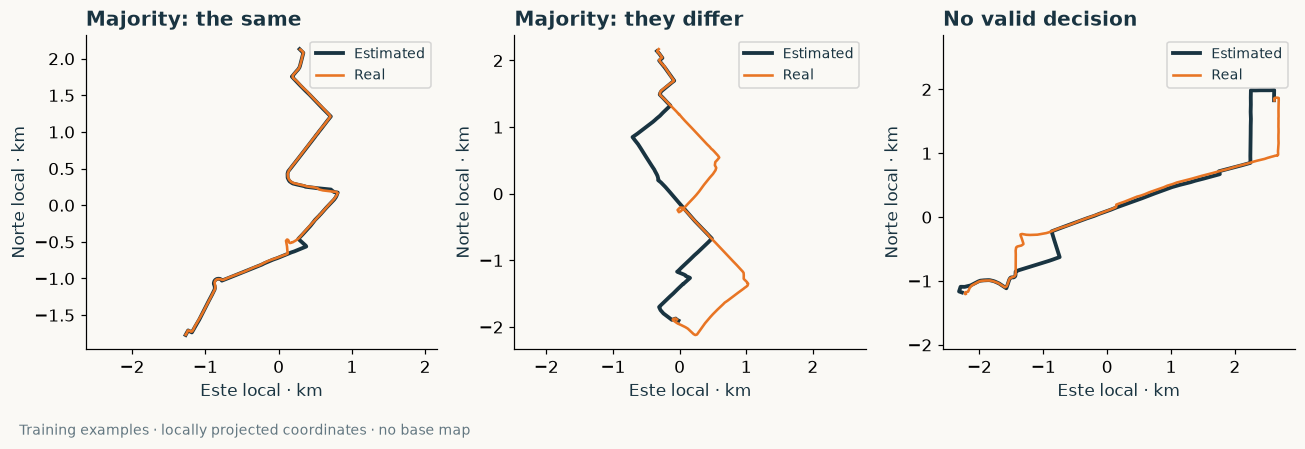

In [10]:
fig,axs=plt.subplots(1,3,figsize=(12,4.3))
for ax,status,title in zip(axs,['same','different','unknown'],['Majority: the same','Majority: they differ','No valid decision']):
    ids=df.index[(df.split=='train')&(df.status==status)]
    # Median case by length: a deterministic pick, not chosen by model accuracy.
    jid=features.loc[ids,'length_real'].sort_values().index[len(ids)//2]
    a,b=project_pair(*routes[jid])
    ax.plot(a[:,0]/1000,a[:,1]/1000,color=INK,lw=2.5,label='Estimated')
    ax.plot(b[:,0]/1000,b[:,1]/1000,color=ORANGE,lw=1.7,label='Real')
    ax.set_title(title);ax.set_aspect('equal',adjustable='datalim');ax.set_xlabel('Este local · km')
    ax.set_ylabel('Norte local · km');ax.legend(fontsize=9)
finish(fig,'02_ejemplos_reales','Training examples · locally projected coordinates · no base map')

## 3. The first representation: measure before compressing

Coordinates are projected to metres in a local system shared by **both** routes. We do not centre, rotate or scale each one separately: that could turn different streets into apparently identical shapes.

For a position $x$ on route $A$ we compute $d(x,B)=\min_{y\in B}\|x-y\|$. The nearest position may lie **in the middle of a segment**, even if no GPS point was recorded there.

We repeat this in both directions. Means and proportions are approximated using positions equally spaced by length (every 20 metres, minimum 16 and maximum 1,600). That way each metre carries roughly the same weight. The precision of this approximation is limited on very long routes or with very short detours.

**Baseline:** eight variables — lengths, relative difference, endpoint separation, directional mean distances and discrete Hausdorff — plus XGBoost.

**The extended vector:** 42 variables. It adds 95th percentiles, relative versions, proportions and continuous stretches further than 20/50/100 metres away, corridor IoU, straightness, turns and discrete Fréchet over 64 points per route.

Three examples clarify what each measurement adds. **The mean** describes the usual separation; **the maximum of the minimum distances in both directions — Hausdorff —** can detect a significant detour even if brief, but is sensitive to a single anomalous point. **A proportion of 0.20 beyond 50 metres** means roughly a fifth of that route's length lies far from the other, even if the mean is small.

For **IoU** we draw a corridor around each route and divide the intersection area by the union area. Near 1 there is a lot of overlap; near 0, little. Width matters: 100-metre corridors can overlap even when the cars drive down different streets. This measurement does not consult the road network.

$$\Delta L_{\mathrm{rel}}=\frac{L_{\mathrm{real}}-L_{\mathrm{estimated}}}{(L_{\mathrm{real}}+L_{\mathrm{estimated}})/2}.$$

We keep absolute and relative values. IoU is already normalised; we do not divide it by length again.

**Where does XGBoost learn?** These measurements are computed without learning from the labels. Afterwards, the model combines decision trees learned from the votes: a 50-metre separation can be read differently depending on length, endpoints and the other variables. We do not hand-impose a single rule of «if it exceeds 50 metres, they are different».

> Sharing all the points does not imply traversing them in the same order. Hausdorff and IoU can ignore that difference; Fréchet adds ordering information. Their discrete versions are approximations, not exact measurements of a continuous curve.

,Hausdorff (m),IoU corredor 50 m,Discrete Fréchet (m)
0,0.0,1.0,1000.0


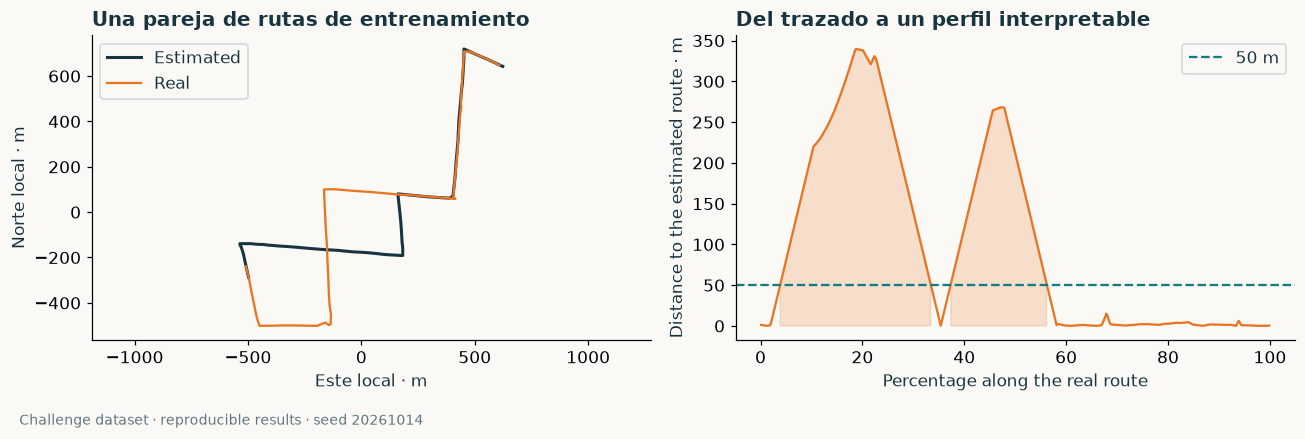

In [11]:
from routes.features import features_xy
# Conceptual check: two identical lines traversed in opposite directions.
a=np.array([[0.,0.],[1000.,0.]])
demo=features_xy(a,a[::-1])
display(pd.DataFrame([{'Hausdorff (m)':demo['hausdorff_discrete_m'],
                      'IoU corredor 50 m':demo['buffer_iou_50m'],
                      'Discrete Fréchet (m)':demo['frechet_64_m']}]))

from shapely import distance,points
ids=df.index[(df.split=='train')&(df.status=='different')]
jid=(features.loc[ids,'mean_real_to_est_m']-100).abs().sort_values().index[0]
a,b=project_pair(*routes[jid]);la,lb=clean_line(a),clean_line(b)
positions=sample_line(lb,400,midpoints=True)
distances=distance(points(positions),la)
fig,axs=plt.subplots(1,2,figsize=(12,4.2))
axs[0].plot(a[:,0],a[:,1],color=INK,lw=2,label='Estimated')
axs[0].plot(b[:,0],b[:,1],color=ORANGE,lw=1.5,label='Real')
axs[0].set_aspect('equal',adjustable='datalim');axs[0].legend();axs[0].set_title('Una pareja de rutas de entrenamiento')
axs[0].set_xlabel('Este local · m');axs[0].set_ylabel('Norte local · m')
axs[1].plot((np.arange(400)+.5)/400*100,distances,color=ORANGE)
axs[1].axhline(50,color=TEAL,ls='--',label='50 m')
axs[1].fill_between((np.arange(400)+.5)/400*100,distances,where=distances>50,color=ORANGE,alpha=.2)
axs[1].set_xlabel('Percentage along the real route');axs[1].set_ylabel('Distance to the estimated route · m')
axs[1].set_title('Del trazado a un perfil interpretable');axs[1].legend()
finish(fig,'03_perfil_de_desviacion')


## 4. From the drawing of a route to the streets it can actually use

### 4.1 An API failed; the hypothesis was still testable

The first attempt with Overpass only got a small area of Madrid, with no complete journeys. That was a map access problem, not evidence against graphs. We now download full extracts for eight countries from [Geofabrik](https://download.geofabrik.de/), with **OpenStreetMap** data. We record the date and fingerprint of each file, and clip an area around the traces with a margin of 0.08 degrees per side. The margin makes it easier to drive around the trip, but does not guarantee every possible detour is included.

**A current map does not reconstruct a historical one.** Streets, accesses or directions may have changed since these trips. We also have no timestamps and no observed traffic. That is why the duration variables we add are estimates under a fixed car profile, not the real time each vehicle took.

### 4.2 First we need to know which streets each route used

A noisy coordinate can land between two streets. Assigning each point to the nearest street independently can produce impossible jumps. We use the *map matching* service of [OSRM](https://project-osrm.org/docs/v5.24.0/api/#match-service): it looks for a road sequence compatible with the points and returns segments, rejected points and a confidence measure.

The engine runs locally with a pinned version and the `car.lua` profile, which encodes directions and the turn restrictions that profile supports and the map contains. **We do not replace each journey with the fastest route between its origin and destination:** that would erase precisely the detours we want to detect.

To limit computation we keep up to 300 **observed** points, chosen by cumulative distance, endpoints included. We invent no intermediate observations. We assume a GPS accuracy of 15 metres to generate candidates; the file does not provide that accuracy. This choice can influence the result and deserves a sensitivity analysis. Without timestamps, we impose no observed speeds between points.

OSRM's confidence is not a calibrated probability for this dataset. We call a route a «complete match under our rule» when it has a single sub-trace, at least 90 % of selected points accepted and confidence ≥ 0.5. It is an explicit diagnostic rule, not a guarantee of truth. **No journey is removed from the benchmark for failing it**: we keep quality indicators and missing values where appropriate.

### 4.3 What we measure on the graph and what each number means

A directed edge represents a street segment in one direction. That lets us tell sharing a street apart from driving it in opposite directions. We build two related representations:

| Representation | What it is used for | Relevant limitation |
|---|---|---|
| OSRM, with the car profile | Infer the trace and estimate the length and duration of its segments | Current map, fixed profile; no traffic and no historical duration |
| Directed graph of OSM nodes, weighted in metres | Minimum distance from the nodes of one trace to those of the other | Respects simplified static directions and accesses; **does not model turn restrictions**, conditional accesses or ferries |

For a route A and a route B, on this second graph we define

$$d_G(u,B)=\min_{v\in V_B}\operatorname{dist}_G(u,v).$$

The distance follows the arrows. That is why $d_G(u,B)$ and $d_G(v,A)$ need not coincide. We compute both directions with multi-target Dijkstra, run over the reversed graph. The target is **any node of the other trace**; we do not require it to be at the same stage of the trip.

This is a node-level approximation, not the exact distance between all continuous points of two curves. We average with length weights: each endpoint node is assigned half the metres actually driven on that segment according to OSRM. A stretch split by several GPS points does not count its full length again at each split. On partial segments we approximate the position using the nodes of the full edge; that can introduce error near endpoints or on long edges.

We store the mean, 95th percentile, maximum and proportion of length beyond 50, 100 and 500 metres, in both directions. To limit search cost, we truncate distances at 10 km and add the fraction that exceeds that limit or is unreachable. **With truncation, the mean and the maximum are lower bounds**, not exact distances. A clip of the extract can also cause unreachability.

Street overlap uses unique directed edges and their lengths:

$$\operatorname{IoU}_{\mathrm{streets}}(A,B)=
\frac{\sum_e\min(w_A(e),w_B(e))}{\sum_e\max(w_A(e),w_B(e))}.$$

Here $w_A(e)$ is the edge length if it appears in A and zero otherwise. A repeated edge counts once. Touching part of an edge counts as touching all of it: this approximation can overestimate overlap if the routes use different portions of the same edge. This IoU also does not represent global ordering or how many times a street is driven. It complements the ordering and geometry measures we already have.

Finally we keep estimated lengths and durations of the **matched portions** and their quality indicators. We only compute relative length and time differences as comparable totals when both routes satisfy the match rule. For instance:

$$\Delta T_{\mathrm{rel}}=\frac{\hat T_r-\hat T_e}{\max[(\hat T_r+\hat T_e)/2,1\text{ s}]}.$$

The division compares the relative overrun; we also keep the individual values. IoU and the proportions are already normalised. **The label is still the human judgement about similarity**, not «it takes longer»: the model has to learn whether these variables help predict that judgement.

### 4.4 Coverage is a result that has to be shown

This extension was proposed after inspecting the original test set. A new protocol was frozen before obtaining its results and the same journeys were kept. Its test metrics are **exploratory**, not an independent confirmation of an improvement.


**Map imported:** 12,296,247 OSM nodes; **simplified drivable graph:** 6,959,330 nodes and 12,839,192 edges. We build **36 road and quality variables** per journey.

,Journeys,Some match on both,Both satisfy the rule
split,,,
train,1432,1432,864
val,477,477,273
test,477,477,261


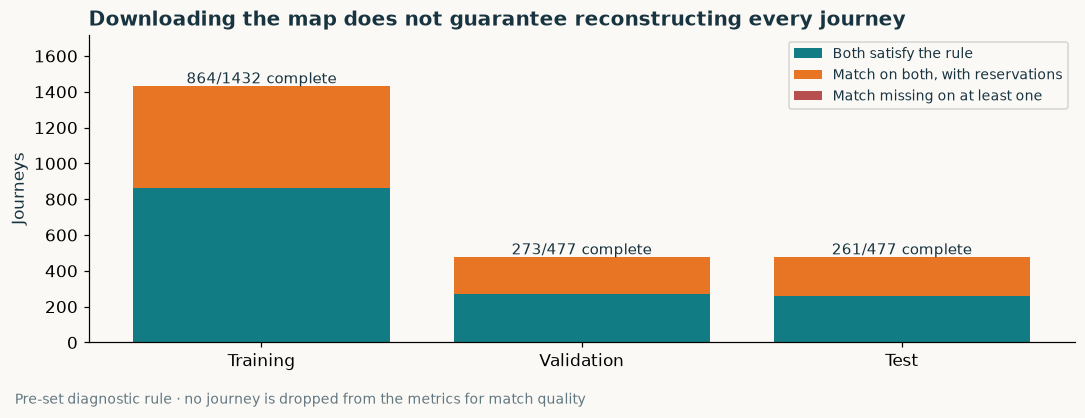

In [12]:

RG=ROOT/'results/routes_graph'
def read_graph(name):return json.loads((RG/name).read_text())
graph_manifest=read_graph('feature_manifest.json')
extract_manifest=read_graph('extract_manifest.json')
node_manifest=read_graph('node_graph.json')
graph_metrics=read_graph('metrics.json')
graph_frozen=read_graph('frozen_selection.json')
graph_details=read_graph('training_details.json')
graph_features=pd.read_json(ROOT/'data/cache/roads/graph_features.json',orient='index').loc[df.index]
graph_predictions=pd.DataFrame(read_graph('predictions.json')).set_index('journey_id').loc[df.index]
display(Markdown(f'**Map imported:** {extract_manifest["nodes"]:,} OSM nodes; '
    f'**simplified drivable graph:** {node_manifest["nodes"]:,} nodes and {node_manifest["directed_edges"]:,} edges. '
    f'We build **{graph_manifest["n_features"]} road and quality variables** per journey.'))
coverage=pd.DataFrame(graph_manifest['coverage']).set_index('split')
display(coverage[['n','both_any_match','both_reliable']].rename(columns={
    'n':'Journeys','both_any_match':'Some match on both','both_reliable':'Both satisfy the rule'}))
fig,ax=plt.subplots(figsize=(10,4))
x=np.arange(3);n=coverage.n.to_numpy();good=coverage.both_reliable.to_numpy();anymatch=coverage.both_any_match.to_numpy()
ax.bar(x,good,color=TEAL,label='Both satisfy the rule')
ax.bar(x,anymatch-good,bottom=good,color=ORANGE,label='Match on both, with reservations')
ax.bar(x,n-anymatch,bottom=anymatch,color=RED,label='Match missing on at least one')
for i in x:ax.text(i,n[i]+15,f'{good[i]}/{n[i]} complete',ha='center',fontsize=10)
ax.set_xticks(x,['Training','Validation','Test']);ax.set_ylabel('Journeys');ax.set_ylim(0,n.max()*1.2)
ax.set_title('Downloading the map does not guarantee reconstructing every journey');ax.legend(fontsize=9,loc='upper right')
finish(fig,'04_cobertura_grafo','Pre-set diagnostic rule · no journey is dropped from the metrics for match quality')


## 5. Learning a vector: what t2vec means in this prototype

### 5.1 The starting problem: a list of points has no fixed size

One route can have 100 points and another 300. **This happens in the dataset:** 2,376 of the 2,386 journeys have a different number of points between their two traces. For instance, journey `7f29deb0-5c8c-11ec-8622-eff6f2c898b6` contains 323 estimated points and 97 real ones. More points does not mean more kilometres or a different route: it can simply mean denser sampling.

We want a function $f_\theta$ that turns any admissible sequence into a vector of the same size:

$$T=(p_1,\ldots,p_n)\quad\longmapsto\quad z=f_\theta(T)\in\mathbb R^d.$$

Here $n$ can change, while $d$ is fixed when designing the network. The parameter $\theta$ stands for the weights we learn. Having the same size lets us compare vectors and feed a classifier. **It does not guarantee those vectors preserve the differences the business cares about:** that has to be checked.

There are three distinct levels: the GPS coordinate; the map cell we assign that coordinate to; and the learned vector for the whole trajectory. There is also a learned vector per cell, which is the encoder's numerical input. That local vector should not be confused with the final summary of the trip.

**What the encoder does as it reads:** it starts with a numerical memory, reads A and updates it; then reads C and combines what it remembers with C; then does the same with D. When it finishes it returns that memory. Our GRU reads in both directions and concatenates its summaries. It does not assign one component per point: the whole sequence influences a fixed-size vector. A sequence of 3 cells and one of 30 both produce 64 numbers. The 64-point preprocessing cap and the 64 vector components are two separate decisions that happen to coincide numerically here.

It is worth laying out the three components before going further:

| Component | Input | Output | What it is used for |
|---|---|---|---|
| Encoder | One route, expressed as a sequence of cells | A vector of 64 numbers | Summarise the route |
| Reconstruction decoder | That vector and the context of previous cells | Predictions of successive cells, including END | Provide a signal to train the encoder |
| Pair classifier | The two vectors and their comparisons | Probability of «they differ» | Solve the challenge task |

**The decoder is not the classifier.** It is trained in the first phase and takes no part in the final label prediction.

### 5.2 The original idea: learning without asking for human labels

[Li et al. (2018)](https://xiucheng.org/assets/pdfs/icde18-t2vec.pdf) propose representing trajectories with an encoder-decoder and an objective that accounts for the spatial proximity of cells. Their original task is trajectory similarity and search; here we add a classification based on human annotations.

Consider a sequence of cells **A → B → C → D**. We generate a degraded version, say **A → C → D**, and perturb some positions. The encoder summarises that version; the decoder tries to reconstruct the original sequence. We know the answer because we kept the trajectory before altering it. This is **self-supervised** learning: the training signal comes from the data, with no human votes.

In our case points are removed: no `[MASK]` symbol is left marking where they are missing. The objective is to reconstruct the full original cell sequence, not just guess the removed point. If the decoder predicts **A → C → C → D**, we compare those predictions with **A → B → C → D** and adjust the weights of both networks to reduce the loss. Nor do we ask it to interpolate exact GPS coordinates: we predict the cells of the discretised representation.

The task forces it to preserve useful patterns despite noise and irregular sampling. It is no guarantee of recovering streets we never observed: if several routes explain the surviving points, the model can get it wrong. Proximity between cells informs about geography, not about bridges, one-way streets or road connections.

### 5.3 What «penalising by distance» means

Suppose the next point corresponds to cell B. Predicting an adjacent cell and predicting one several kilometres away should not be treated exactly the same. In our implementation the target is spread across eight nearby cells:

$$q(c\mid B)=\frac{\exp[-d(c,B)/250]}{\sum_{u\in N_8(B)}\exp[-d(u,B)/250]},\qquad c\in N_8(B).$$

Distances are in metres and $N_8(B)$ includes the cell itself. The correct cell gets the largest weight; nearby ones get less. To avoid evaluating every cell at each step, our prototype adds 64 sampled negative cells and computes a loss over that subset. **This sampled normaliser is neither the full softmax nor an exact reproduction of the paper's NCE approximation.** We do not read its value as an exact probability over the whole route.

The decoder uses *teacher forcing*: when predicting the next cell during training it receives the correct previous cell. This makes reconstruction easier to learn, but free-running reconstruction can accumulate errors. Our end goal is to exploit the encoder, not to evaluate a trajectory generator.

### 5.4 What was implemented: a small version, with explicit decisions

We implement a **reduced adaptation**, not an exact reproduction of their architecture nor a measurement of the paper's performance:

1. We discretise positions into 250-metre UTM cells, identified also by their zone.
2. The vocabulary is learned from a fraction of the training set only. The internal validation set for pretraining contains different journeys.
3. The bidirectional GRU encoder compresses each route into 64 numbers.
4. A GRU decoder tries to reconstruct the original sequence from a version with points removed and small GPS perturbations.
5. The loss favours the true cells and their spatial neighbours. It uses eight neighbours and 64 negatives per position, with a sampled normaliser.
6. We freeze the encoder and train a small classifier on the human votes.

The model has smaller dimensions, a different grid and projection, 12 epochs as a maximum budget, and does not include the paper's separate cell pretraining. It uses teacher forcing in the decoder. The sampled reconstruction loss serves as a diagnostic, not as an exact log likelihood over the full vocabulary.

**There are two different outputs:** the pretraining decoder reconstructs trajectories; the supervised head produces the probability of «they differ».

We do not use the estimated and real routes as a positive pair during pretraining: they might be precisely the ones that differ.

The vocabulary and encoder weights are learned from **2,578 trajectories across 1,289 training journeys**; another 143 training journeys serve as internal validation for this phase. Each trace is capped at 64 points before discretising. The encoder uses 32-component cell embeddings and a bidirectional GRU with 32 units per direction: the result is 64 components per route. The paper includes a cell pretraining step that is omitted here. The [original repository](https://github.com/boathit/t2vec) makes it possible to tell the published implementation apart from this adaptation.

Those 64 numbers **are not 64 measurements with known names**. The model decides how to spread information across them. That is why we cannot point at one component and claim it represents «the maximum detour». Our geometric vector does have that interpretability, because we defined it explicitly.

### 5.5 From one route's vector to a decision about two routes

For each pair we build $[z_e,z_r,|z_e-z_r|,z_e\odot z_r]$: 256 values. The head is a network with one hidden layer, dropout and a sigmoid output. We also try combining those 256 values with the 42 interpretable measurements and using XGBoost.

The first 128 values keep **both full vectors**. The next 64 make per-component differences explicit; the last 64 are component-wise products. Those products alone are not equivalent to a calibrated similarity. They are additional inputs the classifier can use or ignore.

In this second phase we do use the human votes. For a journey with target $p_j$, the classifier predicts $\hat p_j=\sigma(h_\phi(x_j))$ and we minimise

$$\mathcal L_j=-p_j\log\hat p_j-(1-p_j)\log(1-\hat p_j).$$

The encoder stays frozen: we learn $\phi$, the head's weights, without modifying $\theta$. The reconstruction decoder no longer takes part. So there are two successive objectives: **representing a trajectory** and **learning how people judge a pair**. Solving the first well does not automatically solve the second.

### 5.6 What the experiment allows us to conclude

Our variant gets worse metrics than the geometric measurements. This evaluates that specific configuration. Corpus size, the 250-metre resolution, the training budget and unseen cells are possible explanations, not demonstrated causes. Separating them would require controlled ablations. Nor have we compared «concatenation only» against «differences only»; our input contains both.

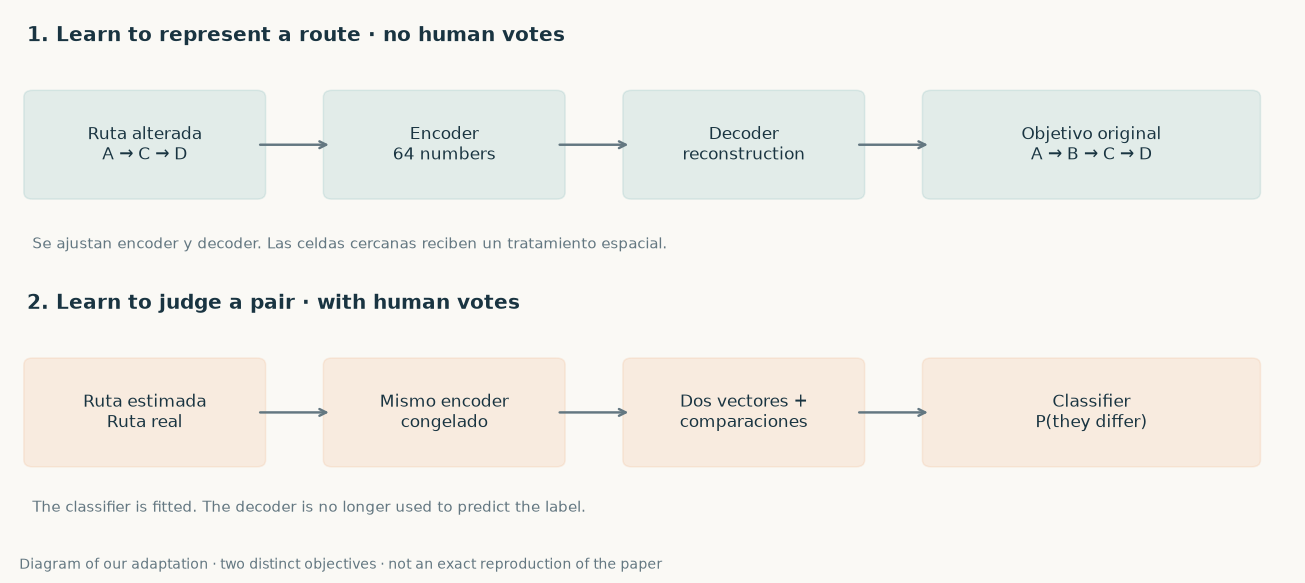

In [13]:
fig,ax=plt.subplots(figsize=(12,5.6));ax.set_xlim(0,12);ax.set_ylim(0,6);ax.axis('off')
def diagram_box(x,y,w,h,text,color):
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle='round,pad=.08',facecolor=color,alpha=.1,edgecolor=color))
    ax.text(x+w/2,y+h/2,text,ha='center',va='center',fontsize=11,color=INK)
def arrow(x1,y1,x2,y2):ax.annotate('',xy=(x2,y2),xytext=(x1,y1),arrowprops={'arrowstyle':'->','color':MUTED,'lw':1.6})
ax.text(.15,5.65,'1. Learn to represent a route · no human votes',fontsize=13,weight='bold')
diagram_box(.2,3.9,2.1,1.1,'Ruta alterada\nA → C → D',TEAL)
diagram_box(3,3.9,2.1,1.1,'Encoder\n64 numbers',TEAL)
diagram_box(5.8,3.9,2.1,1.1,'Decoder\nreconstruction',TEAL)
diagram_box(8.6,3.9,3.0,1.1,'Objetivo original\nA → B → C → D',TEAL)
for x1,x2 in [(2.3,3),(5.1,5.8),(7.9,8.6)]:arrow(x1,4.45,x2,4.45)
ax.text(.2,3.25,'Se ajustan encoder y decoder. Las celdas cercanas reciben un tratamiento espacial.',fontsize=10,color=MUTED)
ax.text(.15,2.55,'2. Learn to judge a pair · with human votes',fontsize=13,weight='bold')
diagram_box(.2,.8,2.1,1.1,'Ruta estimada\nRuta real',ORANGE)
diagram_box(3,.8,2.1,1.1,'Mismo encoder\ncongelado',ORANGE)
diagram_box(5.8,.8,2.1,1.1,'Dos vectores +\ncomparaciones',ORANGE)
diagram_box(8.6,.8,3.0,1.1,'Classifier\nP(they differ)',ORANGE)
for x1,x2 in [(2.3,3),(5.1,5.8),(7.9,8.6)]:arrow(x1,1.35,x2,1.35)
ax.text(.2,.2,'The classifier is fitted. The decoder is no longer used to predict the label.',fontsize=10,color=MUTED)
finish(fig,'05a_t2vec_dos_etapas','Diagram of our adaptation · two distinct objectives · not an exact reproduction of the paper')

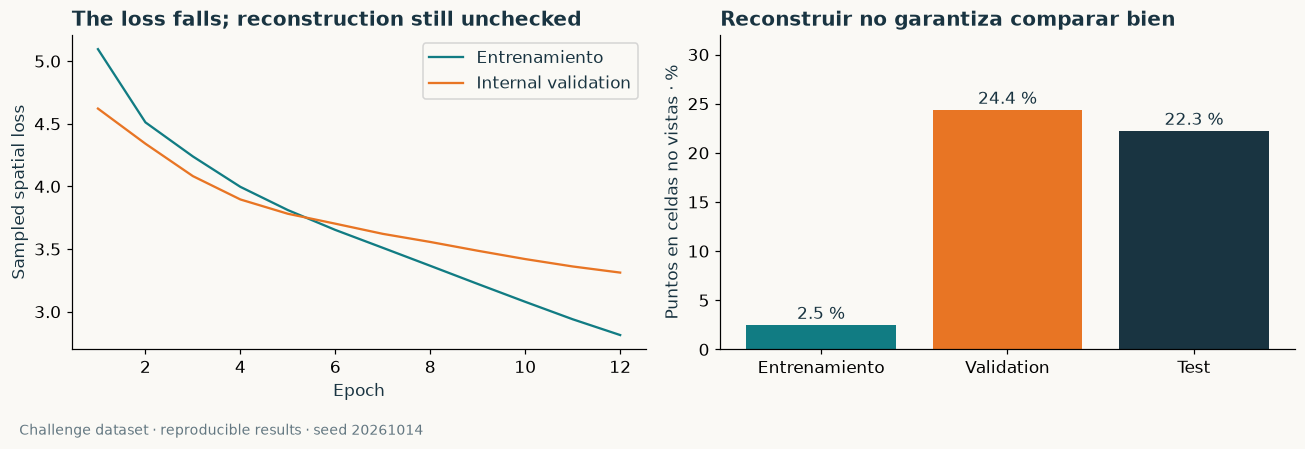

In [14]:
fig,axs=plt.subplots(1,2,figsize=(12,4.3))
h=pd.DataFrame(encoder['history'])
axs[0].plot(h.epoch,h.train_loss,color=TEAL,label='Entrenamiento')
axs[0].plot(h.epoch,h.inner_validation_loss,color=ORANGE,label='Internal validation')
axs[0].set_xlabel('Epoch');axs[0].set_ylabel('Sampled spatial loss')
axs[0].set_title('The loss falls; reconstruction still unchecked');axs[0].legend()
rates=encoder['oov_by_split']
axs[1].bar(['Entrenamiento','Validation','Test'],[100*rates[s] for s in ['train','val','test']],color=[TEAL,ORANGE,INK])
for i,s in enumerate(['train','val','test']):axs[1].text(i,100*rates[s]+.6,f'{100*rates[s]:.1f} %',ha='center')
axs[1].set_ylim(0,32);axs[1].set_ylabel('Puntos en celdas no vistas · %')
axs[1].set_title('Reconstruir no garantiza comparar bien')
finish(fig,'05_t2vec_aprendizaje')

The per-route average of points falling in unseen cells reaches roughly 24 % on validation and 22 % on test. They are assigned to the nearest training centroid without extending the vocabulary. This allows inference but can lose spatial detail. 2.5 % of training includes the internal subset excluded from fitting the vocabulary.

Besides, a 250-metre cell can hide separations between nearby streets. This is a **plausible** explanation, not a demonstrated cause, for the embedding performing worse. Identifying it would require comparing resolutions with new validation experiments.

### 5.7 The check that was missing: does it actually reconstruct?

This question prompted an additional audit of the already-saved model. We use the **286 trajectories from the 143 internal validation journeys**: they did not fit the weights, but they did take part in selecting the checkpoint. They are not a new test set. We use no human labels and modify no weights.

We evaluate two situations: clean input, and input with 20 % of points independently removed plus Gaussian noise of 15 metres. Endpoints are kept when removing points, although they also receive noise. We generate cells by taking the highest score over the full vocabulary, without giving the decoder the correct previous cell; it stops on predicting END or after 128 steps.

We measure four different things:

1. **Per-token accuracy with teacher forcing:** percentage of correct positions when the decoder receives the true previous token. It includes END; it is a demanding measure because neighbouring cells also receive weight in the loss.
2. **Empty free reconstruction:** how often it predicts END without emitting a single cell. This cannot be hidden by excluding those routes from a spatial average.
3. **Normalised edit distance:** insertions, deletions and substitutions needed to turn the predicted sequence into the original, divided by the greater length. It runs from 0 — a match — to 1 — maximum discrepancy on this scale. We exclude END.
4. **Spatial discrete Fréchet:** compares the point ordering of the resampled original route against the reconstructed centroids, with distances over an Earth sphere in metres. If the prediction is empty, the distance is left missing and that failure is reported separately.

As references we keep the available input points and the target sequence represented by vocabulary centroids. The second is a diagnostic of quantisation and unknown cells, **not a reconstruction any model could obtain without knowing the answer**.

,Rutas,Empty output,Token accuracy with teacher forcing,Mean free-running edit distance,Non-empty routes,"Median Fréchet, non-empty · km"
Entrada,,,,,,
No alteration,286,69.2%,4.2%,1.0000,88,8634.4
20 % dropout + noise,286,69.6%,4.2%,0.9997,87,8528.0


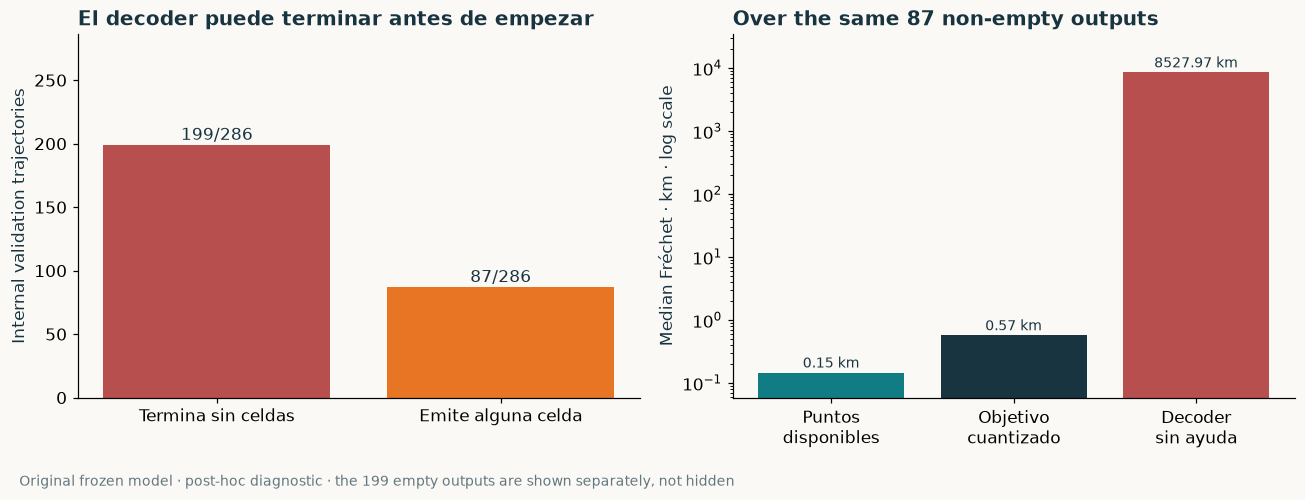

,Rutas,Fraccion_vacia,Edicion_media
geography,,,
Alguna celda no vista,203,0.600985,0.999621
All known cells,83,0.927711,1.000000


In [15]:
recon_dir=ROOT/'results/routes_reconstruction'
recon_metrics=json.loads((recon_dir/'metrics.json').read_text())
recon_predictions=pd.DataFrame(json.loads((recon_dir/'predictions.json').read_text()))
recon_rows=[]
for scenario,label in [('clean','No alteration'),('corrupted','20 % dropout + noise')]:
    m=recon_metrics[scenario]
    recon_rows.append({'Entrada':label,'Rutas':m['n_routes'],'Empty output':m['empty_fraction'],
        'Token accuracy with teacher forcing':m['teacher_forced_token_accuracy']['mean'],
        'Mean free-running edit distance':m['free_normalized_edit']['mean'],
        'Non-empty routes':m['decoded_frechet_m']['n'],
        'Median Fréchet, non-empty · km':(m['decoded_frechet_m']['median'] if m['decoded_frechet_m']['median'] is not None else np.nan)/1000})
display(pd.DataFrame(recon_rows).set_index('Entrada').style.format({
    'Empty output':'{:.1%}','Token accuracy with teacher forcing':'{:.1%}','Mean free-running edit distance':'{:.4f}',
    'Median Fréchet, non-empty · km':'{:.1f}'}))
corrupted=recon_predictions[recon_predictions.scenario=='corrupted']
nonempty=corrupted[~corrupted['empty']]
fig,axs=plt.subplots(1,2,figsize=(12,4.8))
empty_n=int(corrupted['empty'].sum());nonempty_n=len(nonempty)
axs[0].bar(['Termina sin celdas','Emite alguna celda'],[empty_n,nonempty_n],color=[RED,ORANGE])
for i,n in enumerate([empty_n,nonempty_n]):axs[0].text(i,n+4,f'{n}/{len(corrupted)}',ha='center')
axs[0].set_ylim(0,len(corrupted));axs[0].set_ylabel('Internal validation trajectories')
axs[0].set_title('El decoder puede terminar antes de empezar')
fields=['input_frechet_m','oracle_quantized_frechet_m','decoded_frechet_m']
values=[nonempty[k].median()/1000 for k in fields]
axs[1].bar(['Puntos\ndisponibles','Objetivo\ncuantizado','Decoder\nsin ayuda'],values,color=[TEAL,INK,RED])
axs[1].set_yscale('log');axs[1].set_ylabel('Median Fréchet · km · log scale')
axs[1].set_title(f'Over the same {len(nonempty)} non-empty outputs')
for i,v in enumerate(values):axs[1].text(i,v*1.2,f'{v:.2f} km',ha='center',fontsize=9)
axs[1].set_ylim(min(values)*.4,max(values)*4)
finish(fig,'05b_auditoria_reconstruccion','Original frozen model · post-hoc diagnostic · the 199 empty outputs are shown separately, not hidden')
known=corrupted.assign(geography=np.where(corrupted.oov==0,'All known cells','Alguna celda no vista'))
display(known.groupby('geography').agg(Rutas=('journey_id','size'),
    Fraccion_vacia=('empty','mean'),Edicion_media=('free_normalized_edit','mean')))

**The result forces a correction of the earlier interpretation:** the decoder in this adaptation does not reconstruct properly. With altered input, 199 of 286 outputs are empty — 69.6 % — and the remaining 87 show enormous spatial error. Free reconstruction fails with clean input too. The falling training loss did not demonstrate that generation worked.

We also found a **concrete defect in the implemented loss**: negatives are sampled only among cells and never include END. So predicting END with a very high score at a step that should contain a cell is not penalised by that sampled objective. We verified it by raising END's score by 100: the loss of a stretch that does not terminate stays exactly the same. This does not happen with a loss normalised over all possible outputs.

That defect helps explain the premature ending, but fixing it does not by itself guarantee a good representation: the normaliser approximation, data scarcity, resolution and unseen cells all remain. **The saved supervised metrics describe this failed attempt; they are not valid evidence against the t2vec of the paper.** The geometry and the road-network experiment do not depend on this decoder.

This finding requires correcting the objective before interpreting the quality of the method. We run that experiment separately below, keeping the original splits and results intact.

### 5.8 We correct the objective and repeat the check

The new version normalises over **all cells and END**, excluding only the auxiliary start and padding symbols. If the decoder assigns too much score to END when it should predict a cell, the denominator grows and the loss penalises it. We checked this with a gradient test and with the same artificial score increase used to detect the defect.

$$\mathcal L_t=\log\sum_{c\in\mathcal V\cup\{\mathrm{END}\}}e^{s_t(c)}-\sum_c q_t(c)s_t(c).$$

$s_t(c)$ is the output score for each cell and $q_t$ spreads the target across spatial neighbours; for END all the weight falls on END. The normaliser is no longer sampled. This costs more compute, but removes the omission we found.

We retrain from the same seed, with the same architecture, vocabulary, journeys and maximum budget of 12 epochs. We pick the checkpoint using altered internal-validation inputs, with reproducible noise. This also makes the selection task more consistent with the training task; we therefore do not attribute all subsequent differences solely to including END. We then train the same family of classifiers, selecting their size and threshold on supervised validation.

Weights and results are saved to new folders. The audit uses the same routes and alterations as before. **It is still a small adaptation of t2vec and an exploratory experiment run after inspecting the test set**, even though the loss is now correctly normalised.

,Empty output,Terminates before the cap,Mean free-running edit distance,Token accuracy with teacher forcing,Non-empty routes,"Median Fréchet, non-empty · km"
Version,,,,,,
Original: defective loss,69.6%,100.0%,0.9997,4.2%,87,8527.97
Corrected loss,4.9%,95.5%,0.9980,9.8%,272,9158.89


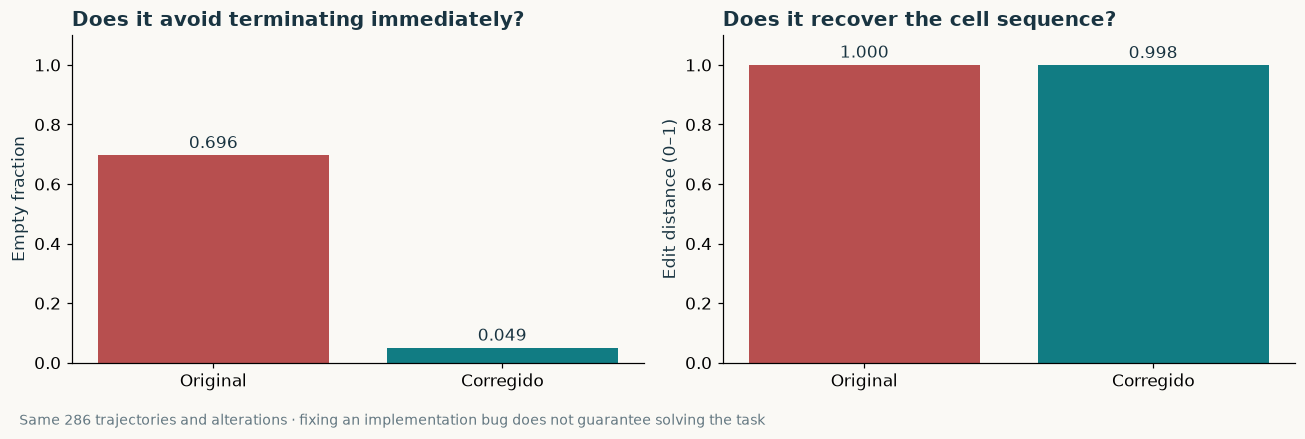

,LL val,BA val,BA test
Modelo,,,
Original,0.6018,0.6936,0.7183
Corregido,0.5840,0.7149,0.7710


These classification metrics answer a different question: whether the vector allows the human votes to be reproduced. They must be read alongside the reconstruction, the unknown cells and the geometric baseline. A correct training objective is necessary to interpret the experiment, but it does not ensure that the learned representation is sufficient for this task.

In [16]:
corrected_recon=json.loads((ROOT/'results/routes_reconstruction_corrected/metrics.json').read_text())
corrected_model=json.loads((ROOT/'results/routes_t2vec_corrected/metrics.json').read_text())
comparison_rows=[]
for label,report in [('Original: defective loss',recon_metrics),('Corrected loss',corrected_recon)]:
    m=report['corrupted']
    comparison_rows.append({'Version':label,'Empty output':m['empty_fraction'],
        'Terminates before the cap':m['eos_fraction'],'Mean free-running edit distance':m['free_normalized_edit']['mean'],
        'Token accuracy with teacher forcing':m['teacher_forced_token_accuracy']['mean'],
        'Non-empty routes':m['decoded_frechet_m']['n'],
        'Median Fréchet, non-empty · km':(m['decoded_frechet_m']['median'] if m['decoded_frechet_m']['median'] is not None else np.nan)/1000})
display(pd.DataFrame(comparison_rows).set_index('Version').style.format({
    'Empty output':'{:.1%}','Terminates before the cap':'{:.1%}','Mean free-running edit distance':'{:.4f}',
    'Token accuracy with teacher forcing':'{:.1%}','Median Fréchet, non-empty · km':'{:.2f}'}))
fig,axs=plt.subplots(1,2,figsize=(12,4.2))
for ax,key,title in zip(axs,['empty_fraction','free_normalized_edit'],['Does it avoid terminating immediately?','Does it recover the cell sequence?']):
    vals=[]
    for report in [recon_metrics,corrected_recon]:
        value=report['corrupted'][key]
        vals.append(value['mean'] if isinstance(value,dict) else value)
    ax.bar(['Original','Corregido'],vals,color=[RED,TEAL]);ax.set_ylim(0,1.1)
    for i,v in enumerate(vals):ax.text(i,v+.025,f'{v:.3f}',ha='center')
    ax.set_title(title);ax.set_ylabel('Empty fraction' if key=='empty_fraction' else 'Edit distance (0–1)')
finish(fig,'05c_reconstruccion_corregida','Same 286 trajectories and alterations · fixing an implementation bug does not guarantee solving the task')
display(pd.DataFrame([
    {'Modelo':'Original','LL val':details['t2vec_decoder_clasificador']['val_soft_logloss'],
     'BA val':metrics['t2vec_decoder_clasificador']['validation']['balanced_accuracy'],
     'BA test':metrics['t2vec_decoder_clasificador']['balanced_accuracy']},
    {'Modelo':'Corregido','LL val':corrected_model['val_soft_logloss'],
     'BA val':corrected_model['validation']['balanced_accuracy'],'BA test':corrected_model['balanced_accuracy']}
]).set_index('Modelo').style.format('{:.4f}'))
display(Markdown('These classification metrics answer a different question: whether the vector allows the human votes to be reproduced. '
    'They must be read alongside the reconstruction, the unknown cells and the geometric baseline. '
    'A correct training objective is necessary to interpret the experiment, but it does not ensure that '
    'the learned representation is sufficient for this task.'))

**What changed and what did not:** with altered inputs, the corrected version cuts empty outputs from 69.6 % to 4.9 %, but its mean edit distance stays close to 1 and the routes it generates remain spatially wrong. Terminating immediately less often is not the same as reconstructing well. Accuracy with teacher forcing is still low, so the problem is not explained solely by error accumulation during free generation either.

Classification reaches 77.1 % balanced accuracy on test against 71.8 % for the original attempt, but stays far from the 94.3 % of the geometric baseline. This is an exploratory comparison on the same test set we had already inspected. **We would not pick this version for the current prototype.** Before going further we would need more pretraining and experiments on architecture, resolution and coverage, checking reconstruction from the start and with new data to confirm the final result.

## 6. The protocol is decided before looking at the test set

This section describes the original four-model experiment. The later road-network extension keeps its fitting rules, but its exploratory evaluation is explicitly identified in section 7.1.

**Model selection:** lowest cross-entropy against the votes on validation. This rule rewards probabilities consistent with human disagreement.

**Threshold selection:** highest balanced accuracy on validation, scanning 0.10–0.90 in steps of 0.01; ties favour the threshold closest to 0.5. We assume neither that 0.5 is optimal nor that the errors have known business costs.

Balanced accuracy is the average of the proportion of «the same» and «they differ» correctly recognised. It stops a majority class from dominating the figure.

The positive class is **«they differ»**. It is worth separating three questions:

| Question | Metric and reading |
|---|---|
| How many decisions do we get right at the fixed threshold? | **Accuracy:** fraction correct. **Balanced accuracy:** mean recall over both classes. Higher is better. |
| How does the «they differ» alert behave? | **Precision:** of the alerts raised, how many match the human majority. **Recall:** of the genuinely different journeys, how many we catch. **F1:** their harmonic mean. Higher is better. |
| Do we rank cases well without fixing a single threshold? | **ROC-AUC:** class separation across thresholds. **AP:** a summary of precision and recall for «they differ»; it depends on prevalence. Higher is better. |
| Are the probabilities reasonable? | **Brier:** squared error against the binary majority. **Binary log loss:** penalises confident errors especially. **Vote log loss:** uses the proportion of votes, ties included. Lower is better. |

To see the difference between the two losses, let $q_j$ be the model's probability and $p_j$ the fraction of «they differ» votes:

$$\mathrm{LL}_{\text{votes}}=-\frac{1}{N}\sum_j[p_j\log q_j+(1-p_j)\log(1-q_j)].$$

In binary log loss we replace $p_j$ with the majority $y_j\in\{0,1\}$ and exclude ties. A 2-to-1 vote becomes 1 in that second evaluation, but stays at $2/3$ in the first. **We select using the vote loss; we do not switch criteria once we see which metric favours which model.**

Three predefined configurations of depth and regularisation are tried per XGBoost, with early stopping on validation. For the neural head we try 32 and 64 hidden units. The models use the same split and targets. Vocabulary, encoder and scaling are never fitted using test data.

Once models, epochs and thresholds are chosen, the decisions are saved and test is evaluated. **We do not retrain on validation and we do not change the winner after seeing test.** The four variants are planned comparisons; later changes would require keeping the distinction between exploration and a fresh confirmation.

### Validation: where the decisions were made

,Basic geometry,Interpretable vector,t2vec + classifier,Vector + t2vec
Accuracy ↑,95.26%,95.26%,72.23%,95.49%
Balanced accuracy ↑,95.60%,95.46%,69.36%,95.59%
Precision · they differ ↑,98.34%,97.55%,70.40%,97.18%
Recall · they differ ↑,93.31%,94.09%,88.98%,94.88%
F1 · they differ ↑,95.76%,95.79%,78.61%,96.02%
ROC-AUC ↑,0.9894,0.9900,0.7527,0.9883
Average precision (AP) ↑,0.9923,0.9927,0.7479,0.9908
Brier binario ↓,0.0385,0.0402,0.2018,0.0387
Log loss binaria ↓,0.1351,0.1420,0.6002,0.1404
Vote log loss ↓ · selection criterion on val,0.1481,0.1536,0.6018,0.1522


### Test: evaluation with frozen models and thresholds

,Basic geometry,Interpretable vector,t2vec + classifier,Vector + t2vec
Accuracy ↑,93.68%,94.13%,74.49%,95.03%
Balanced accuracy ↑,94.30%,94.83%,71.83%,95.48%
Precision · they differ ↑,98.71%,99.57%,72.61%,98.74%
Recall · they differ ↑,90.20%,90.20%,89.41%,92.55%
F1 · they differ ↑,94.26%,94.65%,80.14%,95.55%
ROC-AUC ↑,0.9934,0.9938,0.8205,0.9927
Average precision (AP) ↑,0.9954,0.9956,0.8406,0.9950
Brier binario ↓,0.0321,0.0313,0.1731,0.0346
Log loss binaria ↓,0.1090,0.1057,0.5257,0.1130
Vote log loss ↓ · selection criterion on val,0.1210,0.1168,0.5292,0.1235


↑ Higher is better; ↓ lower is better. TN/TP are correct calls on the same/differ classes; FP/FN are false alarms/missed differences. The geometry column is the one chosen on validation. The validation metrics took part in fitting and selection; they are not an independent estimate of final performance.

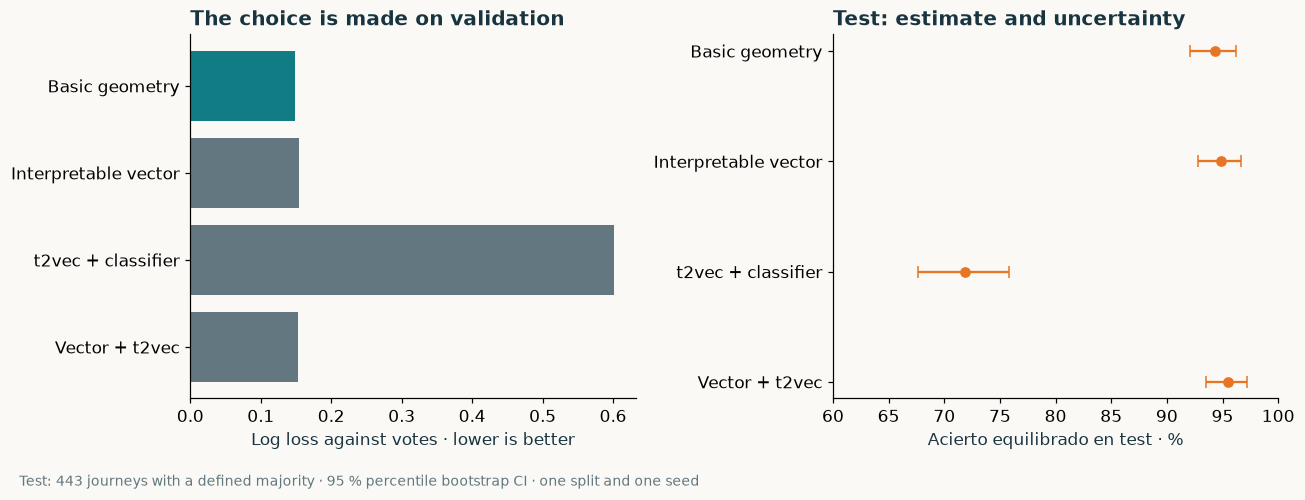

In [17]:
def metric_table(split):
    columns={}
    for key in names:
        m=metrics[key]['validation'] if split=='val' else metrics[key]
        tn,fp,fn,tp=np.array(m['confusion_matrix']).ravel()
        soft=frozen['validation_results'][key] if split=='val' else m['soft_logloss_all_decisive_votes']
        columns[names[key]]={
            'Accuracy ↑':f"{m['accuracy']:.2%}",
            'Balanced accuracy ↑':f"{m['balanced_accuracy']:.2%}",
            'Precision · they differ ↑':f'{tp/(tp+fp):.2%}',
            'Recall · they differ ↑':f'{tp/(tp+fn):.2%}',
            'F1 · they differ ↑':f"{m['f1']:.2%}",
            'ROC-AUC ↑':f"{m['roc_auc']:.4f}",
            'Average precision (AP) ↑':f"{m['average_precision']:.4f}",
            'Brier binario ↓':f"{m['brier']:.4f}",
            'Log loss binaria ↓':f"{m['logloss']:.4f}",
            'Vote log loss ↓ · selection criterion on val':f'{soft:.4f}',
            'Threshold chosen on validation':f"{metrics[key]['threshold']:.2f}",
            'Journeys with a majority / with valid votes':f"{m['n']} / {int(((df.split==split)&df.target_soft.notna()).sum())}",
            'TN / FP / FN / TP':f'{tn} / {fp} / {fn} / {tp}'}
    return pd.DataFrame(columns)

display(Markdown('### Validation: where the decisions were made'))
display(metric_table('val'))
display(Markdown('### Test: evaluation with frozen models and thresholds'))
display(metric_table('test'))
display(Markdown('↑ Higher is better; ↓ lower is better. TN/TP are correct calls on the same/differ classes; FP/FN are false alarms/missed differences. The geometry column is the one chosen on validation. The validation metrics took part in fitting and selection; they are not an independent estimate of final performance.'))
keys=list(names);yy=np.arange(len(keys))
fig,axs=plt.subplots(1,2,figsize=(12,4.8))
vals=[frozen['validation_results'][k] for k in keys]
axs[0].barh(yy,vals,color=[TEAL if k==frozen['selected'] else MUTED for k in keys])
axs[0].set_yticks(yy,[names[k] for k in keys]);axs[0].invert_yaxis()
axs[0].set_xlabel('Log loss against votes · lower is better')
axs[0].set_title('The choice is made on validation')
means=np.array([metrics[k]['balanced_accuracy'] for k in keys])*100
ci=np.array([metrics[k]['balanced_accuracy_ci95'] for k in keys])*100
axs[1].errorbar(means,yy,xerr=[means-ci[:,0],ci[:,1]-means],fmt='o',color=ORANGE,capsize=4)
axs[1].set_yticks(yy,[names[k] for k in keys]);axs[1].invert_yaxis()
axs[1].set_xlim(60,100);axs[1].set_xlabel('Acierto equilibrado en test · %')
axs[1].set_title('Test: estimate and uncertainty')
finish(fig,'06_validacion_y_test','Test: 443 journeys with a defined majority · 95 % percentile bootstrap CI · one split and one seed')

## 7. The key moment: more complex does not mean better demonstrated

The validation rule selects **basic geometry + XGBoost**. On test it gets 94.3 % balanced accuracy.

The extended vector reaches 94.8 %, the t2vec adaptation with a classifier 71.8 %, and the combination 95.5 %. The hybrid has the highest point estimate on test, but **we do not pick it retrospectively for that reason**.

To compare, we resample the same test journeys 2,000 times and compute the difference between models in each sample. Using the same journeys, the interval reflects which errors they share.

The improvements of the extended vector and the hybrid over the baseline have intervals that include zero. That does not prove equality: with this sample, the evidence does not let us claim the improvement is stable.

The intervals are conditional on this training run, this split and this geographic mix. They do not capture changes of seed, of city, dependence between corridors, or the uncertainty of the human panel. The secondary comparisons are exploratory and not corrected for multiplicity.

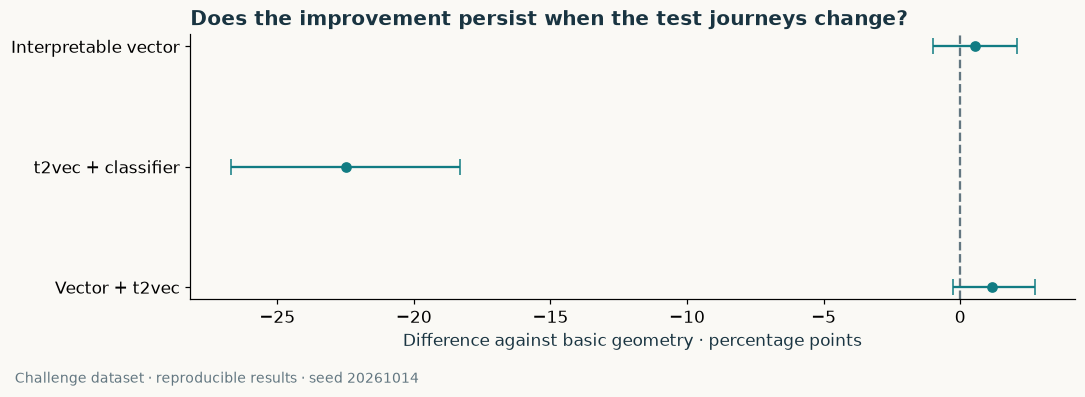

In [18]:
keys=list(comparisons);means=np.array([comparisons[k]['delta_balanced_accuracy'] for k in keys])*100
ci=np.array([comparisons[k]['paired_ci95'] for k in keys])*100
fig,ax=plt.subplots(figsize=(10,3.8))
ax.axvline(0,color=MUTED,ls='--')
ax.errorbar(means,np.arange(len(keys)),xerr=[means-ci[:,0],ci[:,1]-means],fmt='o',capsize=5,color=TEAL)
ax.set_yticks(np.arange(len(keys)),[names[k] for k in keys]);ax.invert_yaxis()
ax.set_xlabel('Difference against basic geometry · percentage points')
ax.set_title('Does the improvement persist when the test journeys change?')
finish(fig,'07_diferencias_pareadas')


### 7.1 Exploratory extension: now we can actually test the road network

We compare two new variants: **graph + XGBoost** and **42 geometric measurements + graph + XGBoost**. We use the same three XGBoost configurations and the same selection rule by validation log loss as in the original experiment. Thresholds are chosen on validation by balanced accuracy. We do not retrain on test and we do not discard journeys that are hard to match.

Before evaluating test we record which of the two variants wins on validation. The original geometric baseline and its predictions stay untouched. The test set had already guided the earlier discussion: keeping its labels out of fitting these models avoids a direct leak, but **it does not turn a comparison made after inspecting it into a fresh confirmatory test**.


,Variables,LL val ↓,BA val ↑,LL test ↓,BA test ↑,F1 test ↑,AUC test ↑,Threshold
Model,,,,,,,,
Basic geometry,8,0.1481,0.9560,0.1210,0.9430,0.9426,0.9934,0.7500
Interpretable vector,42,0.1536,0.9546,0.1168,0.9483,0.9465,0.9938,0.8200
Graph,36,0.1925,0.9300,0.2200,0.9072,0.9303,0.9718,0.4000
Geometry + graph,78,0.1559,0.9546,0.1219,0.9476,0.9467,0.9937,0.8000


The new variant chosen on validation is **Geometry + graph**. On the same **443 test journeys with a majority**, the balanced accuracy difference against the baseline is **+0.46 percentage points**, with a 95 % paired bootstrap interval **[-0.95, +1.97]**. The interval includes zero: it does not demonstrate a stable improvement. It describes variability across these journeys; it does not include repeating training, selection or new cities.

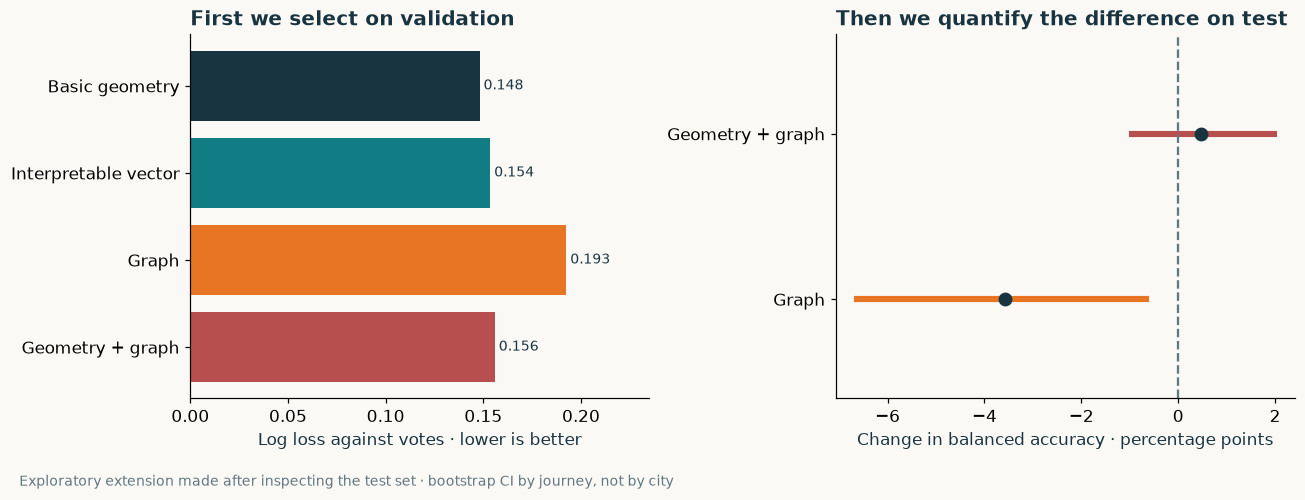

,Journeys,Errors,Accuracy
Quality,,,
Both satisfy the rule,244,16,93.4%
Partial or doubtful match,199,10,95.0%


In [19]:

new_names={'grafo_xgb':'Graph','geometria_grafo_xgb':'Geometry + graph'}
rows=[]
for name in ['geometria_base','vector_interpretable']:
    m=metrics[name]
    rows.append({'Model':names[name],'Variables':8 if name=='geometria_base' else 42,
       'LL val ↓':details[name]['val_soft_logloss'],'BA val ↑':m['validation']['balanced_accuracy'],
       'LL test ↓':m['soft_logloss_all_decisive_votes'],'BA test ↑':m['balanced_accuracy'],
       'F1 test ↑':m['f1'],'AUC test ↑':m['roc_auc'],'Threshold':m['threshold']})
for name,m in graph_metrics.items():
    rows.append({'Model':new_names[name],'Variables':graph_details[name]['n_features'],
       'LL val ↓':m['val_soft_logloss'],'BA val ↑':m['validation']['balanced_accuracy'],
       'LL test ↓':m['test_soft_logloss'],'BA test ↑':m['balanced_accuracy'],
       'F1 test ↑':m['f1'],'AUC test ↑':m['roc_auc'],'Threshold':m['threshold']})
road_table=pd.DataFrame(rows).set_index('Model')
display(road_table.style.format({c:'{:.4f}' for c in road_table.columns if c!='Variables'}))
selected_graph=graph_frozen['selected_new_variant'];gm=graph_metrics[selected_graph]
ci=gm['delta_base_ci95'];delta=100*gm['delta_base']
comparison='includes zero: it does not demonstrate a stable improvement' if ci[0]<=0<=ci[1] else ('lies above zero' if ci[0]>0 else 'lies below zero')
display(Markdown(f'The new variant chosen on validation is **{new_names[selected_graph]}**. '
    f'On the same **{gm["n"]} test journeys with a majority**, the balanced accuracy difference against the baseline is '
    f'**{delta:+.2f} percentage points**, with a 95 % paired bootstrap interval '
    f'**[{100*ci[0]:+.2f}, {100*ci[1]:+.2f}]**. The interval {comparison}. '
    'It describes variability across these journeys; it does not include repeating training, selection or new cities.'))
fig,axs=plt.subplots(1,2,figsize=(12,4.8))
order=list(road_table.index);yy=np.arange(len(order));colors=[INK,TEAL,ORANGE,RED]
axs[0].barh(yy,road_table['LL val ↓'],color=colors);axs[0].set_yticks(yy,order)
axs[0].invert_yaxis();axs[0].set_title('First we select on validation');axs[0].set_xlabel('Log loss against votes · lower is better')
for i,v in enumerate(road_table['LL val ↓']):axs[0].text(v+.002,i,f'{v:.3f}',va='center',fontsize=9)
axs[0].set_xlim(0,road_table['LL val ↓'].max()*1.22)
for i,(name,m) in enumerate(graph_metrics.items()):
    lo,hi=np.array(m['delta_base_ci95'])*100;d=m['delta_base']*100
    axs[1].plot([lo,hi],[i,i],color=ORANGE if i==0 else RED,lw=4)
    axs[1].scatter([d],[i],s=65,color=INK,zorder=3)
axs[1].axvline(0,color=MUTED,ls='--');axs[1].set_yticks([0,1],[new_names[k] for k in graph_metrics])
axs[1].set_ylim(-.6,1.6);axs[1].set_xlabel('Change in balanced accuracy · percentage points')
axs[1].set_title('Then we quantify the difference on test')
finish(fig,'07b_comparacion_grafo','Exploratory extension made after inspecting the test set · bootstrap CI by journey, not by city')

# Quality against performance, without changing filters, model or threshold.
quality_rows=[]
test_ids=df.index[(df.split=='test')&df.target_hard.notna()]
for complete,label in [(1,'Both satisfy the rule'),(0,'Partial or doubtful match')]:
    ids=test_ids[graph_features.loc[test_ids,'both_reliable'].to_numpy()==complete]
    y=df.loc[ids,'target_hard'].to_numpy();p=graph_predictions.loc[ids,'probabilities'].map(lambda v:v[selected_graph]).to_numpy()
    pred=p>=gm['threshold']
    quality_rows.append({'Quality':label,'Journeys':len(ids),'Errors':int((pred!=y).sum()),
        'Accuracy':float((pred==y).mean()) if len(ids) else np.nan})
display(pd.DataFrame(quality_rows).set_index('Quality').style.format({'Accuracy':'{:.1%}'}))



#### What the map lets us see that a straight-line distance cannot

We show a **training** example, chosen deterministically by match quality and central length, to inspect the transformation. The thin lines are the observations; the thick lines, the OSRM reconstruction. Looking good does not validate every journey, nor does it turn the current map into historical truth.


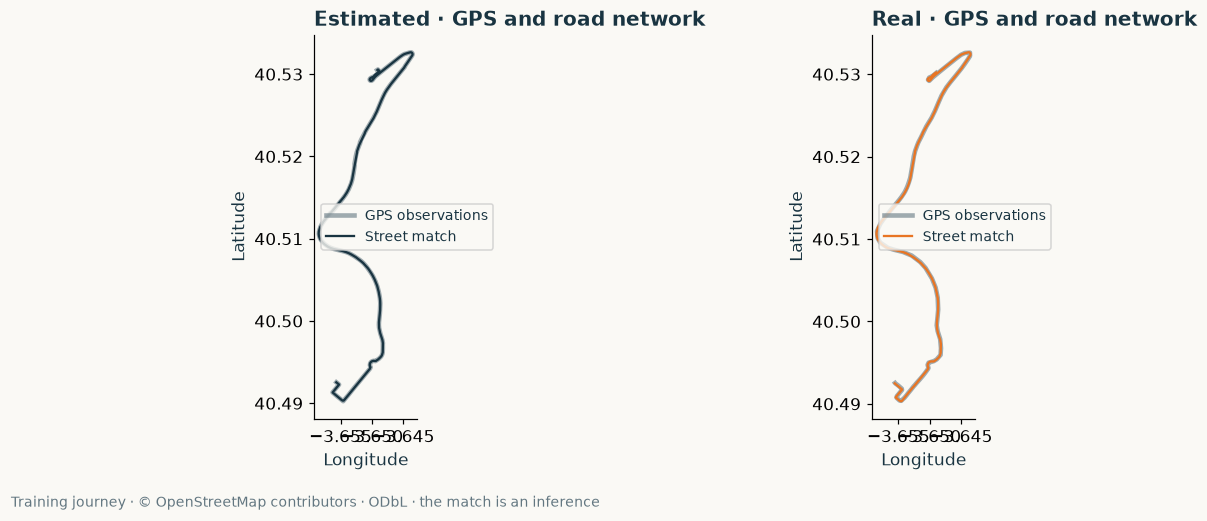

Journey `d41699a6-5c2b-11ec-a091-fd471e455c0a` · directed-edge IoU: **0.929**. The durations correspond to the inferred streets under the engine's fixed profile.

In [20]:

eligible=df.index[(df.split=='train')&(graph_features.both_reliable==1)]
if len(eligible):
    order_ids=features.loc[eligible,'length_real'].sort_values().index
    road_example=order_ids[len(order_ids)//2]
    fig,axs=plt.subplots(1,2,figsize=(12,5))
    for ax,kind,label,route,color in zip(axs,['estimated','real'],['Estimated','Real'],routes[road_example],[INK,ORANGE]):
        raw=json.loads((ROOT/'data/cache/roads/matches'/f'{road_example}_{kind}.json').read_text())
        ax.plot(route[:,1],route[:,0],color=MUTED,alpha=.6,lw=3,label='GPS observations')
        for idx,m in enumerate(raw.get('matchings',[])):
            xy=np.asarray(m['geometry']['coordinates'])
            ax.plot(xy[:,0],xy[:,1],color=color,lw=1.5,label='Street match' if idx==0 else None)
        ax.set_aspect(1/np.cos(np.radians(route[:,0].mean())))
        ax.set_title(label+' · GPS and road network');ax.set_xlabel('Longitude');ax.set_ylabel('Latitude');ax.legend(fontsize=9)
    finish(fig,'07c_map_matching_ejemplo','Training journey · © OpenStreetMap contributors · ODbL · the match is an inference')
    display(Markdown(f'Journey `{road_example}` · directed-edge IoU: '
        f'**{graph_features.loc[road_example,"directed_edge_iou"]:.3f}**. '
        'The durations correspond to the inferred streets under the engine\'s fixed profile.'))



**What remains to improve:** manually validate a sample of matches; vary the assumed GPS accuracy and the point density; use cartography from the date of the trip; obtain timestamps; measure distances on a network with turn restrictions for the proximity variables too; and separate the effect of connectivity, times and quality through ablations. Node-level proximity should be contrasted with an edge-level approximation. We also need to evaluate an unseen city and a fresh test set if this line is to be developed further.

The quality indicators may help the classifier, but they can also capture differences between cities or devices. So an improvement of the combined model **would not by itself demonstrate that connectivity is the mechanism responsible**. The map makes the experiment possible; its predictive usefulness and its reliability remain empirical questions.


## 8. Back to the routes: what does getting it right, and getting it wrong, mean?

A high AUC indicates good ranking, but it does not settle which threshold suits the business. At the threshold chosen on validation, the baseline marks as similar 25 journeys the majority considered different, and marks as different three journeys the majority considered similar.

These figures depend on the chosen human target. The probabilities are not objective certainty. The calibration curve is shown as a diagnostic: it has not been recalibrated using test.

From here on, every route we inspect is from **test** and every prediction comes from **basic geometry + XGBoost**, at threshold **0.75**. The earlier training examples were there to explain the measurements; these are here to audit the final result.

| | The model says «the same» | The model says «they differ» |
|---|---|---|
| The majority says «the same» | **185 correct — TN** | **3 false alarms — FP** |
| The majority says «they differ» | **25 missed differences — FN** | **230 correct — TP** |

«Error» means disagreement with the available majority, which is often **a single person**. It does not mean we have demonstrated the trip is objectively the same or different. Telling a model error apart from a debatable label would require additional review.

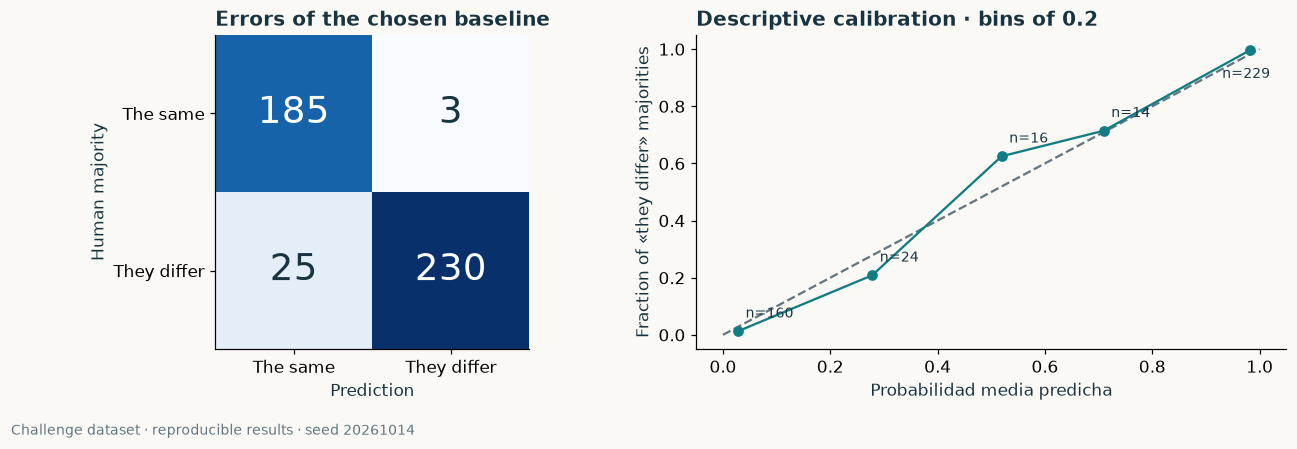

In [21]:
selected=frozen['selected'];m=metrics[selected]
fig,axs=plt.subplots(1,2,figsize=(12,4.3))
cm=np.array(m['confusion_matrix'])
axs[0].imshow(cm,cmap='Blues')
for i in range(2):
    for j in range(2):axs[0].text(j,i,str(cm[i,j]),ha='center',va='center',fontsize=24,color='white' if cm[i,j]>100 else INK)
axs[0].set_xticks([0,1],['The same','They differ']);axs[0].set_yticks([0,1],['The same','They differ'])
axs[0].set_xlabel('Prediction');axs[0].set_ylabel('Human majority');axs[0].set_title('Errors of the chosen baseline')
test=predictions[(predictions.split=='test')&predictions.target_hard.notna()].copy()
p=np.array([r[selected] for r in test.probabilities]);y=test.target_hard.to_numpy(float)
edges=np.linspace(0,1,6)
xs=[];ys=[];ns=[]
for i,(lo,hi) in enumerate(zip(edges[:-1],edges[1:])):
    mask=(p>=lo)&((p<=hi) if i==len(edges)-2 else (p<hi))
    if mask.any():xs.append(p[mask].mean());ys.append(y[mask].mean());ns.append(mask.sum())
axs[1].plot([0,1],[0,1],ls='--',color=MUTED);axs[1].plot(xs,ys,'o-',color=TEAL)
for a,b,n in zip(xs,ys,ns):
    offset=(-18,-18) if a>.9 else (5,9)
    axs[1].annotate(f'n={n}',(a,b),xytext=offset,textcoords='offset points',fontsize=9)
axs[1].set_xlabel('Probabilidad media predicha');axs[1].set_ylabel('Fraction of «they differ» majorities')
axs[1].set_title('Descriptive calibration · bins of 0.2')
finish(fig,'08_errores_y_calibracion')

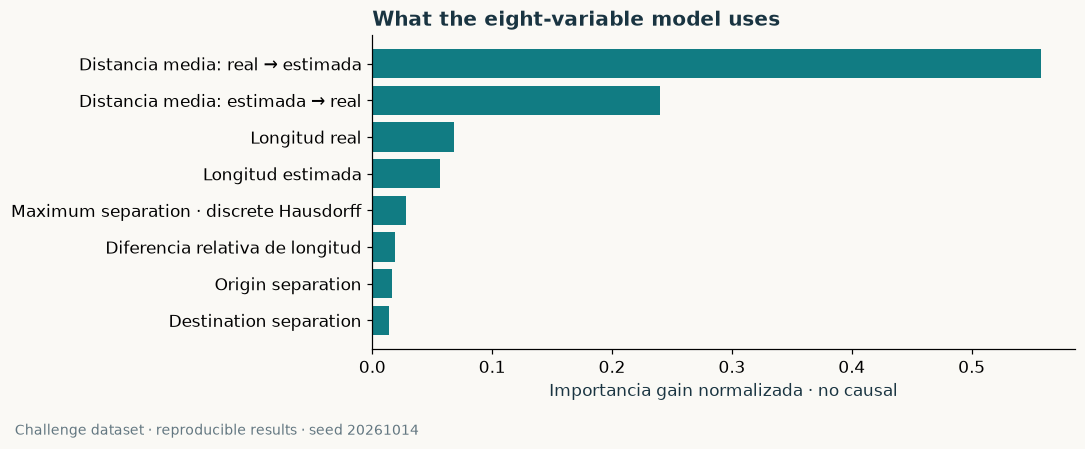

In [22]:
importance=pd.Series(details[selected]['feature_importance']).sort_values()
fig,ax=plt.subplots(figsize=(10,4.3))
feature_labels={'mean_real_to_est_m':'Distancia media: real → estimada',
 'mean_est_to_real_m':'Distancia media: estimada → real','length_real':'Longitud real',
 'length_est':'Longitud estimada','hausdorff_discrete_m':'Maximum separation · discrete Hausdorff',
 'relative_length_delta':'Diferencia relativa de longitud','start_gap_m':'Origin separation',
 'end_gap_m':'Destination separation'}
ax.barh([feature_labels[k] for k in importance.index],importance.values,color=TEAL)
ax.set_xlabel('Importancia gain normalizada · no causal')
ax.set_title('What the eight-variable model uses')
finish(fig,'09_variables_referencia')

### 8.1 First, recognising the two kinds of correct call

A metrics curve does not let you see whether the model recognises two almost-overlapping trips or an obvious deviation. We show **two correct calls of each class**: the one in the central position when sorting by score, and the one closest to the threshold. That way we see a central case and a tighter decision, without hand-picking the most striking pictures.

The dark line is the estimated route; the dashed orange one is the real route. Axes are in kilometres, with the same horizontal and vertical scale within each panel. Panels adapt to each journey: they do not all span the same area. Circles mark starts and squares mark ends.

When reading «0.74», remember: it is a probabilistic score for «they differ», but the chosen rule requires **at least 0.75** to emit that label. It is not a percentage of differing metres.

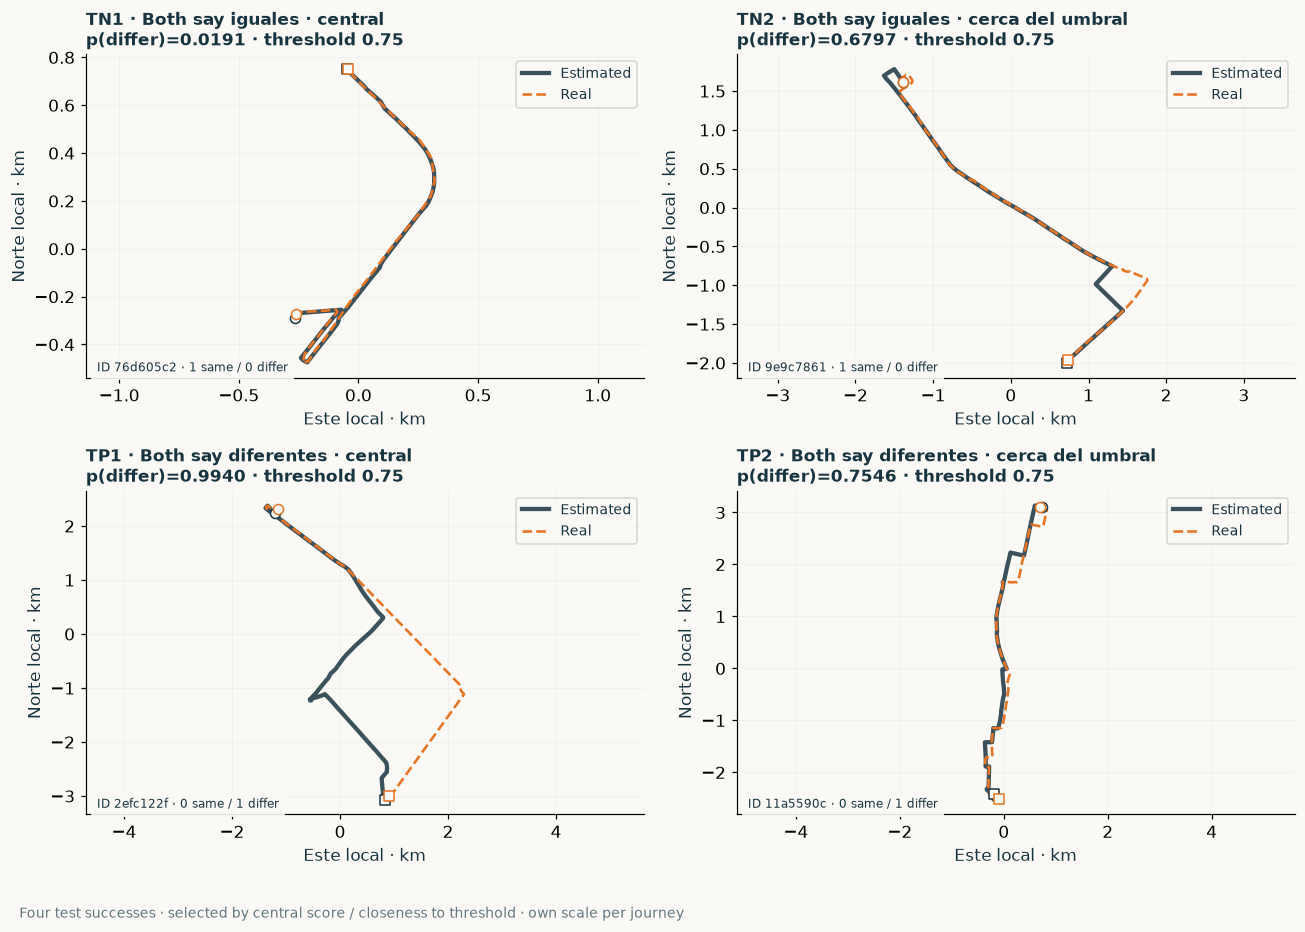

**Log of the ten cases.** Their full identifiers are kept so they can be found in the file; the votes are already deduplicated. The proportion beyond 50 m helps read the plots, but is not an input to the eight-variable model.

,journey_id,Votos de personas distintas,p(differ)
Case,,,
TN1,76d605c2-53bd-11ec-85f8-f375d723c6bb,1 same / 0 differ,0.0191
TN2,9e9c7861-5b92-11ec-ba48-594a04a8692a,1 same / 0 differ,0.6797
TP1,2efc122f-550d-11ec-b404-1fa436dc71f9,0 same / 1 differ,0.9940
TP2,11a5590c-58d4-11ec-acb7-07daec1c071b,0 same / 1 differ,0.7546
FP1,d83c424c-5d25-11ec-9d69-8f9c4816515c,1 same / 0 differ,0.8161
FP2,08dbb70e-544b-11ec-b4f0-59cee9b51d86,1 same / 0 differ / 1 unsure,0.7838
FP3,05dce576-5461-11ec-bf72-6984594a873c,1 same / 0 differ,0.7669
FN1,09313a21-5c76-11ec-b8de-6f7115c12387,0 same / 1 differ,0.0584
FN2,e1f245d0-5711-11ec-875a-2f4d7245bfe0,0 same / 1 differ / 2 unsure,0.5052


**Geometric measurements for the same cases.** The TN, TP, FP and FN identifiers link these measurements to the figures.

,Long. estimada · km,Long. real · km,Media real → estimada · m,Media estimada → real · m,Hausdorff discreto · m,Real a >50 m de estimada
Case,,,,,,
TN1,2.06,2.01,3.5,3.6,12.9,0.0%
TN2,6.05,6.11,49.9,41.5,485.0,20.6%
TP1,8.17,7.87,562.4,677.3,2191.5,67.3%
TP2,7.01,6.93,55.9,50.0,269.8,39.2%
FP1,12.69,12.48,71.5,125.9,889.4,14.7%
FP2,20.48,19.56,63.0,125.5,1329.3,13.7%
FP3,6.44,6.41,40.8,55.9,321.7,22.4%
FN1,15.40,15.31,30.2,37.9,550.4,11.0%
FN2,17.17,17.35,92.9,84.7,775.9,28.6%


In [23]:
test['p']=p
test['pred']=(p>=m['threshold']).astype(int)
assert selected=='geometria_base'
assert set(test.index).issubset(set(df.index[df.split=='test']))
assert np.array_equal(cm,np.array([[((y==i)&(test.pred.to_numpy()==j)).sum() for j in range(2)] for i in range(2)]))

# Descriptive, reproducible selection made after freezing the model.
case_rows=[]
for kind,label in [('TN',0),('TP',1)]:
    group=test[(test.target_hard==label)&(test.pred==label)].sort_values(['p'],kind='stable')
    central=group.index[len(group)//2]
    boundary=(group.p-m['threshold']).abs().sort_values(kind='stable').index[0]
    for suffix,jid,reason in [('1',central,'Central score among the correct calls of its class'),
                              ('2',boundary,'Correct call of its class closest to the threshold')]:
        case_rows.append(dict(case=kind+suffix,kind=kind,journey_id=jid,selection=reason))
fp=test[(test.target_hard==0)&(test.pred==1)].sort_values('p',ascending=False,kind='stable')
fn=test[(test.target_hard==1)&(test.pred==0)].sort_values('p',kind='stable')
for k,jid in enumerate(fp.index,1):
    case_rows.append(dict(case=f'FP{k}',kind='FP',journey_id=jid,selection='All false alarms, ordered by score'))
for k,rank in enumerate([0,len(fn)//2,len(fn)-1],1):
    case_rows.append(dict(case=f'FN{k}',kind='FN',journey_id=fn.index[rank],
        selection=['Lowest score among the false negatives','Central score among the false negatives',
                   'False negative closest to the threshold'][k-1]))
cases=pd.DataFrame(case_rows).set_index('case')
assert cases.journey_id.is_unique and len(cases)==10
assert len(fp)==3 and len(fn)==25

def vote_counts(jid):
    row=df.loc[jid]
    different=int(round(row.n_votes*row.target_soft))
    return int(row.n_votes)-different,different,int(row.n_unknown),int(row.n_conflicted_annotators)

def vote_text(jid):
    same,different,unknown,conflict=vote_counts(jid)
    text=f'{same} same / {different} differ'
    if unknown:text+=f' / {unknown} unsure'
    if conflict:text+=f' / {conflict} contradictorios'
    return text

def plot_routes(ax,a,b,ends=True,legend=True):
    ax.plot(a[:,0]/1000,a[:,1]/1000,color=INK,lw=2.8,alpha=.85,label='Estimated')
    ax.plot(b[:,0]/1000,b[:,1]/1000,color=ORANGE,lw=1.7,ls='--',label='Real')
    if ends:
        for xy,color in [(a,INK),(b,ORANGE)]:
            ax.scatter(xy[0,0]/1000,xy[0,1]/1000,marker='o',s=43,facecolors=BG,edgecolors=color,zorder=4)
            ax.scatter(xy[-1,0]/1000,xy[-1,1]/1000,marker='s',s=35,facecolors=BG,edgecolors=color,zorder=4)
    ax.set_aspect('equal',adjustable='datalim')
    ax.set_xlabel('Este local · km');ax.set_ylabel('Norte local · km')
    if legend:ax.legend(fontsize=9,loc='best')
    ax.grid(alpha=.12)

fig,axs=plt.subplots(2,2,figsize=(12,9))
for ax,(case,meta) in zip(axs.flat,cases[cases.kind.isin(['TN','TP'])].iterrows()):
    jid=meta.journey_id;row=test.loc[jid]
    a,b=project_pair(*routes[jid])
    plot_routes(ax,a,b)
    human='iguales' if row.target_hard==0 else 'diferentes'
    reason='central' if case.endswith('1') else 'cerca del umbral'
    ax.set_title(f'{case} · Both say {human} · {reason}\np(differ)={row.p:.4f} · threshold 0.75',fontsize=11)
    ax.text(.02,.02,f'ID {jid[:8]} · {vote_text(jid)}',transform=ax.transAxes,fontsize=8,
            bbox=dict(facecolor=BG,alpha=.9,edgecolor='none'))
finish(fig,'10_aciertos_test','Four test successes · selected by central score / closeness to threshold · own scale per journey')

ledger=[]
for case,meta in cases.iterrows():
    jid=meta.journey_id;row=test.loc[jid];f=features.loc[jid]
    ledger.append({'Case':case,'journey_id':jid,'Votos de personas distintas':vote_text(jid),
       'p(differ)':row.p,'Long. estimada · km':f.length_est/1000,'Long. real · km':f.length_real/1000,
       'Media real → estimada · m':f.mean_real_to_est_m,'Media estimada → real · m':f.mean_est_to_real_m,
       'Hausdorff discreto · m':f.hausdorff_discrete_m,
       'Real a >50 m de estimada':f.fraction_real_to_est_over_50m})
ledger=pd.DataFrame(ledger).set_index('Case')
display(Markdown('**Log of the ten cases.** Their full identifiers are kept so they can be found in the file; the votes are already deduplicated. The proportion beyond 50 m helps read the plots, but is not an input to the eight-variable model.'))
display(ledger[['journey_id','Votos de personas distintas','p(differ)']].style.format({'p(differ)':'{:.4f}'}))
display(Markdown('**Geometric measurements for the same cases.** The TN, TP, FP and FN identifiers link these measurements to the figures.'))
display(ledger.drop(columns=['journey_id','Votos de personas distintas','p(differ)']).style.format({'Long. estimada · km':'{:.2f}','Long. real · km':'{:.2f}',
    'Media real → estimada · m':'{:.1f}','Media estimada → real · m':'{:.1f}',
    'Hausdorff discreto · m':'{:.1f}','Real a >50 m de estimada':'{:.1%}'}))

### 8.2 The errors: separating trace, decision and label

We inspect **the three false positives** and **three of the 25 false negatives**: the lowest-scoring one, the central one and the one closest to the threshold. They are not a random sample of errors and cannot be used to estimate how often each explanation applies. The prediction log keeps all 28 errors.

Each figure answers four questions:

1. **Full view:** do the routes look alike overall?
2. **Zoom:** is there a stretch the trip's scale was hiding? We centre the window on the largest separation found when sampling 800 positions per route.
3. **Distance profile:** is the difference brief or persistent? We measure from each position to the opposite polyline. The percentage refers to the length of **each route**, not to time or to synchronised positions.
4. **Model contributions:** which variables push this prediction towards «the same» or «they differ»?

For the last panel we use [XGBoost's TreeSHAP contributions](https://xgboost.readthedocs.io/en/stable/prediction.html). They decompose the trained model's score before the sigmoid:

$$\log\frac{q}{1-q}=\phi_0+\sum_{k=1}^{8}\phi_k,\qquad
q=\frac{1}{1+\exp[-(\phi_0+\sum_k\phi_k)]}.$$

$\phi_0$ is the trees' implicit baseline; each $\phi_k$ is a contribution in **log-odds**, not in percentage points. Orange raises the «they differ» score and green lowers it. We use the trained model's internal baseline, without adding test as a background set. We keep exactly the trees of the iteration chosen on validation and check that the sum reconstructs the frozen prediction.

This explains **how the model scores this input**, not why a person drove that way or why the annotator voted that way. The variables are related to each other; their contributions are not causal effects.

### FP1 · Falsa alarma

**Selection:** All false alarms, ordered by score. Full ID: **d83c424c-5d25-11ec-9d69-8f9c4816515c**. Valid votes and abstentions: **1 same / 0 differ**.

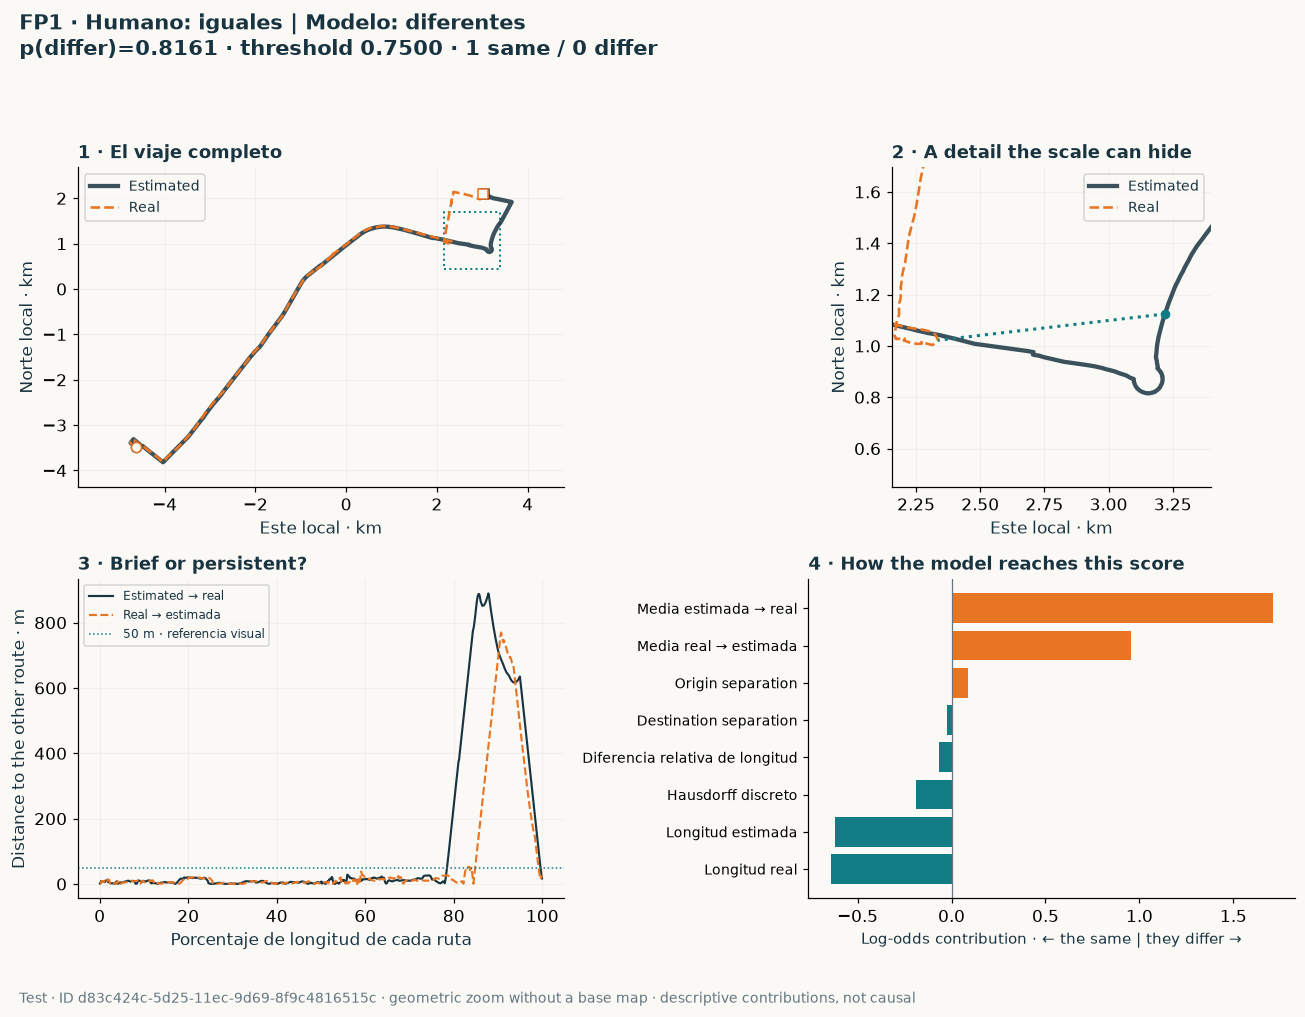

**What we measure:** estimated route 12.69 km and real route 12.48 km; mean separations real→estimated **71.5 m** and estimated→real **125.9 m**; discrete maximum **889 m**. **14.7%** of the real length lies more than 50 m from the estimated route.

**What the model does:** its three largest contributions in absolute value are Media estimada → real +1.71; Media real → estimada +0.96; Longitud real -0.64 (log-odds). Con referencia 0.278, the total sum is 1.490; the sigmoid recovers **0.8161**, against the threshold **0.75**.

**Reading:** there is geometric separation, but the only valid vote says «the same». The model crosses the threshold; the annotator may have tolerated that change when judging the whole trip. This is a hypothesis to check with more people, not proof the label is wrong. Nor do we know whether the trace reflects the real trip accurately: we have no independent validation of the GPS.

### FP2 · Falsa alarma

**Selection:** All false alarms, ordered by score. Full ID: **08dbb70e-544b-11ec-b4f0-59cee9b51d86**. Valid votes and abstentions: **1 same / 0 differ / 1 unsure**.

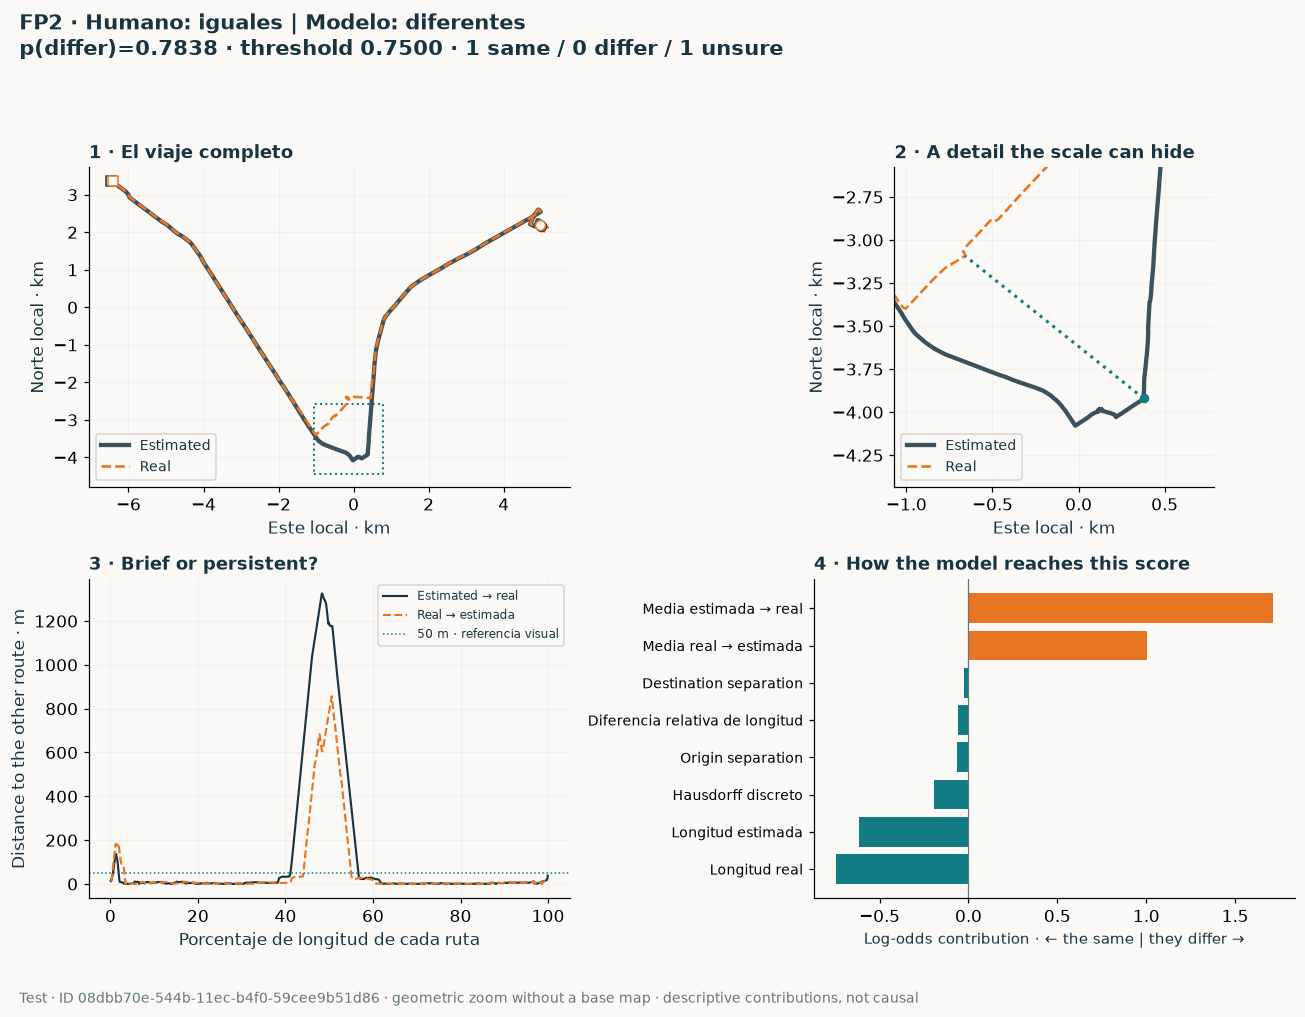

**What we measure:** estimated route 20.48 km and real route 19.56 km; mean separations real→estimated **63.0 m** and estimated→real **125.5 m**; discrete maximum **1329 m**. **13.7%** of the real length lies more than 50 m from the estimated route.

**What the model does:** its three largest contributions in absolute value are Media estimada → real +1.71; Media real → estimada +1.00; Longitud real -0.75 (log-odds). Con referencia 0.278, the total sum is 1.288; the sigmoid recovers **0.7838**, against the threshold **0.75**.

**Reading:** there is geometric separation, but the only valid vote says «the same». The model crosses the threshold; the annotator may have tolerated that change when judging the whole trip. This is a hypothesis to check with more people, not proof the label is wrong. Nor do we know whether the trace reflects the real trip accurately: we have no independent validation of the GPS.

### FP3 · Falsa alarma

**Selection:** All false alarms, ordered by score. Full ID: **05dce576-5461-11ec-bf72-6984594a873c**. Valid votes and abstentions: **1 same / 0 differ**.

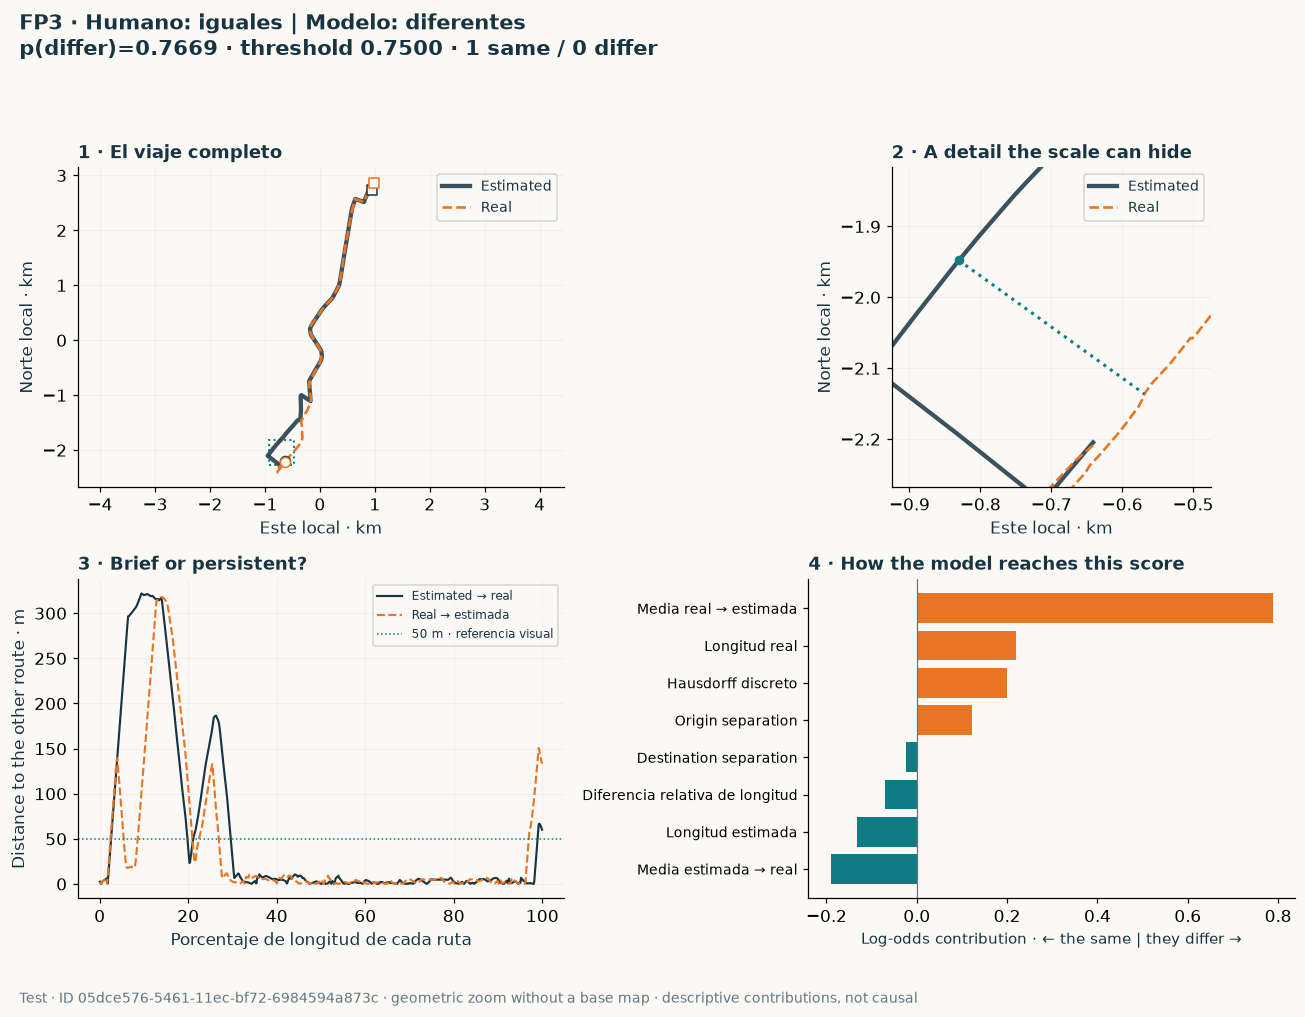

**What we measure:** estimated route 6.44 km and real route 6.41 km; mean separations real→estimated **40.8 m** and estimated→real **55.9 m**; discrete maximum **322 m**. **22.4%** of the real length lies more than 50 m from the estimated route.

**What the model does:** its three largest contributions in absolute value are Media real → estimada +0.79; Longitud real +0.22; Hausdorff discreto +0.20 (log-odds). Con referencia 0.278, the total sum is 1.191; the sigmoid recovers **0.7669**, against the threshold **0.75**.

**Reading:** there is geometric separation, but the only valid vote says «the same». The model crosses the threshold; the annotator may have tolerated that change when judging the whole trip. This is a hypothesis to check with more people, not proof the label is wrong. Nor do we know whether the trace reflects the real trip accurately: we have no independent validation of the GPS.

### FN1 · Diferencia no detectada

**Selection:** Lowest score among the false negatives. Full ID: **09313a21-5c76-11ec-b8de-6f7115c12387**. Valid votes and abstentions: **0 same / 1 differ**.

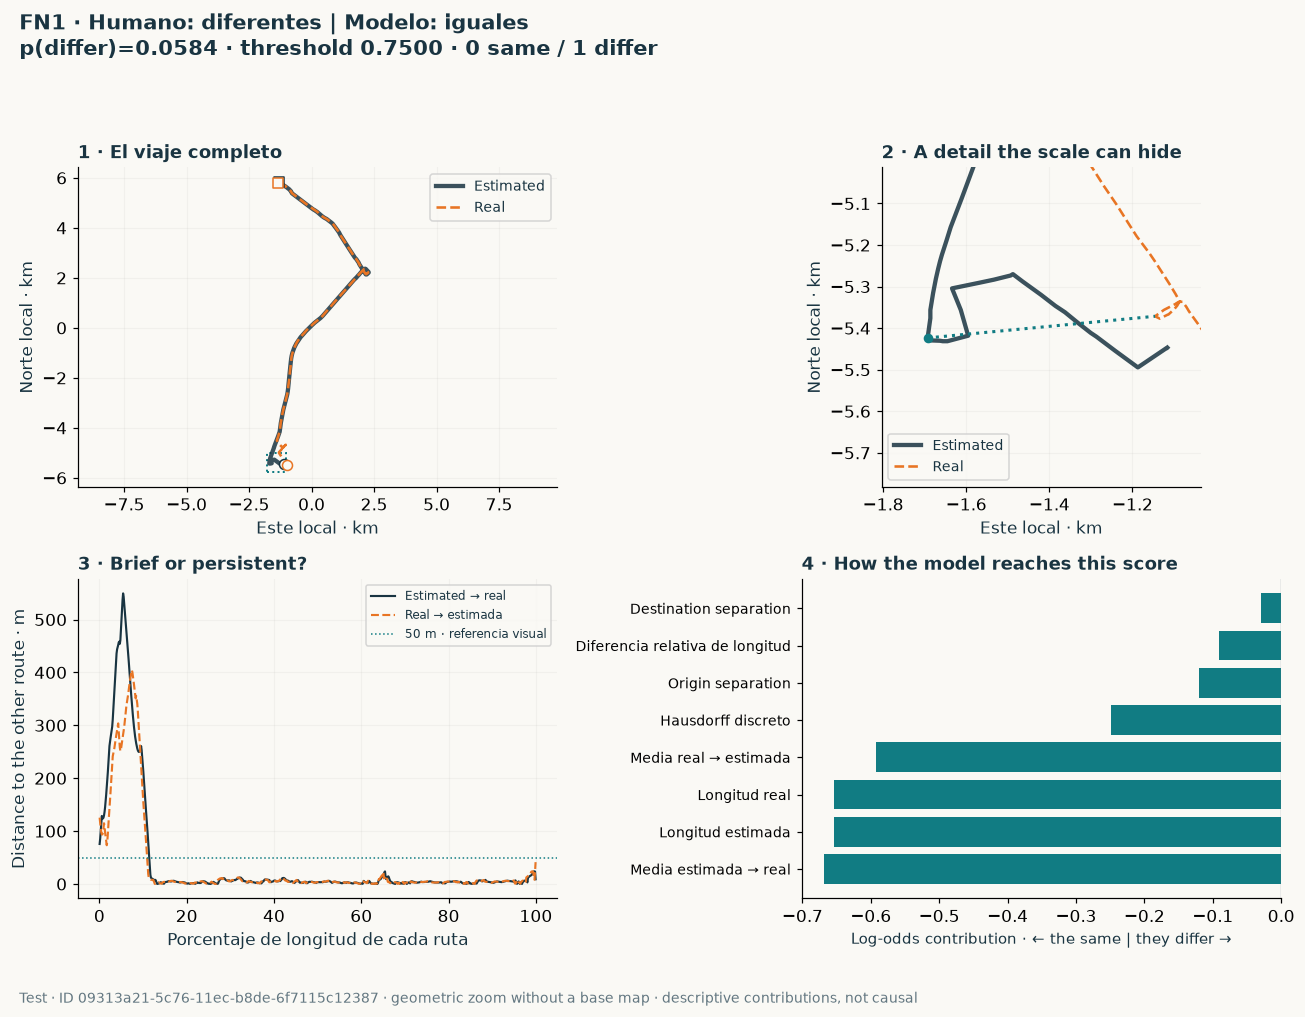

**What we measure:** estimated route 15.40 km and real route 15.31 km; mean separations real→estimated **30.2 m** and estimated→real **37.9 m**; discrete maximum **550 m**. **11.0%** of the real length lies more than 50 m from the estimated route.

**What the model does:** its three largest contributions in absolute value are Media estimada → real -0.67; Longitud estimada -0.65; Longitud real -0.65 (log-odds). Con referencia 0.278, the total sum is -2.780; the sigmoid recovers **0.0584**, against the threshold **0.75**.

**Reading:** the maximum separation exceeds half a kilometre, but the means stay in the tens of metres within a trip of about 15 km. The contributions of the means and the lengths lower the score. Here we see how a global summary can give little weight to a localised difference. Lowering the threshold slightly is not enough: the score is very low. The only valid annotator considered it different; the importance of that stretch and the consistency of that judgement would need reviewing.

### FN2 · Diferencia no detectada

**Selection:** Central score among the false negatives. Full ID: **e1f245d0-5711-11ec-875a-2f4d7245bfe0**. Valid votes and abstentions: **0 same / 1 differ / 2 unsure**.

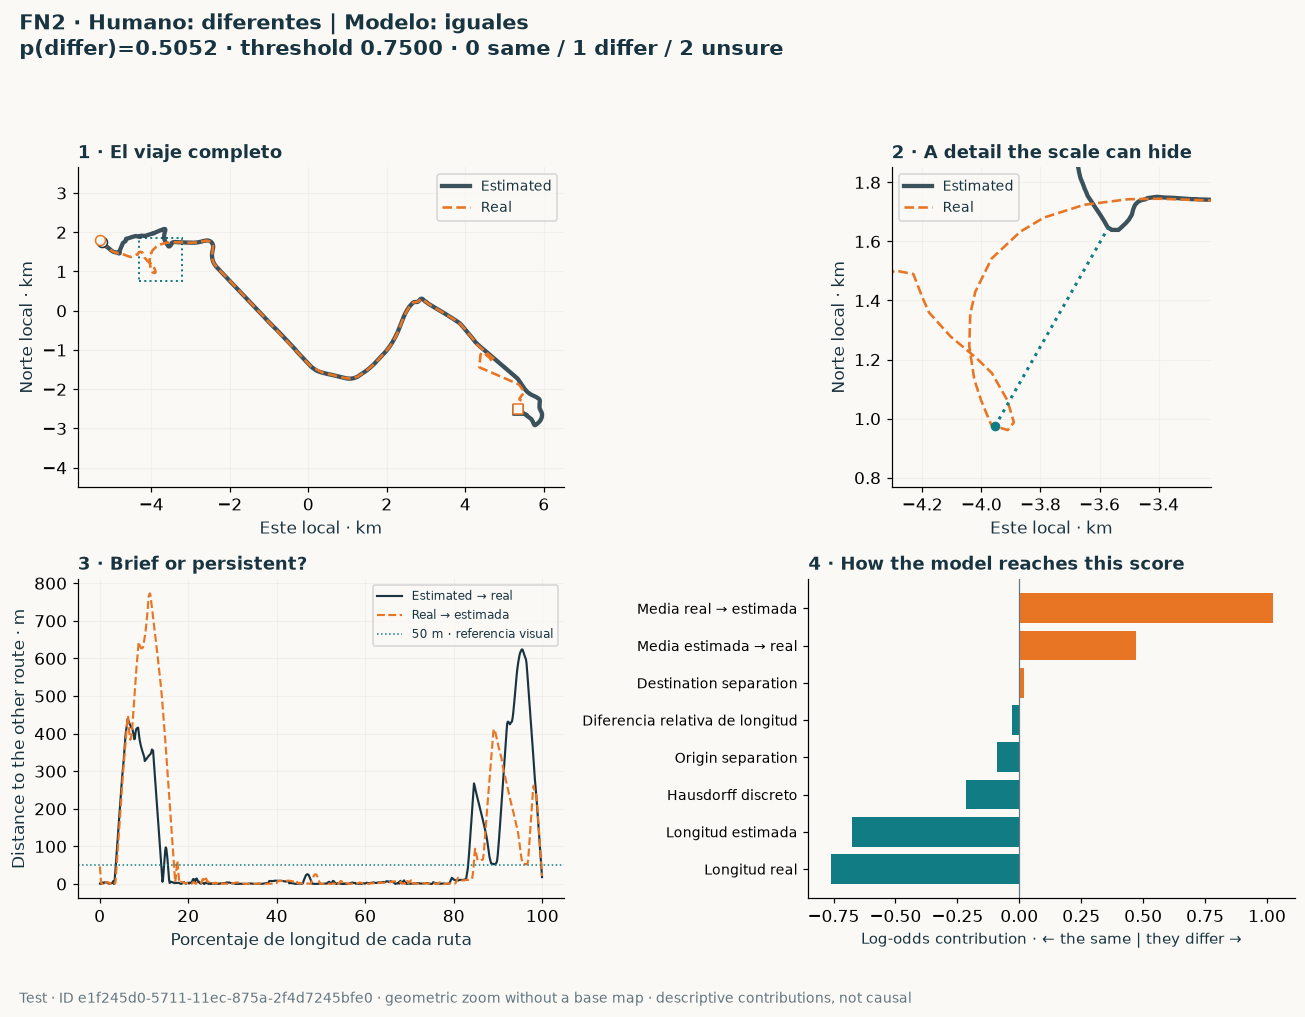

**What we measure:** estimated route 17.17 km and real route 17.35 km; mean separations real→estimated **92.9 m** and estimated→real **84.7 m**; discrete maximum **776 m**. **28.6%** of the real length lies more than 50 m from the estimated route.

**What the model does:** its three largest contributions in absolute value are Media real → estimada +1.02; Longitud real -0.76; Longitud estimada -0.68 (log-odds). Con referencia 0.278, the total sum is 0.021; the sigmoid recovers **0.5052**, against the threshold **0.75**.

**Reading:** the means push towards «they differ», but the lengths push towards «the same». The score sits near 0.5 and does not reach 0.75. There is one «they differ» vote and two «unsure»: this is not a three-person consensus. This case shows uncertainty in the label as well as the trade-off made by the model.

### FN3 · Diferencia no detectada

**Selection:** False negative closest to the threshold. Full ID: **3370ae46-5763-11ec-844b-9f3957b6aea1**. Valid votes and abstentions: **0 same / 1 differ**.

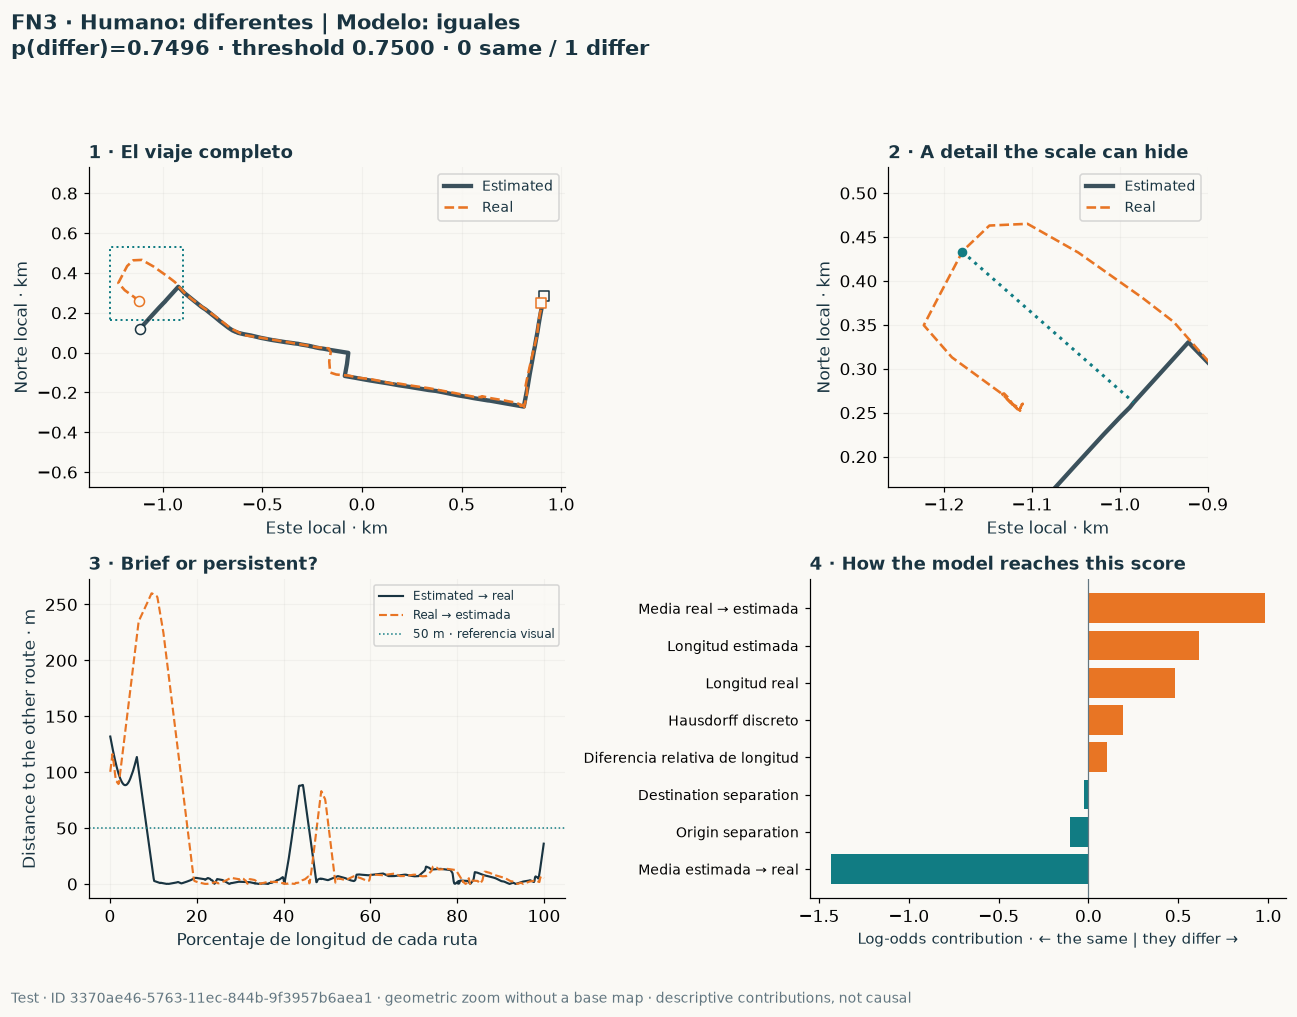

**What we measure:** estimated route 2.82 km and real route 3.20 km; mean separations real→estimated **38.1 m** and estimated→real **16.3 m**; discrete maximum **260 m**. **20.5%** of the real length lies more than 50 m from the estimated route.

**What the model does:** its three largest contributions in absolute value are Media estimada → real -1.43; Media real → estimada +0.98; Longitud estimada +0.62 (log-odds). Con referencia 0.278, the total sum is 1.096; the sigmoid recovers **0.7496**, against the threshold **0.75**.

**Reading:** 0.749593 sits just below 0.750000. This error is right on the decision boundary: rounding both numbers to 0.75 would hide what happened. Moving the threshold would flip its class, but it would also change other hits and misses. We do not tune it to fix this test journey; the threshold should answer to the cost of errors and be validated on independent data.

In [24]:
from xgboost import XGBRegressor,DMatrix
import hashlib
from shapely.geometry import Point
from shapely.ops import nearest_points
from matplotlib.patches import Rectangle

case_ids=cases.journey_id.tolist()
model_path=ROOT/f'models/routes/{selected}.ubj'
inspection_path=R/'inspection.json'
if model_path.exists():
    fitted=XGBRegressor(n_jobs=1);fitted.load_model(model_path)
    x=np.ascontiguousarray(features.loc[case_ids,BASE_FEATURES],dtype=np.float32)
    contributions=fitted.get_booster().predict(DMatrix(x),pred_contribs=True,
                                               iteration_range=(0,fitted.best_iteration+1))
    model_digest=hashlib.sha256(model_path.read_bytes()).hexdigest()
else:
    # Permite reproducir las figuras con las contribuciones exportadas.
    saved=json.loads(inspection_path.read_text())
    assert saved['selected']==selected and saved['threshold']==m['threshold']
    model_digest=saved['model_sha256']
    lookup={r['journey_id']:r for r in saved['cases']}
    contributions=np.array([[lookup[j]['contributions'][k] for k in BASE_FEATURES]+[lookup[j]['reference']]
                            for j in case_ids])
contributions=pd.DataFrame(contributions,index=case_ids,columns=BASE_FEATURES+['reference'])
reconstructed=1/(1+np.exp(-contributions.sum(axis=1).to_numpy()))
assert np.allclose(reconstructed,test.loc[case_ids,'p'].to_numpy(),atol=1e-6,rtol=1e-5)

inspection={'selected':selected,'threshold':m['threshold'],'model_sha256':model_digest,
 'purpose':'Post-hoc test inspection, with no model or threshold fitting.',
 'selection_policy':{'correct':'Central score and closest to the threshold, per class.',
                     'fp':'All false positives, by descending score.',
                     'fn':'Lowest, central and highest score among the false negatives.'},
 'confusion_matrix':cm.tolist(),'cases':[]}
for case,meta in cases.iterrows():
    jid=meta.journey_id
    same,different,unknown,conflict=vote_counts(jid)
    inspection['cases'].append(dict(case=case,kind=meta.kind,journey_id=jid,split='test',
        selection=meta.selection,probability=float(test.loc[jid,'p']),
        prediction=int(test.loc[jid,'pred']),human_majority=int(test.loc[jid,'target_hard']),
        votes=dict(same=same,different=different,unknown=unknown,conflicted=conflict),
        features={k:float(features.loc[jid,k]) for k in BASE_FEATURES},
        contributions={k:float(contributions.loc[jid,k]) for k in BASE_FEATURES},
        reference=float(contributions.loc[jid,'reference'])))
inspection_path.write_text(json.dumps(inspection,indent=2,ensure_ascii=False))

short_labels={'length_est':'Longitud estimada','length_real':'Longitud real',
 'relative_length_delta':'Diferencia relativa de longitud','start_gap_m':'Origin separation',
 'end_gap_m':'Destination separation','mean_est_to_real_m':'Media estimada → real',
 'mean_real_to_est_m':'Media real → estimada','hausdorff_discrete_m':'Hausdorff discreto'}

def error_figure(case,jid):
    row=test.loc[jid];a,b=project_pair(*routes[jid])
    la,lb=clean_line(a),clean_line(b)
    sa,sb=sample_line(la,800,midpoints=True),sample_line(lb,800,midpoints=True)
    da,db=distance(points(sa),lb),distance(points(sb),la)
    if da.max()>=db.max():
        furthest=sa[np.argmax(da)];nearest=np.array(nearest_points(Point(furthest),lb)[1].coords[0])
    else:
        furthest=sb[np.argmax(db)];nearest=np.array(nearest_points(Point(furthest),la)[1].coords[0])
    center=(furthest+nearest)/2
    radius=max(100,np.linalg.norm(furthest-nearest)*.7)
    fig,axs=plt.subplots(2,2,figsize=(12,9.2))
    full,zoom,profile,shap_ax=axs.flat
    plot_routes(full,a,b)
    full.add_patch(Rectangle((center-radius)/1000,2*radius/1000,2*radius/1000,
                            fill=False,ec=TEAL,lw=1.3,ls=':'))
    full.set_title('1 · El viaje completo',fontsize=12)
    plot_routes(zoom,a,b,ends=False)
    zoom.set_xlim((center[0]-radius)/1000,(center[0]+radius)/1000)
    zoom.set_ylim((center[1]-radius)/1000,(center[1]+radius)/1000)
    zoom.set_aspect('equal',adjustable='box')
    zoom.plot([furthest[0]/1000,nearest[0]/1000],[furthest[1]/1000,nearest[1]/1000],
              color=TEAL,ls=':',lw=2)
    zoom.scatter(*furthest/1000,color=TEAL,s=28,zorder=5)
    zoom.set_title('2 · A detail the scale can hide',fontsize=12)
    xx=(np.arange(800)+.5)/800*100
    profile.plot(xx,da,color=INK,lw=1.4,label='Estimated → real')
    profile.plot(xx,db,color=ORANGE,lw=1.4,ls='--',label='Real → estimada')
    profile.axhline(50,color=TEAL,ls=':',lw=1,label='50 m · referencia visual')
    profile.set(xlabel='Porcentaje de longitud de cada ruta',ylabel='Distance to the other route · m')
    profile.set_title('3 · Brief or persistent?',fontsize=12)
    profile.legend(fontsize=8);profile.grid(alpha=.12)
    s=contributions.loc[jid,BASE_FEATURES].sort_values()
    shap_ax.barh([short_labels[k] for k in s.index],s.values,
                  color=[ORANGE if v>=0 else TEAL for v in s.values])
    shap_ax.axvline(0,color=MUTED,lw=.8)
    shap_ax.tick_params(axis='y',labelsize=9)
    shap_ax.set_xlabel('Log-odds contribution · ← the same | they differ →',fontsize=10)
    shap_ax.set_title('4 · How the model reaches this score',fontsize=12)
    human='iguales' if row.target_hard==0 else 'diferentes'
    predicted='iguales' if row.pred==0 else 'diferentes'
    fig.suptitle(f'{case} · Humano: {human} | Modelo: {predicted}\n'
                 f'p(differ)={row.p:.4f} · threshold 0.7500 · {vote_text(jid)}',
                 x=.02,ha='left',fontsize=14,weight='bold',y=.995)
    finish(fig,f'11_error_test_{case.lower()}',
           f'Test · ID {jid} · geometric zoom without a base map · descriptive contributions, not causal')

for case,meta in cases[~cases.kind.isin(['TN','TP'])].iterrows():
    jid=meta.journey_id;row=test.loc[jid];f=features.loc[jid]
    heading='Falsa alarma' if meta.kind=='FP' else 'Diferencia no detectada'
    display(Markdown(f'### {case} · {heading}\n\n**Selection:** {meta.selection}. '
                     f'Full ID: **{jid}**. Valid votes and abstentions: **{vote_text(jid)}**.'))
    error_figure(case,jid)
    stats=(f'**What we measure:** estimated route {f.length_est/1000:.2f} km and real route {f.length_real/1000:.2f} km; '
           f'mean separations real→estimated **{f.mean_real_to_est_m:.1f} m** and estimated→real '
           f'**{f.mean_est_to_real_m:.1f} m**; discrete maximum **{f.hausdorff_discrete_m:.0f} m**. '
           f'**{f.fraction_real_to_est_over_50m:.1%}** of the real length lies more than 50 m from the estimated route.')
    display(Markdown(stats))
    s=contributions.loc[jid,BASE_FEATURES]
    explain='; '.join(f'{short_labels[k]} {v:+.2f}' for k,v in s.reindex(s.abs().sort_values(ascending=False).index[:3]).items())
    display(Markdown(f'**What the model does:** its three largest contributions in absolute value are '
                     f'{explain} (log-odds). Con referencia {contributions.loc[jid,"reference"]:.3f}, '
                     f'the total sum is {contributions.loc[jid].sum():.3f}; '
                     f'the sigmoid recovers **{row.p:.4f}**, against the threshold **{m["threshold"]:.2f}**.'))
    if meta.kind=='FP':
        interpretation=('**Reading:** there is geometric separation, but the only valid vote says «the same». '
            'The model crosses the threshold; the annotator may have tolerated that change when judging the whole trip. '
            'This is a hypothesis to check with more people, not proof the label is wrong. '
            'Nor do we know whether the trace reflects the real trip accurately: we have no independent validation of the GPS.')
    elif case=='FN1':
        interpretation=('**Reading:** the maximum separation exceeds half a kilometre, but the means stay in the tens of metres '
            'within a trip of about 15 km. The contributions of the means and the lengths lower the score. '
            'Here we see how a global summary can give little weight to a localised difference. '
            'Lowering the threshold slightly is not enough: the score is very low. The only valid annotator considered it different; '
            'the importance of that stretch and the consistency of that judgement would need reviewing.')
    elif case=='FN2':
        interpretation=('**Reading:** the means push towards «they differ», but the lengths push towards «the same». '
            'The score sits near 0.5 and does not reach 0.75. There is one «they differ» vote and two «unsure»: '
            'this is not a three-person consensus. This case shows uncertainty in the label as well as the trade-off made by the model.')
    else:
        interpretation=('**Reading:** 0.749593 sits just below 0.750000. This error is right on the decision boundary: '
            'rounding both numbers to 0.75 would hide what happened. Moving the threshold would flip its class, '
            'but it would also change other hits and misses. We do not tune it to fix this test journey; '
            'the threshold should answer to the cost of errors and be validated on independent data.')
    display(Markdown(interpretation))

### 8.3 What the inspection taught us

The same «error» label can hide different problems. A localised detour can be diluted in the averages of a long trip; two geometric signals can push in opposite directions; and a score almost identical to the threshold can flip the decision by ten-thousandths.

The human reference matters too. All three false alarms have a single decided vote per journey. The central false negative has one decision and two abstentions. **More model complexity will not, on its own, settle which similarity criterion we want to reproduce.**

The inspection proposes hypotheses, it does not confirm them. To move forward we would ask for additional annotations with clear instructions, analyse the cost of both error types and compare representations on a separate validation set. After exploring these examples, this test set should no longer be used both as ground for new decisions and as independent confirmation of those improvements.

### 8.4 Where does it fail? Almost always where a single person holds up the label

The inspection above suggested something worth measuring rather than hinting at: **a single decided vote** kept
appearing among the errors. We now split performance by how many people hold up the label, on validation
and on test, with the model and threshold already frozen. It changes nothing about the experiment: it redistributes the same correct calls.

There are two readings, and it is worth not stopping at the first.

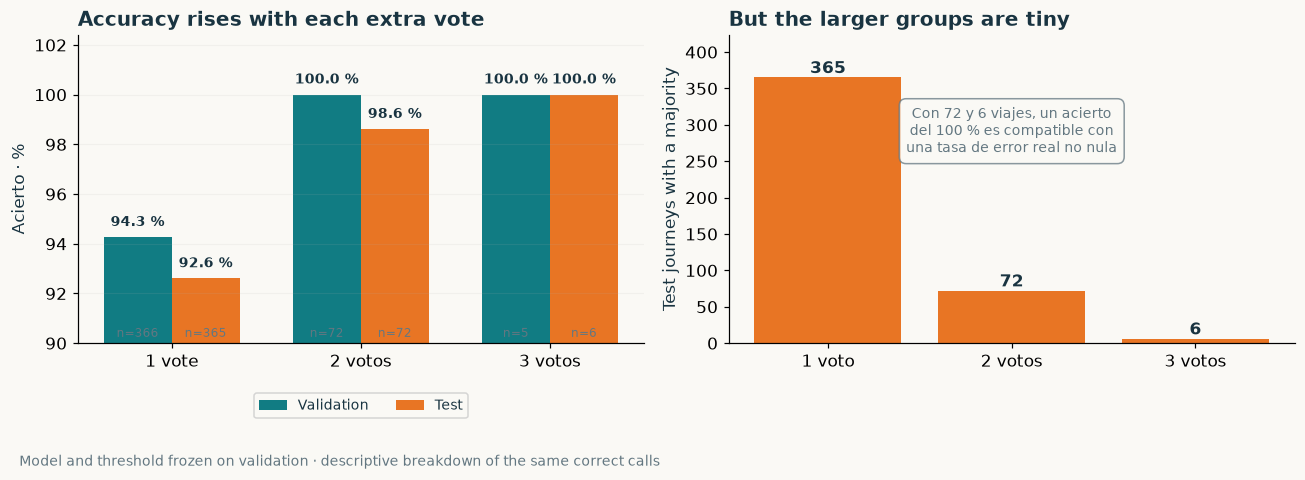

**Is this more than the frequency of each group?** Single-vote journeys are the majority, so they concentrate errors even if the model did not distinguish between groups. We compare what we observe against what we would expect if errors fell at random (one-sided hypergeometric test, descriptive and after seeing the data): **Validation**: 21 de 21 errores en viajes de un voto, esperados 17,3, p = 0.016 · **Test**: 27 de 28 errores en viajes de un voto, esperados 23,1, p = 0.027.

1813

In [25]:
from scipy.stats import hypergeom
vote_rows=[];concentration={}
for split,label in [('val','Validation'),('test','Test')]:
    part=predictions[(predictions.split==split)&predictions.target_hard.notna()]
    prob=np.array([r[selected] for r in part.probabilities])
    pred=(prob>m['threshold']).astype(int);truth=part.target_hard.to_numpy(int)
    nv=part.n_votes.to_numpy(int)
    for k in sorted(set(nv)):
        g=nv==k;yy,pp=truth[g],pred[g]
        tpr=(pp[yy==1]==1).mean() if (yy==1).any() else np.nan
        tnr=(pp[yy==0]==0).mean() if (yy==0).any() else np.nan
        vote_rows.append({'Conjunto':label,'Votos':int(k),'Journeys':int(g.sum()),
            'Acierto':float(100*(yy==pp).mean()),'Errores':int((yy!=pp).sum()),
            'Acierto equilibrado':float(100*np.nanmean([tpr,tnr])),
            '% of the split':float(100*g.mean())})
    # Do the errors concentrate on single-vote journeys beyond what their frequency explains?
    wrong=truth!=pred;N=len(truth);K=int((nv==1).sum());n=int(wrong.sum());x=int((nv[wrong]==1).sum())
    concentration[label]=dict(N=int(N),K=K,n=n,x=x,expected=float(n*K/N),
                              p_value=float(hypergeom.sf(x-1,N,K,n)))
votes_eval=pd.DataFrame(vote_rows)

fig,axs=plt.subplots(1,2,figsize=(12,4.6))
width=.36
for i,(label,color) in enumerate([('Validation',TEAL),('Test',ORANGE)]):
    part=votes_eval[votes_eval.Conjunto==label]
    xpos=np.arange(len(part))+(i-.5)*width
    axs[0].bar(xpos,part['Acierto'],width,color=color,label=label)
    for xv,acc,nn in zip(xpos,part['Acierto'],part['Journeys']):
        axs[0].text(xv,acc+.45,f'{acc:.1f} %',ha='center',fontsize=9,weight='bold')
        axs[0].text(xv,90.25,f'n={nn}',ha='center',fontsize=8,color=MUTED)
axs[0].set_xticks(np.arange(3),['1 vote','2 votos','3 votos'])
axs[0].set_ylim(90,102.4);axs[0].set_ylabel('Acierto · %')
axs[0].set_title('Accuracy rises with each extra vote')
axs[0].legend(fontsize=9,ncol=2,loc='upper center',bbox_to_anchor=(.5,-.14));axs[0].grid(axis='y',alpha=.12)
sizes=votes_eval[votes_eval.Conjunto=='Test'].set_index('Votos')['Journeys']
axs[1].bar([f'{k} voto' if k==1 else f'{k} votos' for k in sizes.index],sizes.values,color=ORANGE)
for i,v in enumerate(sizes.values):axs[1].text(i,v+6,str(v),ha='center',weight='bold')
axs[1].set_ylim(0,sizes.max()*1.16);axs[1].set_ylabel('Test journeys with a majority')
axs[1].set_title('But the larger groups are tiny')
axs[1].text(.5,.62,'Con 72 y 6 viajes, un acierto\ndel 100 % es compatible con\nuna tasa de error real no nula',
            transform=axs[1].transAxes,fontsize=9,color=MUTED,ha='center',
            bbox=dict(facecolor=BG,edgecolor=MUTED,alpha=.75,boxstyle='round,pad=.5'))
finish(fig,'12_rendimiento_por_votos',
       'Model and threshold frozen on validation · descriptive breakdown of the same correct calls')

display(votes_eval.set_index(['Conjunto','Votos']).style.format({
    'Acierto':'{:.1f} %','Acierto equilibrado':'{:.1f} %','% of the split':'{:.1f} %'}))
display(Markdown(
    '**Is this more than the frequency of each group?** Single-vote journeys are the majority, so they concentrate errors '
    'even if the model did not distinguish between groups. We compare what we observe against what we would expect if errors fell at random '
    '(one-sided hypergeometric test, descriptive and after seeing the data): '
    + ' · '.join(f"**{k}**: {v['x']} de {v['n']} errores en viajes de un voto, "
                 f"esperados {v['expected']:.1f}, p = {v['p_value']:.3f}".replace('.',',',1)
                 for k,v in concentration.items()) + '.'))
(R/'errors_by_votes.json').write_text(json.dumps(
    {'model':selected,'threshold':m['threshold'],
     'purpose':'Reparto descriptivo posterior; no modifica modelos, umbrales ni particiones.',
     'by_votes':vote_rows,'concentration':concentration},indent=2,ensure_ascii=False))

**First reading: the model does better the more people back the label.** On validation it goes from 94.3 %
with one vote to 100 % with two or three; on test, from 92.6 % to 98.6 % and 100 %. The 21 validation errors and 27 of the 28
test errors are on single-vote journeys. The concentration exceeds what group size alone would explain, though only
just: we would expect 17.3 of 21 on validation and 23.1 of 28 on test.

**Second reading, the one that stops us celebrating the first: the groups are not comparable.** A journey with two votes and
a defined majority is, *by construction*, a journey where two people agreed — had they disagreed it would be a
tie and carry no label. The «two or more votes» group is not «the same difficulty, measured better»: it is **the subset
of cases that turned out visually unambiguous**. Put another way, we compared the hard cases with the
easy ones and discovered the hard ones are harder.

The two explanations are indistinguishable with this file:

| Explanation | What it implies | How it would be told apart |
|---|---|---|
| **Label noise** · some of those 21 and 27 «errors» are individual opinions another person would not share | Our real accuracy is underestimated; the ceiling is not 100 % | Re-annotate those cases with several people and measure how many majorities change |
| **Genuine difficulty** · cases that are ambiguous for people are ambiguous for geometry too | The model has room to improve where it is hardest | Re-annotate and check the majority holds despite the disagreement |

That 72 two-vote journeys give 100 % and 98.6 % is not reassuring in itself either: at those sizes, a 95 %
confidence interval for a proportion of 72/72 reaches down to roughly 95 %. We have not demonstrated the
model is infallible on the clear cases; we have observed that it did not fail on a handful.

**The actionable part.** If the aim were to raise measured performance, the shortest path is not a bigger model: it is
**getting a second annotation for the single-vote journeys**, which are 83 % of the decisive cases and in practice all
of the errors. That would turn part of today's «error» into documented human disagreement and would give, for the first
time, a reference against which to compare the model on the cases genuinely in dispute. Before that it is worth
fixing in the instructions what counts as different — a threshold in metres, in time or in detour — because today the
brief leaves the criterion to each annotator's perception.

### 8.5 The ties: are they really confusing cases?

So far we have only evaluated journeys with a majority. The **31 ties** in the file — 7 of them in test — were left
out for having no binary label. They are worth looking at, because they underpin a claim we have repeated without testing:
that human disagreement signals genuine ambiguity rather than annotator carelessness.

If plotting them showed obviously identical or obviously different pairs, the tie would be panel noise and
our consensus rule would be discarding good information. If instead they show intermediate detours — neither overlap
nor clear divergence — then the tie describes the problem.

We add the model's score, which never saw these labels: a second opinion independent of the panel.

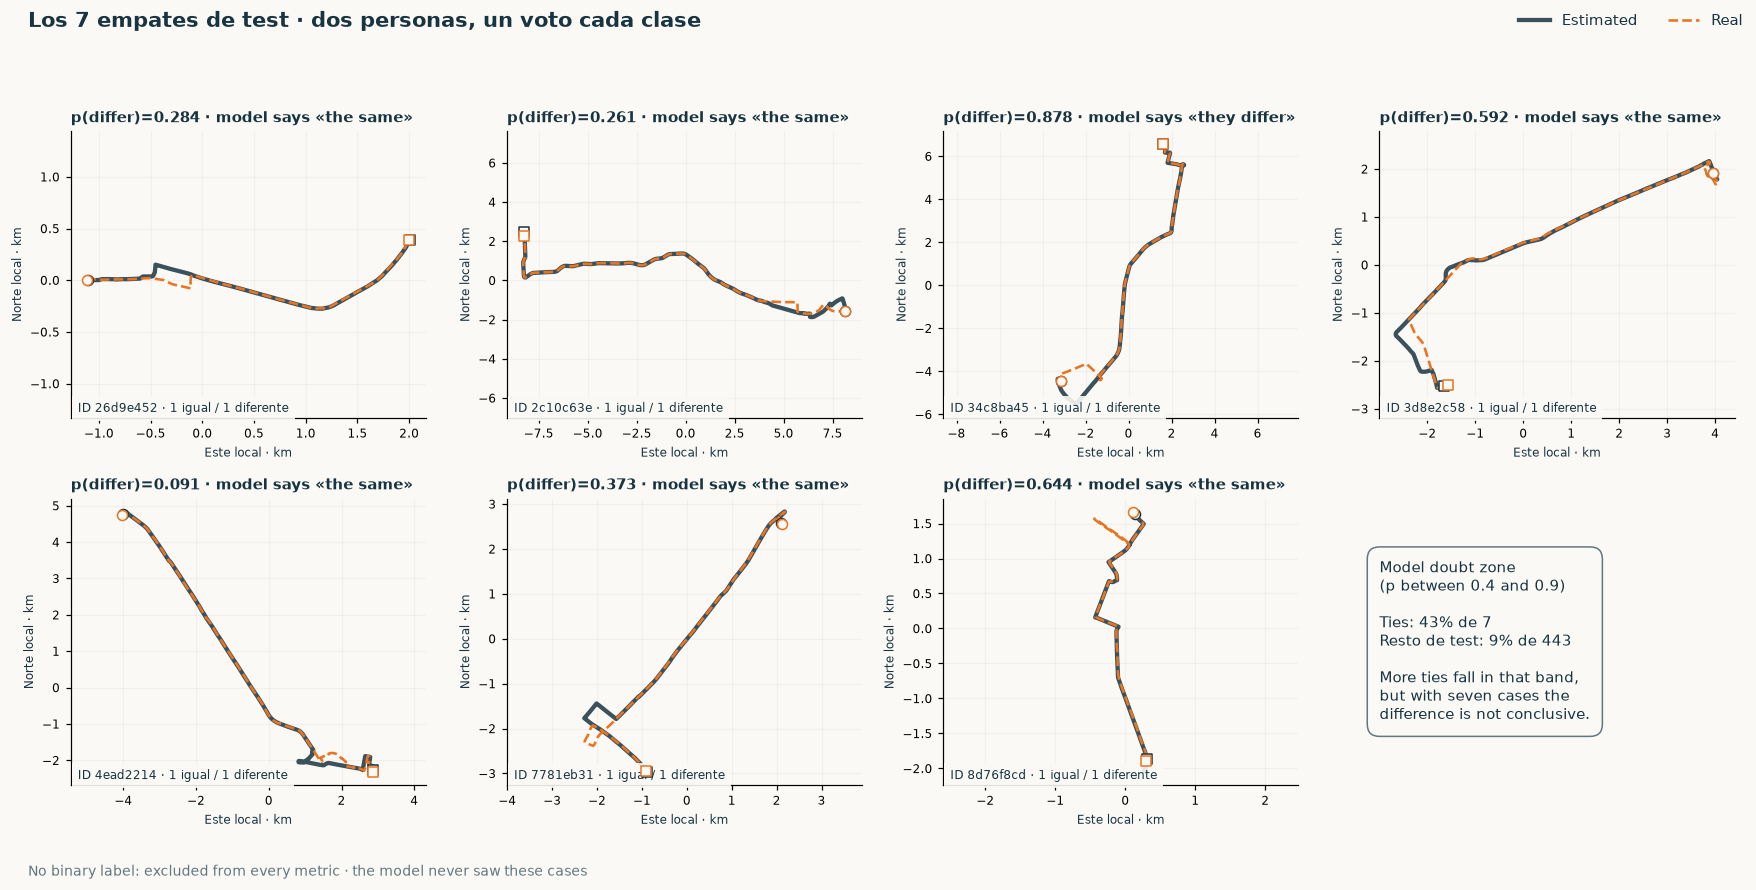

,Area,Longitud · km,Maximum separation · m,Position of the maximum · % of the trip,% de ruta a >50 m,p(differ),Model decision
journey_id,,,,,,,
26d9e452,Santiago,3.52,138,25 %,12 %,0.284,The same
2c10c63e,Santiago,21.08,582,3 %,22 %,0.261,The same
34c8ba45,Bogotá,17.13,1265,12 %,19 %,0.878,They differ
3d8e2c58,Santiago,10.02,377,83 %,20 %,0.592,The same
4ead2214,Bogotá,12.10,515,76 %,18 %,0.091,The same
7781eb31,Bogotá,9.20,497,75 %,12 %,0.373,The same
8d76f8cd,Lima,4.66,579,22 %,6 %,0.644,The same


En **7 de los 7** ties, the largest separation falls in the first or last quarter of the trip: the discrepancy is in how the trip starts or ends, not in the path between.

In [26]:
tie_ids=df.index[(df.status=='tie')&(df.split=='test')].tolist()
tie_p=np.array([predictions.loc[j,'probabilities'][selected] for j in tie_ids])
decisive=np.array([r[selected] for r in predictions[(predictions.split=='test')
                   &predictions.target_hard.notna()].probabilities])
band=lambda v:((v>.4)&(v<.9)).mean()
fig,axs=plt.subplots(2,4,figsize=(16,8))
for ax,jid,prob in zip(axs.flat,tie_ids,tie_p):
    a,b=project_pair(*routes[jid])
    plot_routes(ax,a,b,legend=False)
    ax.set_title(f'p(differ)={prob:.3f} · model says '
                 f'«{"they differ" if prob>m["threshold"] else "the same"}»',fontsize=10)
    ax.text(.02,.02,f'ID {jid[:8]} · 1 igual / 1 diferente',transform=ax.transAxes,fontsize=8,
            bbox=dict(facecolor=BG,alpha=.9,edgecolor='none'))
    ax.tick_params(labelsize=8);ax.set_xlabel('Este local · km',fontsize=8)
    ax.set_ylabel('Norte local · km',fontsize=8)
last=axs.flat[len(tie_ids)]
last.axis('off')
last.text(.0,.5,f'Model doubt zone\n(p between 0.4 and 0.9)\n\n'
    f'Ties: {band(tie_p):.0%} de 7\nResto de test: {band(decisive):.0%} de {len(decisive)}\n\n'
    'More ties fall in that band,\nbut with seven cases the\ndifference is not conclusive.',
    transform=last.transAxes,fontsize=10,va='center',color=INK,
    bbox=dict(facecolor=BG,edgecolor=MUTED,boxstyle='round,pad=.8'))
for ax in list(axs.flat)[len(tie_ids)+1:]:ax.axis('off')
handles,labels=axs.flat[0].get_legend_handles_labels()
fig.legend(handles,labels,loc='upper right',ncol=2,fontsize=10,frameon=False)
fig.suptitle('Los 7 empates de test · dos personas, un voto cada clase',
             x=.02,ha='left',fontsize=14,weight='bold',y=.998)
finish(fig,'13_empates_test','No binary label: excluded from every metric · the model never saw these cases')

# Where do they separate? Position of the point furthest from the other route.
tie_detail=[]
for jid in tie_ids:
    a_,b_=project_pair(*routes[jid]);la,lb=clean_line(a_),clean_line(b_)
    sa,sb=sample_line(la,400,midpoints=True),sample_line(lb,400,midpoints=True)
    da,db=distance(points(sa),lb),distance(points(sb),la)
    d=da if da.max()>=db.max() else db
    tie_detail.append({'Longitud · km':la.length/1000,'Maximum separation · m':float(d.max()),
        'Position of the maximum · % of the trip':100*(np.argmax(d)+.5)/400,
        '% de ruta a >50 m':100*float((da>50).mean())})
tie_table=pd.DataFrame(tie_detail,index=[j[:8] for j in tie_ids]).assign(
    Area=[predictions.loc[j,'region'] for j in tie_ids],**{'p(differ)':tie_p,
    'Model decision':['They differ' if v>m['threshold'] else 'The same' for v in tie_p]})
tie_table.index.name='journey_id'
display(tie_table[['Area','Longitud · km','Maximum separation · m','Position of the maximum · % of the trip',
                   '% de ruta a >50 m','p(differ)','Model decision']].style.format(
    {'Longitud · km':'{:.2f}','Maximum separation · m':'{:.0f}','Position of the maximum · % of the trip':'{:.0f} %',
     '% de ruta a >50 m':'{:.0f} %','p(differ)':'{:.3f}'}))
edges_count=int(sum((r['Position of the maximum · % of the trip']<25) or
                    (r['Position of the maximum · % of the trip']>75) for r in tie_detail))
display(Markdown(f'En **{edges_count} de los {len(tie_ids)}** ties, the largest separation falls in the first or '
    'last quarter of the trip: the discrepancy is in how the trip starts or ends, not in the path between.'))

**What the pictures show, and it is more specific than we expected.** None is a perfect overlap
nor a total divergence, but they also share a structure: **in all seven, the central body of the trip
coincides and the discrepancy concentrates at one end** — the largest separation always falls in the first or last
quarter of the trip. Between 6 % and 22 % of the route lies more than 50 m from the other; the rest overlaps.

That suggests the tie does not come from «two different paths», but from **how the trip starts or ends**: the actual
pickup point against the predicted one, the last few metres to the destination, an approach manoeuvre. And there the question
«are these the same route?» has no obvious visual answer: one person may consider the trip the same
with a shifted pickup, and another that the route is already different. The disagreement describes a genuine ambiguity in the
problem, not carelessness, and supports treating the tie as an absent label rather than forcing a 0 or a 1.

It is worth not over-reading seven cases: this is an observation about the test ties, not a law of the dataset. But it is
checkable and it points at a concrete business question — whether what matters for pricing is the trip or also
its endpoints — that the annotation instructions do not resolve today.

**What they do not show.** The model does *not* reproduce that doubt reliably. Three of the seven fall in its
intermediate zone, against 9 % of the rest of test, but on the other four it scores with confidence — 0.091 and 0.261 for pairs
that split the panel down the middle. With seven cases the comparison is not conclusive (one-sided Mann-Whitney,
p = 0.13), and besides, XGBoost's probability is not a measure of uncertainty: it is a point estimate with no
interval. That the model should hesitate where people hesitate is a desirable property that **is not demonstrated here**.

That points at concrete work: quantify the model's uncertainty with a method that offers guarantees
— conformal prediction over the validation set, for instance — and check whether its abstained cases coincide with
the ties and the split votes. It needs more ties than there are here: 31 across the whole file is few for
measuring that overlap with useful precision.

### 8.6 Who does the model agree with?

If 80 % of the labels are signed by a single person, «being right» means *agreeing with that person*. That raises
a question the global metrics do not answer: **is it equally accurate with every annotator?**

We take the validation and test journeys where there was **a single annotator with a decided vote**, group them by who
it was, and measure the frozen model's accuracy in each group. These are different partitions of the same already-inspected test set:
a descriptive breakdown, not a new evaluation.

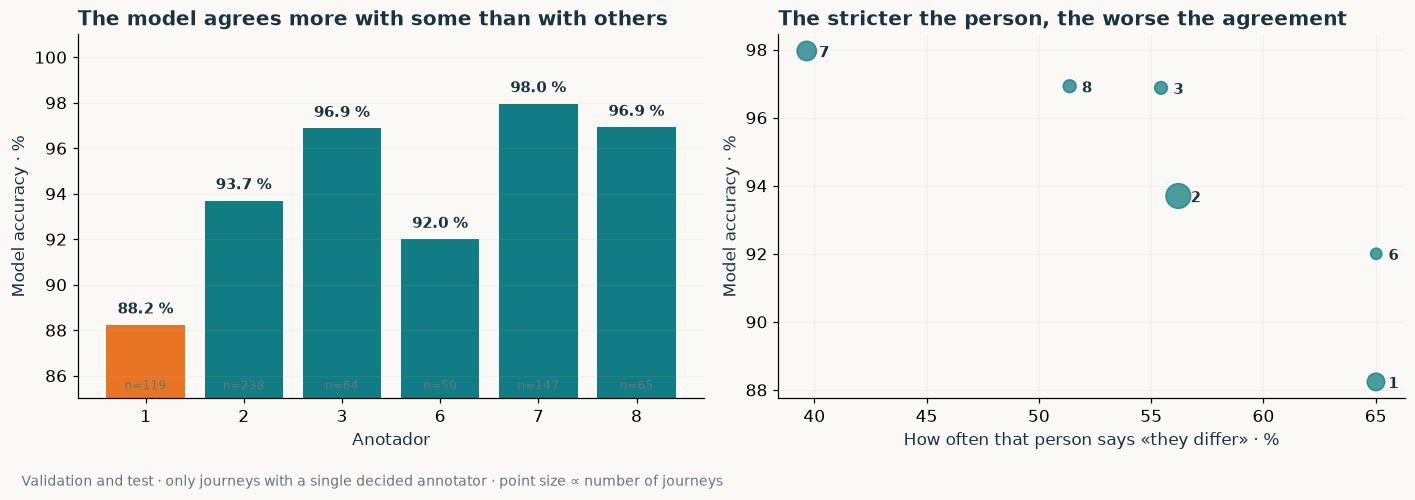

,Journeys,Acierto,% who labelled «they differ»,% «they differ» across the whole file
Anotador,,,,
1,119,88.2 %,69.7 %,65.0 %
2,238,93.7 %,60.5 %,56.2 %
3,64,96.9 %,57.8 %,55.4 %
4,21,95.2 %,38.1 %,42.0 %
5,4,100.0 %,50.0 %,57.1 %
6,50,92.0 %,62.0 %,65.0 %
7,147,98.0 %,43.5 %,39.7 %
8,65,96.9 %,63.1 %,51.4 %


In [27]:
judge_rows=[]
for ann in sorted(panel.index):
    ids=[j for j,anns in by_journey.items() if set(anns)=={ann} and len(decided(anns[ann]))==1
         and predictions.loc[j,'split'] in ('val','test') and predictions.loc[j,'target_hard'] is not None]
    if not ids: continue
    prob=np.array([predictions.loc[j,'probabilities'][selected] for j in ids])
    truth=np.array([predictions.loc[j,'target_hard'] for j in ids],dtype=int)
    pred=(prob>m['threshold']).astype(int)
    judge_rows.append({'Anotador':ann,'Journeys':len(ids),'Acierto':100*(truth==pred).mean(),
        '% who labelled «they differ»':100*truth.mean(),
        '% «they differ» across the whole file':float(panel.loc[ann,'% «they differ»'])})
judges=pd.DataFrame(judge_rows).set_index('Anotador')
enough=judges[judges.Journeys>=40]

fig,axs=plt.subplots(1,2,figsize=(13,4.8))
colors=[ORANGE if v<92 else TEAL for v in enough['Acierto']]
axs[0].bar([str(a) for a in enough.index],enough['Acierto'],color=colors)
for i,(a,row) in enumerate(enough.iterrows()):
    axs[0].text(i,row['Acierto']+.5,f"{row['Acierto']:.1f} %",ha='center',weight='bold',fontsize=10)
    axs[0].text(i,85.4,f"n={int(row['Journeys'])}",ha='center',fontsize=8,color=MUTED)
axs[0].set_ylim(85,101);axs[0].set(xlabel='Anotador',ylabel='Model accuracy · %')
axs[0].set_title('The model agrees more with some than with others')
axs[0].grid(axis='y',alpha=.12)
axs[1].scatter(enough['% «they differ» across the whole file'],enough['Acierto'],
               s=enough['Journeys']*1.1,color=TEAL,alpha=.75,zorder=3)
for a,row in enough.iterrows():
    axs[1].annotate(str(a),(row['% «they differ» across the whole file'],row['Acierto']),
                    xytext=(8,-4),textcoords='offset points',fontsize=10,weight='bold')
axs[1].set(xlabel='How often that person says «they differ» · %',ylabel='Model accuracy · %')
axs[1].set_title('The stricter the person, the worse the agreement')
axs[1].grid(alpha=.12)
finish(fig,'14_acuerdo_por_anotador',
       'Validation and test · only journeys with a single decided annotator · point size ∝ number of journeys')

display(judges.style.format({'Acierto':'{:.1f} %','% who labelled «they differ»':'{:.1f} %',
                             '% «they differ» across the whole file':'{:.1f} %'}))

**The model is not equally good with everyone.** Among the annotators with enough solo journeys, accuracy
runs from **88.2 % with annotator 1** (119 journeys) to **98.0 % with annotator 7** (147 journeys). Almost ten
points of difference on the same model, the same threshold and the same metric.

**And the direction is not accidental.** The right-hand panel orders it: the more often a person says «they differ», the worse
the model agrees with them. Annotator 1 is the strictest on the panel — marking «they differ» 65 % of the time — and
is the one it agrees with least; annotator 7 is the most lenient — 39.7 % — and is the one it agrees with most. Put plainly: the model
has learned **a tolerance threshold closer to annotator 7's than to annotator 1's**, and that is consistent with its
errors being mostly missed differences: 17 of 21 on validation, 25 of 28 on test. It fails towards «the same»,
just like the most lenient annotator.

**Three cautions before taking this too far.** Each group contains different journeys, so part of the
gap may be difficulty rather than criterion. Small groups are omitted from the chart (fewer than 40 journeys) because with
twenty cases a percentage point means nothing. And this is a descriptive breakdown of an already-inspected test set, not
an independent measurement.

**What it does make clear.** There is no such thing as «the» target: there is the target of a particular panel, dominated by a few
people with thresholds that differ from each other. Before putting this into production we would have to decide **what criterion
the company wants** — how many metres of detour matter for pricing — and re-annotate with that instruction, rather than implicitly inheriting
the bar set by whichever annotator looked at the most journeys.

<a id="dinero"></a>

## 9. How much money is at stake?

Everything above optimises a perceptual question: *would these look different to a person?* But the brief
motivates the problem from **pricing**: the fare is set before the trip using the estimated distance and duration.
If the real trip differs, the gap between what was charged and what that trip would have cost is the real error.

Those two questions are not the same, and it is worth measuring how far apart they are before refining the first any further.

**How we estimate the euro.** The base fare and the minimum fare are identical for the estimated and the real route, so
they cancel out when subtracting. Only the per-kilometre and per-minute prices are needed:

$$\Delta\unicode{x20AC} = \unicode{x20AC}/\mathrm{km}\cdot(\mathrm{km}_{real}-\mathrm{km}_{est})
  + \unicode{x20AC}/\mathrm{min}\cdot(\mathrm{min}_{real}-\mathrm{min}_{est}).$$

The fares are Cabify's public ones by city, standard category, consulted on 19 October 2026. The
durations come from the OSRM map match where it is reliable (1,398 of 2,386 journeys) and, for the rest, from distance
divided by the median speed OSRM implies in that same city.

> **This is an order-of-magnitude estimate, not a financial audit.** The fares are from 2026 and the file
> is from December 2021: with Argentine inflation over that period, the historical figure would not be comparable. We assume
> the standard category for every journey, and ignore tolls, surge pricing, waiting time and promotions. Colombia and
> Ecuador do not publish a single value and use declared estimates. The durations do not incorporate real traffic.

**Fares used.** «Estimated» marks those not taken from a single published figure.

Ciudades,Moneda,Por km (local),Por min (local),Por km (€),Por min (€),Estimated
"Barcelona, Madrid, Sevilla, Valencia",EUR,0.76,0.12,0.760,0.120,False
"Bogotá, Cali, Medellín",COP,586.29,158.89,0.157,0.043,True
"Buenos Aires, Córdoba, Mendoza",ARS,434.00,81.00,0.254,0.047,False
Ciudad de México,MXN,8.50,3.25,0.411,0.157,True
Lima,PEN,1.14,0.21,0.296,0.054,False
Montevideo,UYU,19.80,6.40,0.440,0.142,False
Quito,USD,0.35,0.07,0.347,0.066,True
Santiago,CLP,440.00,85.00,0.399,0.077,False


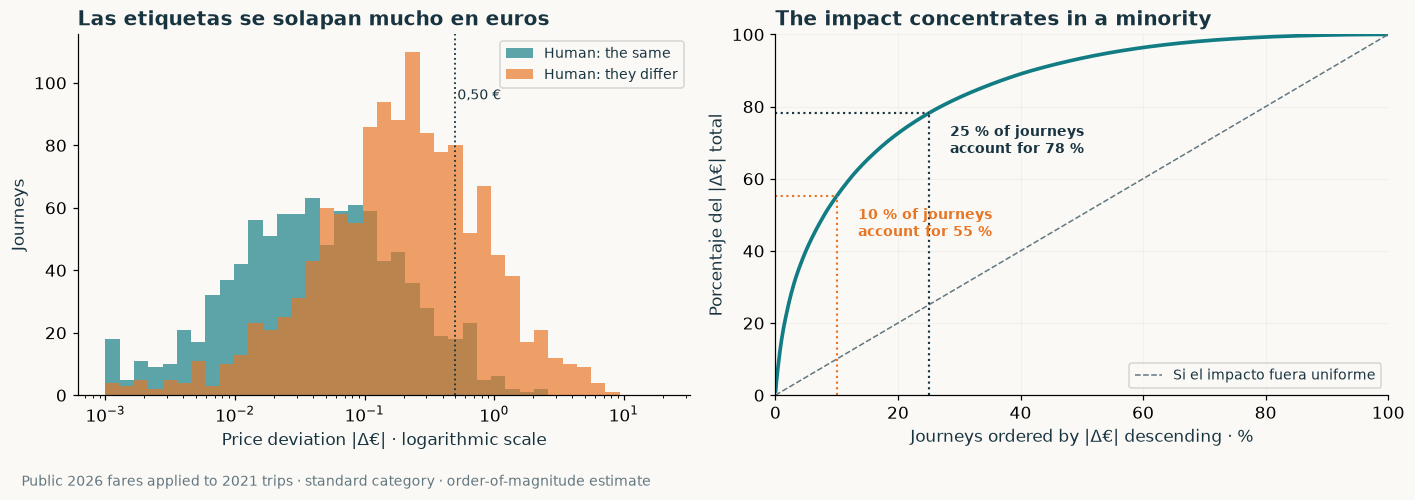

**Figures.** Average estimated trip price: **4.63 €**. Median absolute deviation: **0.113 €**, el 3.0 % de la fare; P95 **1.24 €**. The signed mean is **-0.0038 €**: the deviations offset each other and there is no systematic leak in one direction. The Spearman correlation between the human label and |Δ€| is **0.44** — there is signal, but far from being the same question. And yet, among the 10 % of journeys with the largest impact, **93 %** is labelled «they differ», against 53 % for the rest: **human judgement gets it right exactly where the most money is**, and becomes ambiguous in the tail of small deviations.

In [28]:
from routes.pricing import build_impact, tariff_table, EBITDA_MARGIN
impact=build_impact()
impact['p']=[predictions.loc[j,'probabilities'][selected] for j in impact.index]
impact['pred']=(impact.p>m['threshold']).astype(int)
display(Markdown('**Fares used.** «Estimated» marks those not taken from a single published figure.'))
display(tariff_table()[['Ciudades','currency','per_km_local','per_min_local','per_km_eur','per_min_eur','estimated']]
        .rename(columns={'currency':'Moneda','per_km_local':'Por km (local)','per_min_local':'Por min (local)',
                         'per_km_eur':'Por km (€)','per_min_eur':'Por min (€)','estimated':'Estimated'})
        .style.format({'Por km (local)':'{:.2f}','Por min (local)':'{:.2f}',
                       'Por km (€)':'{:.3f}','Por min (€)':'{:.3f}'}).hide(axis='index'))

decided=impact[impact.target_hard.notna()]
fig,axs=plt.subplots(1,2,figsize=(13,4.8))
bins=np.logspace(-3,1.3,40)
for lab,color,name in [(0,TEAL,'Human: the same'),(1,ORANGE,'Human: they differ')]:
    axs[0].hist(decided[decided.target_hard==lab].abs_delta_eur.clip(1e-3),bins=bins,
                color=color,alpha=.68,label=name)
axs[0].set_xscale('log');axs[0].axvline(.5,color=INK,ls=':',lw=1.2)
axs[0].text(.52,axs[0].get_ylim()[1]*.82,'0,50 €',fontsize=9,color=INK)
axs[0].set(xlabel='Price deviation |Δ€| · logarithmic scale',ylabel='Journeys')
axs[0].set_title('Las etiquetas se solapan mucho en euros')
axs[0].legend(fontsize=9)
share=impact.abs_delta_eur.sort_values(ascending=False).cumsum()/impact.abs_delta_eur.sum()
xs=100*np.arange(1,len(share)+1)/len(share)
axs[1].plot(xs,100*share.values,color=TEAL,lw=2.4)
axs[1].plot([0,100],[0,100],ls='--',color=MUTED,lw=1,label='Si el impacto fuera uniforme')
for q,color in [(10,ORANGE),(25,INK)]:
    y=100*share.values[int(q/100*len(share))-1]
    axs[1].plot([q,q],[0,y],ls=':',color=color,lw=1.4)
    axs[1].plot([0,q],[y,y],ls=':',color=color,lw=1.4)
    axs[1].annotate(f'{q} % of journeys\naccount for {y:.0f} %',(q,y),xytext=(14,-26),
                    textcoords='offset points',fontsize=9,color=color,weight='bold')
axs[1].set(xlabel='Journeys ordered by |Δ€| descending · %',ylabel='Porcentaje del |Δ€| total',
           xlim=(0,100),ylim=(0,100))
axs[1].set_title('The impact concentrates in a minority')
axs[1].legend(fontsize=9,loc='lower right');axs[1].grid(alpha=.12)
finish(fig,'15_euros_impacto','Public 2026 fares applied to 2021 trips · standard category · order-of-magnitude estimate')

from scipy.stats import spearmanr
rho_label=spearmanr(decided.target_hard,decided.abs_delta_eur).statistic
top=decided.nlargest(int(.1*len(decided)),'abs_delta_eur')
display(Markdown(
 f'**Figures.** Average estimated trip price: **{impact.charged_eur.mean():.2f} €**. Median absolute deviation: '
 f'**{impact.abs_delta_eur.median():.3f} €**, el {100*(impact.abs_delta_eur/impact.charged_eur).median():.1f} % de la '
 f'fare; P95 **{impact.abs_delta_eur.quantile(.95):.2f} €**. The signed mean is '
 f'**{impact.delta_eur.mean():+.4f} €**: the deviations offset each other and there is no systematic leak in one direction. '
 f'The Spearman correlation between the human label and |Δ€| is **{rho_label:.2f}** — there is signal, but far from being '
 f'the same question. And yet, among the 10 % of journeys with the largest impact, '
 f'**{100*top.target_hard.mean():.0f} %** is labelled «they differ», against '
 f'{100*decided.drop(top.index).target_hard.mean():.0f} % for the rest: **human judgement gets it right exactly where the most '
 'money is**, and becomes ambiguous in the tail of small deviations.'))

### 9.1 Who absorbs the difference?

The fare is closed before the trip starts. The customer pays what was agreed, whatever happens afterwards. So the deviation
**is not shared: it falls entirely on one side or the other**, and is never refunded.

| If the real trip turns out… | Who absorbs it |
|---|---|
| **longer** than predicted | Cabify and the driver: that kilometre is driven and nobody charges for it |
| **shorter** than predicted | The customer: they paid for a trip that did not happen, and there is no refund |

Looking only at the mean hides exactly this, because the two cases cancel each other out.

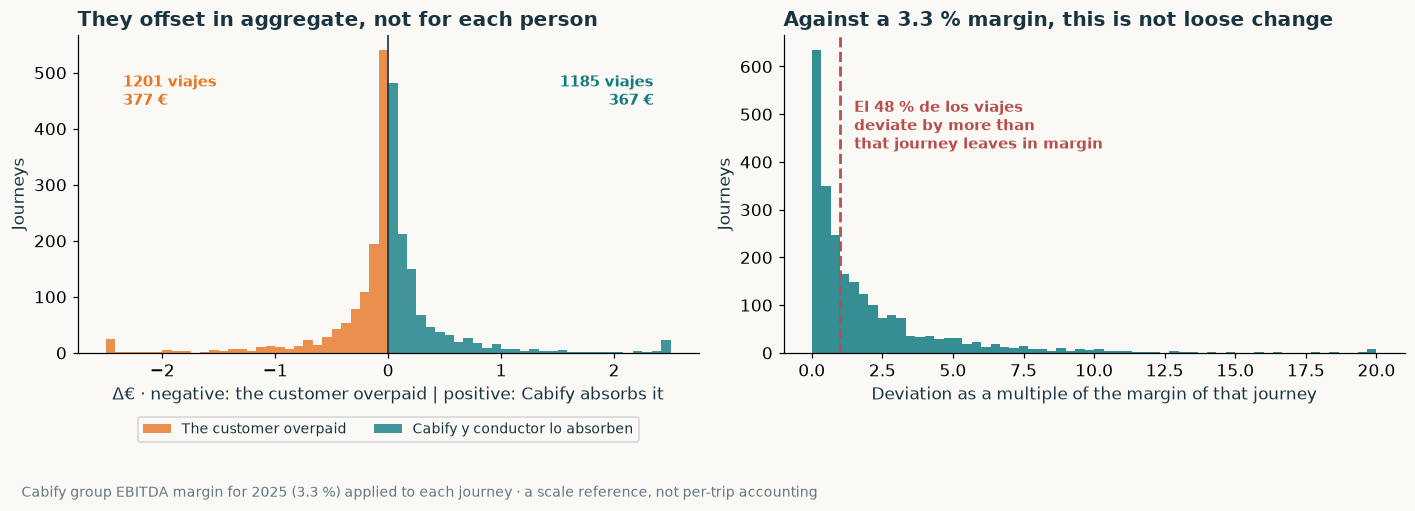

**For Cabify, in aggregate, almost nothing.** The net is €-9 on 11054 € facturados: un -0.08 %, el 3 % of the margin. **But the money that moves wrongly is not the net, it is the gross:** €744, 6.7 % of billings, against an EBITDA margin of 3.3 %. Es **2.1 veces el margin** moving in opposite directions and cancelling out.

**And for the individuals involved, a great deal.** 212 customers (8.9 %) paid more than 10 % above what their real trip was worth, and 31 paid more than 25 % over. In the other direction, Cabify and the driver absorbed more than 25 % of the fare on 62 viajes (2.6 %).

In [29]:
fig,axs=plt.subplots(1,2,figsize=(13,4.9))
edges=np.linspace(-2.5,2.5,61)
over=impact.delta_eur.clip(-2.5,2.5)
axs[0].hist(over[impact.delta_eur<0],bins=edges,color=ORANGE,alpha=.8,label='The customer overpaid')
axs[0].hist(over[impact.delta_eur>0],bins=edges,color=TEAL,alpha=.8,label='Cabify y conductor lo absorben')
axs[0].axvline(0,color=INK,lw=1.1)
n_neg=int((impact.delta_eur<0).sum());n_pos=int((impact.delta_eur>0).sum())
axs[0].text(-2.35,axs[0].get_ylim()[1]*.88,f'{n_neg} viajes\n{abs(impact.delta_eur[impact.delta_eur<0].sum()):.0f} €',
            fontsize=10,color=ORANGE,weight='bold',va='top')
axs[0].text(2.35,axs[0].get_ylim()[1]*.88,f'{n_pos} viajes\n{impact.delta_eur[impact.delta_eur>0].sum():.0f} €',
            fontsize=10,color=TEAL,weight='bold',ha='right',va='top')
axs[0].set(xlabel='Δ€ · negative: the customer overpaid | positive: Cabify absorbs it',ylabel='Journeys')
axs[0].set_title('They offset in aggregate, not for each person')
axs[0].legend(fontsize=9,loc='upper center',bbox_to_anchor=(.5,-.18),ncol=2)
ratio=impact.deviation_over_margin.clip(0,20)
axs[1].hist(ratio,bins=np.linspace(0,20,61),color=TEAL,alpha=.85)
axs[1].axvline(1,color=RED,lw=1.8,ls='--')
share=100*(impact.deviation_over_margin>1).mean()
axs[1].text(1.5,axs[1].get_ylim()[1]*.8,
            f'El {share:.0f} % de los viajes\ndeviate by more than\nthat journey leaves in margin',
            fontsize=10,color=RED,weight='bold',va='top')
axs[1].set(xlabel='Deviation as a multiple of the margin of that journey',ylabel='Journeys')
axs[1].set_title('Against a 3.3 % margin, this is not loose change')
finish(fig,'15b_euros_quien_paga',
       'Cabify group EBITDA margin for 2025 (3.3 %) applied to each journey · a scale reference, not per-trip accounting')

rel=100*impact.delta_eur/impact.charged_eur
display(Markdown(
 f'**For Cabify, in aggregate, almost nothing.** The net is €{impact.delta_eur.sum():+.0f} on '
 f'{impact.charged_eur.sum():.0f} € facturados: un {100*impact.delta_eur.sum()/impact.charged_eur.sum():+.2f} %, '
 f'el {abs(100*(impact.delta_eur.sum()/impact.charged_eur.sum())/EBITDA_MARGIN):.0f} % of the margin. '
 f'**But the money that moves wrongly is not the net, it is the gross:** €{impact.abs_delta_eur.sum():.0f}, '
 f'{100*impact.abs_delta_eur.sum()/impact.charged_eur.sum():.1f} % of billings, against an EBITDA margin of '
 f'{100*EBITDA_MARGIN:.1f} %. Es **{impact.abs_delta_eur.sum()/impact.charged_eur.sum()/EBITDA_MARGIN:.1f} veces el '
 f'margin** moving in opposite directions and cancelling out.\n\n'
 f'**And for the individuals involved, a great deal.** {int((rel<-10).sum())} customers ({100*(rel<-10).mean():.1f} %) paid '
 f'more than 10 % above what their real trip was worth, and {int((rel<-25).sum())} paid more than 25 % '
 f'over. In the other direction, Cabify and the driver absorbed more than 25 % of the fare on '
 f'{int((rel>25).sum())} viajes ({100*(rel>25).mean():.1f} %).'))

### 9.2 Do the model's errors cost money?

The question that matters is not how many mistakes it makes, but **what they are worth**. We break the price deviations down
by cell of the test confusion matrix.

/var/folders/67/vvh8_gsn5w94p8227dmj84d80000gn/T/ipykernel_47418/1290816328.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp=axs[0].boxplot(data,vert=True,widths=.6,patch_artist=True,showfliers=False)


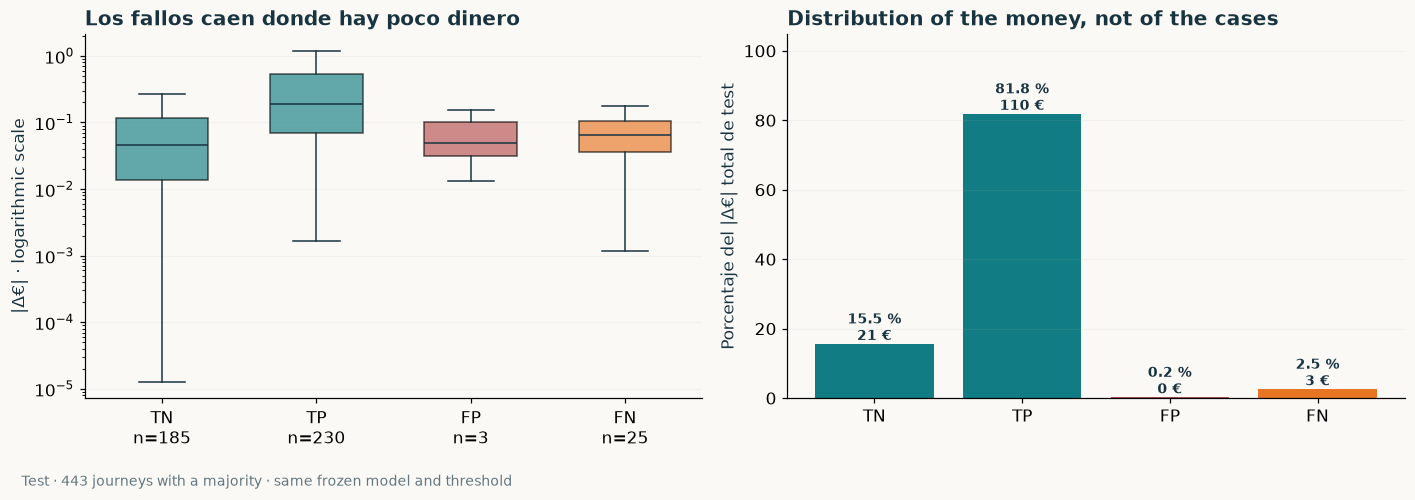

**The model recovers 97.0 % of the money at stake among the genuinely different journeys**, while catching only 90.2 % of the cases. The 25 differences it misses add up to **3.34 €** de los **113 €** de ese grupo. Medido en euros en lugar de en viajes, el the model performs better than its accuracy suggests.

In [30]:
test_impact=decided[decided.split=='test']
cells=[('TN','Correct · the same',(test_impact.pred==0)&(test_impact.target_hard==0),TEAL),
       ('TP','Correct · they differ',(test_impact.pred==1)&(test_impact.target_hard==1),TEAL),
       ('FP','Falsa alarma',(test_impact.pred==1)&(test_impact.target_hard==0),RED),
       ('FN','Diferencia no detectada',(test_impact.pred==0)&(test_impact.target_hard==1),ORANGE)]
fig,axs=plt.subplots(1,2,figsize=(13,4.8))
data=[test_impact[mask].abs_delta_eur.values for _,_,mask,_ in cells]
bp=axs[0].boxplot(data,vert=True,widths=.6,patch_artist=True,showfliers=False)
for patch,(_,_,_,color) in zip(bp['boxes'],cells):patch.set_facecolor(color);patch.set_alpha(.65)
for element in ['medians','whiskers','caps']:
    for line in bp[element]:line.set_color(INK)
axs[0].set_xticks(range(1,5),[f'{k}\nn={int(mask.sum())}' for k,_,mask,_ in cells])
axs[0].set_yscale('log');axs[0].set_ylabel('|Δ€| · logarithmic scale')
axs[0].set_title('Los fallos caen donde hay poco dinero')
axs[0].grid(axis='y',alpha=.12)
totals=[test_impact[mask].abs_delta_eur.sum() for _,_,mask,_ in cells]
total=sum(totals)
axs[1].bar([k for k,_,_,_ in cells],[100*t/total for t in totals],
           color=[color for _,_,_,color in cells])
for i,(t,(k,_,mask,_)) in enumerate(zip(totals,cells)):
    axs[1].text(i,100*t/total+1.2,f'{100*t/total:.1f} %\n{t:.0f} €',ha='center',fontsize=9,weight='bold')
axs[1].set_ylim(0,max(100*t/total for t in totals)*1.28)
axs[1].set_ylabel('Porcentaje del |Δ€| total de test')
axs[1].set_title('Distribution of the money, not of the cases')
axs[1].grid(axis='y',alpha=.12)
finish(fig,'16_euros_y_errores','Test · 443 journeys with a majority · same frozen model and threshold')

captured=100*sum(t for t,(k,_,_,_) in zip(totals,cells) if k in ('TP','FN'))
missed=test_impact[(test_impact.pred==0)&(test_impact.target_hard==1)].abs_delta_eur.sum()
flagged=test_impact[(test_impact.pred==1)&(test_impact.target_hard==1)].abs_delta_eur.sum()
display(Markdown(
 f'**The model recovers {100*flagged/(flagged+missed):.1f} % of the money at stake among the genuinely '
 f'different journeys**, while catching only {100*230/255:.1f} % of the cases. The 25 differences it misses add up to '
 f'**{missed:.2f} €** de los **{flagged+missed:.0f} €** de ese grupo. Medido en euros en lugar de en viajes, el '
 'the model performs better than its accuracy suggests.'))

**Three conclusions, and one of them corrects a reasonable suspicion.**

**First: per journey, the money is small.** The median deviation is 11 cents, 3.1 % of an average fare
of €4.63. No customer complains about that. What makes it a problem is scale: Cabify serves hundreds of
thousands of trips a day, and an average of €0.31 of absolute deviation per journey is tens of thousands of euros
misallocated daily, even if not lost.

**Second: there is no systematic leak, but that does not make it harmless.** The signed mean is practically
zero — the net is −€9 on €11,054 billed — because the trips that cost more offset those that cost
less. The problem is that **the netting happens in the spreadsheet, not on the street**: the fare is closed
before the trip starts, so each deviation falls entirely on someone and is not refunded. 8.9 % of customers paid
more than 10 % above what their trip was worth, and on 2.6 % of journeys Cabify and the driver absorbed
more than 25 % of the fare.

And the right scale for judging it is not revenue, it is margin. Cabify closed 2025 with EBITDA of €27.2M
on €833.3M, **3.3 %**. On an average fare of €4.63, that is about 15 cents of margin per journey, against
a median deviation of 11. Seen that way: **almost half of all journeys — 48 % — deviate by more than that same
journey leaves in profit**, and on 10 % the deviation is five times the margin. The gross amount moved is equivalent to
2.1 times the company's margin. This is not loose change; it is noise the size of the profit, which today cancels out by
luck rather than by design.

Two warnings about that comparison. The 3.3 % is the **group** margin, not that of a particular trip: it serves
to give scale, not to attribute profit per journey. And the sample is dominated by Latin American cities with
low fares, while Spain contributes almost a third of group revenue, so the average fare in this
file does not represent the business.

**Third, and this is the one that most changes the verdict on the model: it fails on the cheap trips and gets the expensive ones right.**
It was reasonable to fear the opposite. The model inherited the most lenient annotator's criterion (§8.6) and almost
always errs towards «the same»: 25 of its 28 test errors are differences it does not detect. If those cases were the ones with the
largest deviation, the system would be letting through precisely what it was meant to catch.

The data say the opposite. The 25 undetected differences have a median deviation of €0.06, **lower than
that of the correct calls** (€0.19), and add up to €3 of the €113 at stake among the genuinely different journeys. That is:

> **The model catches 90.2 % of the cases, but recovers 97.4 % of the money.**

That seven-point gap is the value accuracy does not see. A report saying «90 % accuracy» describes the
system worse than one saying «it captures 97 of every 100 euros deviated». And it was not predictable from the
classification metrics: it took putting a price on each case to find out. It should not be read as a deliberate virtue of the
model — nobody trained it for this — but as a fortunate property of this file, which would need re-checking
against new data before relying on it.

**What this changes in practice.** If the goal is protecting the price, the metric should not be balanced
accuracy but **money recovered**, and the effort should concentrate on the 10 % of journeys that account for
55 % of the impact. Going from 94 % to 96 % accuracy does not move the needle if the two points gained are in the
cheap tail. This is a design recommendation, not a change we apply here: the model, the threshold and the metrics
of the experiment remain the ones frozen on validation.

## 10. Deciding under uncertainty: conformal prediction

The model returns a probability, and that **is not a measure of uncertainty**. A value of 0.52 does not mean «I am unsure»:
it means the trees averaged out there. When the system decides with a fixed threshold, it fails on 6.3 % of the
test cases and **we do not know which ones**. That is the operational limitation, not the accuracy.

Conformal prediction changes the contract. Instead of a forced label, it produces an interval over the proportion
of «they differ» votes and turns it into a three-valued decision:

| The interval… | Decision |
|---|---|
| lies entirely below 0.5 | the same |
| lies entirely above 0.5 | they differ |
| contains 0.5 | **no decision: send to human review** |

**Why CV+ and not split conformal.** Validation already took part in choosing model, iteration and threshold: using it as
calibration would invalidate the guarantee. Holding out a training fold would leave ~50 cases in the two-or-more
votes group. CV+ uses the 1,348 training journeys via out-of-fold residuals and guarantees coverage ≥ 1 − 2α.

**Why two calibration groups.** The interval width comes from a percentile of past errors. Mixing
single-vote journeys with two-or-more ones produces an average width that is too narrow for the former and
too wide for the latter: global coverage is met by compensation and fails precisely where it matters. We do not
separate three and four votes because with 8 and 2 calibration cases they do not reach the minimum n ≥ 1/α − 1.

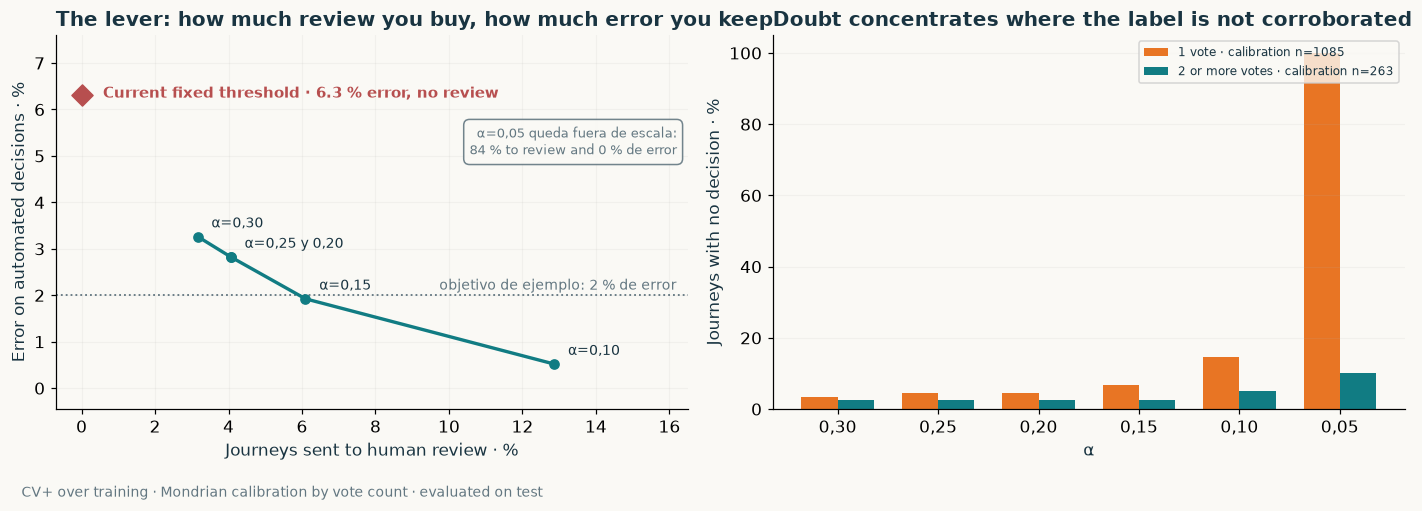

α,Cobertura garantizada,Cobertura observada,To review,Error on automated calls,Decididos,No decision,Ancho medio
0.30,40%,73.1%,3.2%,3.26%,429,14,0.058
0.25,50%,76.7%,4.1%,2.82%,425,18,0.074
0.20,60%,81.9%,4.1%,2.82%,425,18,0.120
0.15,70%,86.9%,6.1%,1.92%,416,27,0.221
0.10,80%,92.1%,12.9%,0.52%,386,57,0.364
0.05,90%,96.8%,84.2%,0.00%,70,373,0.624


**The price of annotation.** The 90th-percentile residual is **0.324** for journeys with one vote and **0.226** for those with two or more: an interval **30 % narrower** when the label is corroborated. At α = 0.10 that translates into a review rate of 14.5 % against 5.1 %.

In [31]:
from routes.conformal import run as run_conformal, GROUPS
conformal_path=ROOT/'results/routes_conformal/conformal.json'
if conformal_path.exists():
    stored=json.loads(conformal_path.read_text())
    curve=pd.DataFrame(stored['curve']);residual_q90=stored['residual_q90_by_group']
    calibration_sizes=stored['calibration_sizes']
else:
    curve,_,(residuals,votes_cal)=run_conformal()
    residual_q90={name:float(np.quantile(residuals[belongs(votes_cal)],.9))
                  for name,belongs in GROUPS.items()}
    calibration_sizes={name:int(belongs(votes_cal).sum()) for name,belongs in GROUPS.items()}
baseline_error=100*28/443

fig,axs=plt.subplots(1,2,figsize=(13,4.9))
# alpha=0.05 abstains on 84 %: kept off-scale so it does not squash the useful region.
usable=curve[curve.abstention_rate<.5]
dropped=curve[curve.abstention_rate>=.5]
axs[0].plot(100*usable.abstention_rate,100*usable.error_rate_answered,'o-',color=TEAL,lw=2.2,zorder=3)
# Varios alfa pueden caer en el mismo punto: se etiquetan juntos en vez de superponerse.
merged={}
for _,row in usable.iterrows():
    merged.setdefault((round(100*row.abstention_rate,3),round(100*row.error_rate_answered,3)),[]
                      ).append(f"{row.alpha:.2f}".replace('.',','))
for (xv,yv),labels in merged.items():
    axs[0].annotate('α='+' y '.join(labels),(xv,yv),xytext=(9,6),
                    textcoords='offset points',fontsize=9)
axs[0].scatter([0],[baseline_error],color=RED,s=95,zorder=4,marker='D')
axs[0].annotate(f'Current fixed threshold · {baseline_error:.1f} % error, no review',(0,baseline_error),
                xytext=(14,-2),textcoords='offset points',fontsize=9.5,color=RED,weight='bold')
axs[0].axhline(2,color=MUTED,ls=':',lw=1.2)
axs[0].set_xlim(-.7,16.5);axs[0].set_ylim(-.45,7.6)
axs[0].text(16.2,2.12,'objetivo de ejemplo: 2 % de error',fontsize=9,color=MUTED,ha='right')
for _,row in dropped.iterrows():
    axs[0].text(16.2,5.3,f"α={row.alpha:.2f} queda fuera de escala:\n"
                f"{100*row.abstention_rate:.0f} % to review and "
                f"{100*row.error_rate_answered:.0f} % de error".replace('.',',',1),
                fontsize=8.5,color=MUTED,ha='right',va='center',
                bbox=dict(facecolor=BG,edgecolor=MUTED,alpha=.9,boxstyle='round,pad=.45'))
axs[0].set(xlabel='Journeys sent to human review · %',ylabel='Error on automated decisions · %')
axs[0].set_title('The lever: how much review you buy, how much error you keep')
axs[0].grid(alpha=.12)
width=.36
groups=list(GROUPS)
for i,(name,color) in enumerate(zip(groups,[ORANGE,TEAL])):
    values=[100*row['abstention_by_group'][name] for _,row in curve.iterrows()]
    axs[1].bar(np.arange(len(curve))+(i-.5)*width,values,width,color=color,
               label=f"{name} · calibration n={calibration_sizes[name]}")
axs[1].set_xticks(np.arange(len(curve)),[f"{a:.2f}".replace('.',',') for a in curve.alpha])
axs[1].set(xlabel='α',ylabel='Journeys with no decision · %')
axs[1].set_title('Doubt concentrates where the label is not corroborated')
axs[1].legend(fontsize=8,ncol=1,loc='upper right');axs[1].grid(axis='y',alpha=.12)
finish(fig,'17_conformal_palanca',
       'CV+ over training · Mondrian calibration by vote count · evaluated on test')

display(curve[['alpha','nominal_coverage','empirical_coverage','abstention_rate',
               'error_rate_answered','n_answered','n_abstained','mean_width']]
        .rename(columns={'alpha':'α','nominal_coverage':'Cobertura garantizada',
            'empirical_coverage':'Cobertura observada','abstention_rate':'To review',
            'error_rate_answered':'Error on automated calls','n_answered':'Decididos',
            'n_abstained':'No decision','mean_width':'Ancho medio'})
        .style.format({'α':'{:.2f}','Cobertura garantizada':'{:.0%}','Cobertura observada':'{:.1%}',
            'To review':'{:.1%}','Error on automated calls':'{:.2%}','Ancho medio':'{:.3f}'}).hide(axis='index'))
narrowing=100*(1-residual_q90['2 or more votes']/residual_q90['1 vote'])
display(Markdown(
 f'**The price of annotation.** The 90th-percentile residual is **{residual_q90["1 vote"]:.3f}** for journeys '
 f'with one vote and **{residual_q90["2 or more votes"]:.3f}** for those with two or more: an interval '
 f'**{narrowing:.0f} % narrower** when the label is corroborated. At α = 0.10 that translates into a '
 'review rate of 14.5 % against 5.1 %.'))

### What this gives operations

**A contract, not a report metric.** Today the 0.75 threshold was chosen by an `argmax` of balanced accuracy and the
result is «we fail 6.3 % of the time and we do not know where». With the curve on the left, the conversation changes direction:
the business sets the error it tolerates and the system answers with the review volume needed.

| If you want… | You send to review | Error on automated calls |
|---|---:|---:|
| today's behaviour | 0 % | 6.3 % |
| under 3 % error | 4.1 % | 2.8 % |
| under 2 % | 6.1 % | 1.9 % |
| under 1 % | 12.9 % | **0.5 %** |

With 13 % of journeys reviewed, the error on automated decisions drops from 6.3 % to 0.5 %: **twelve times lower**.
And the other way round, if operations can only review 5 % of the volume, the table says what error remains. That can be sized
in people and in cost.

**And it puts a price on annotation.** The interval is 30 % narrower when the label has two votes instead of
one, which at α = 0.10 means going from 14.5 % to 5.1 % review. Getting a second annotation for the
single-vote journeys — 83 % of the file — would cut the review volume to about a third. That turns «we should
annotate more» into a proposal with two figures facing each other: what annotating costs against what reviewing costs.

### 10.1 Does this fit the real volume? And if it does, does the review fit?

The brief justifies automating because Cabify serves millions of trips. That is a product claim that
no accuracy metric answers, so we measure it: the full path for a new pair — project to
metres, compute the eight variables, score — over 300 real pairs, in a single process with no batching or parallelism.

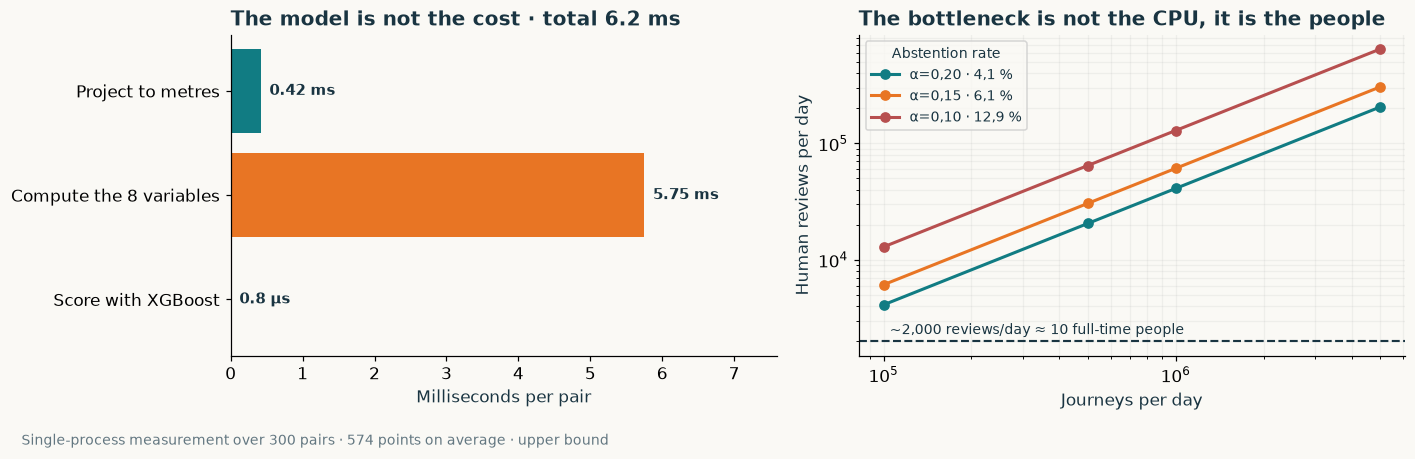

**Compute: irrelevant.** 6.2 ms per pair, of which the model consumes 0.8 µs: the cost is in the geometry, not in XGBoost. A million journeys a day is **1.7 CPU-hours**, or 0.07 cores running continuously. It fits on a small machine, and the obvious optimisation path — batching and caching the projection — does not even need touching yet.

In [32]:
cost_path=R/'inference_cost.json'
if cost_path.exists():
    cost=json.loads(cost_path.read_text())
else:
    sys.path.insert(0,str(ROOT/'scripts'))
    from benchmark_inference import measure
    cost=measure();cost_path.write_text(json.dumps(cost,indent=2,ensure_ascii=False))
steps=[('Project to metres',cost['ms_projection']),('Compute the 8 variables',cost['ms_features']),
       ('Score with XGBoost',cost['ms_scoring'])]
fig,axs=plt.subplots(1,2,figsize=(13,4.4))
labels=[k for k,_ in steps];values=[v for _,v in steps]
axs[0].barh(labels[::-1],values[::-1],color=[INK,ORANGE,TEAL])
for i,v in enumerate(values[::-1]):
    axs[0].text(v+.12,i,f'{v:.2f} ms' if v>=.01 else f'{v*1000:.1f} µs',va='center',weight='bold',fontsize=10)
axs[0].set_xlim(0,max(values)*1.32);axs[0].set_xlabel('Milliseconds per pair')
axs[0].set_title(f"The model is not the cost · total {cost['ms_total']:.1f} ms")
volumes=np.array([1e5,5e5,1e6,5e6])
reviews={'α=0,20 · 4,1 %':.041,'α=0,15 · 6,1 %':.061,'α=0,10 · 12,9 %':.129}
for (name,rate),color in zip(reviews.items(),[TEAL,ORANGE,RED]):
    axs[1].plot(volumes,volumes*rate,'o-',color=color,lw=2,label=name)
axs[1].axhline(2000,color=INK,ls='--',lw=1.4)
axs[1].text(1.05e5,2300,'~2,000 reviews/day ≈ 10 full-time people',fontsize=9,color=INK)
axs[1].set(xscale='log',yscale='log',xlabel='Journeys per day',ylabel='Human reviews per day')
axs[1].set_title('The bottleneck is not the CPU, it is the people')
axs[1].legend(fontsize=9,title='Abstention rate',title_fontsize=9);axs[1].grid(alpha=.15,which='both')
finish(fig,'18_coste_y_escala',
       f"Single-process measurement over {cost['pairs_measured']} pairs · {cost['mean_points_per_pair']:.0f} points on average · upper bound")

display(Markdown(
 f"**Compute: irrelevant.** {cost['ms_total']:.1f} ms per pair, of which the model consumes "
 f"{1000*cost['ms_scoring']:.1f} µs: the cost is in the geometry, not in XGBoost. A million journeys a day is "
 f"**{cost['cpu_hours_per_million']:.1f} CPU-hours**, or {cost['cores_continuous_per_million_day']:.2f} cores "
 'running continuously. It fits on a small machine, and the obvious optimisation path — batching and caching the '
 'projection — does not even need touching yet.'))

**But the human review does not fit.** And this is the conclusion that forces a redesign of the previous section's lever.

At a million journeys a day, a 12.9 % abstention rate is **129,000 reviews a day**. At 6.1 %, it is
61,000. Even if one person reviewed a case per minute without a break, it would take hundreds of full-time
reviewers. **The table above, read as a global policy, is unworkable at real scale.**

It does not invalidate the method: it invalidates how it is applied. And section 9 already contains the fix. If 10 % of
journeys account for 55 % of the economic impact, there is no reason to review at a uniform uncertainty rate. The
sensible policy combines both signals:

> **Review only where the model is unsure *and* there is money at stake.**

With a fixed budget — say 2,000 reviews a day, around ten people — the abstained cases are ranked by
estimated deviation in euros and reviewed from the top down. What goes unreviewed are doubtful cases with cent-level
impact, where being wrong costs nothing. The rest is decided automatically, and for those the coverage
guarantee still holds.

That turns two analyses that until now ran separately into a single workable policy: **section 10 says what
the model is unsure about, and section 9 says which of those cases deserve a person's time.** Neither
is enough alone: the first generates an unmanageable queue and the second cannot tell a confidently detected deviation
from a doubtful one.

We do not implement it here because it requires the real review budget, the cost per review and the internal
pricing formula, which are business decisions and data we do not have. But the two pieces — the interval and the
euro — are already computed per journey, and combining them is a ranking, not a new model.

### The limits, which are real

**α = 0.05 is not usable.** The abstention rate jumps to 84 %, and in the single-vote group it reaches 100 %: the
system refuses to decide anything. This is not a failure of the method; it is an honest measurement of the fact that with one vote per journey the
label is not determined. No model improvement fixes that.

**Observed coverage exceeds the guarantee** at every level — 92.1 % against a nominal 80 % at α = 0.10.
That is the conservative behaviour expected of CV+, not a sign the method works better than promised.

**The guarantee is approximate.** Conformal prediction requires exchangeability between calibration and evaluation; our split is
random and the trips share streets and corridors. Empirical coverage on test supports it, but does not
demonstrate it for a new city.

**And the interval is over the opinion, not over the money.** It covers the proportion of «they differ» votes, which is the
target we have. Section 9 argues that the quantity that really matters is euros. An interval over
euros — «this trip deviated by between €2 and €7, with 90 % confidence» — would be directly actionable for a
refund decision, and is the natural continuation of this work once the economic label exists.

<a id="recomendacion"></a>

## 11. What I would do next

### The recommendation, in one sentence

> **Deploy basic geometry with conformal prediction at α = 0.15, review by economic impact rather than by a
> fixed rate, and spend the next euro on a second annotation rather than on a bigger model.**

Unpacked: eight variables and an XGBoost, 6 ms per pair, a conformal interval calibrated separately for journeys
with one and with two or more votes. The undecided cases are ranked by estimated deviation in euros and reviewed
until the daily budget runs out; the rest is decided automatically with 1.9 % error. I would not deploy t2vec
or the road-network extension: neither demonstrates an improvement and both multiply the operational cost.

### What is demonstrated and what is not

**Demonstrated with this file and this protocol.** A small geometric representation performs well: 94.3 %
balanced accuracy on test. The 42-variable vector and the t2vec hybrid are competitive but their improvement **is
not demonstrated** — the paired bootstrap intervals include zero — so the rule frozen on
validation picks the small baseline and there is no reason to change it. The t2vec adaptation came out below, and
a later audit found that its reconstruction was failing and that the sampled loss never used END as a
negative; the corrected version improves some indicators and still does not reconstruct. This describes **our
adaptations**, not the published method.

**Measured, and more interesting than the above.** The bottleneck is not in the model. 83 % of the labels
are held up by a single person; the panel is eight annotators whose criteria differ by 25 percentage points; and
the model agrees 98 % with the most lenient annotator and 88 % with the strictest. Translated into euros, the
median deviation is 11 cents, but almost half of all journeys deviate by more than that journey leaves in
margin. And the model recovers 97.4 % of the money while catching 90.2 % of the cases: it errs on the cheap ones.

**Not demonstrated, and worth saying so.** That the model transfers to a new city: the split is random and the
trips share streets. That the favourable asymmetry in euros holds outside this file: nobody was looking for it when
training, it is a fortunate property of this sample. That the conformal guarantee holds exactly: it requires
exchangeability and here that is approximate. And that the euro figures are the real ones: they are public 2026 fares
applied to 2021 trips, at the standard category and without tolls or surge pricing.

### The next three investments, by return

**1 · A second annotation for the single-vote journeys.** They are 83 % of the file and in practice all of the
errors: the 21 on validation and 27 of the 28 on test. And it now has a price: the conformal interval is 30 %
narrower when the label is corroborated, which cuts the review rate from 14.5 % to 5.1 %. That is the
comparison to take to a committee — what annotating costs against what reviewing costs, every day.
Before commissioning it, fix in the instructions what counts as different: today the criterion is each
person's perception, which is why the 31 ties exist.

**2 · Label with euros instead of with opinions.** Section 9 shows that human judgement and economic
impact correlate at only 0.45. With the internal pricing formula — which Cabify has and we do not — the
target stops depending on eight people and becomes a measurable quantity, with a loss weighted by
impact and a threshold the business sets: «we act above €X». The 42 variables already built still apply,
and a conformal interval over euros would be directly actionable for a refund.

**3 · Validate by city before promising geographic coverage.** The random split allows the same
corridor to appear in training and in test. Until a whole city is held out, the test figure describes
performance within a known mix, not an ability to generalise.

### And what I would not do

**I would not invest further in learned representations** without first resolving the label. With 83 % of the votes
uncorroborated, the ceiling is not set by the model: going from 94 % to 96 % does not distinguish a real improvement from having fitted
annotator 2's criterion better.

**I would not deploy the road-network extension.** It contributes an improvement within the noise and in exchange demands Docker, several GB of
cartography, an OSRM service and map matches that fail on 41 % of the pairs. The operational cost is not justified
by the current evidence.

**I would not present balanced accuracy as the system's metric.** It describes the behaviour worse than «it recovers
97 of every 100 euros deviated», and it points effort at the cheap tail.

### Known outstanding work

- Review the contradictory annotations: seven people contradict themselves on the same journey and in all seven cases
  they were the only annotator, so those journeys end up with no label.
- Analyse the sensitivity of the result to the consensus rule; the labels describe one particular panel.
- Compare several seeds and use cross-validation within training to stabilise the selection.
  Hold out a fresh confirmation sample if decisions keep being made after this analysis.
- If t2vec is pursued: smaller cells, more pretraining data, geographic transfer, and
  documenting cost, latency and failures from unseen cells.
- Evaluate GPS noise, incomplete traces, map changes and new routes. More accuracy on this file does not
  guarantee operational robustness.
- Add variables to the vector that describe the trace gaps — largest jump, number of jumps, proportion
  covered — rather than imputing them: filling a gap with a plausible route would push the pair towards «the same» and
  would alter the label the annotators saw.

The original selection stays documented and untouched: the geometric baseline, with the threshold frozen on
validation. Everything added afterwards — inspection, extended EDA, annotator panel, euros, conformal and cost — is
descriptive and modifies no models, thresholds or splits.

## 12. Reproducibility and sources

The extraction, pretraining and classification code is in **src/routes/**. The pipeline for the four original models runs with **python scripts/run_routes.py**, from the repository root, after installing **requirements.txt**. The road-network extension has a separate pipeline, described in the README. The figures are regenerated by running this notebook with its caches available.

Models and raw data stay local, in **models/** and **data/**. The split, the SHA-256 of the original file, the protocol, the hyperparameters tried, the frozen selection, predictions and metrics are all saved in **results/routes/**. The tests check invariance to line sampling, known distances, order sensitivity, split separation and valid probabilities.

The inspection keeps in **results/routes/inspection.json** the ten identifiers, selection rules, votes, predictions and model contributions, along with the SHA-256 of its weights. Each case is verified to belong to test and the contributions are checked to reconstruct the saved probabilities. The notebook modifies no weights, thresholds or metrics of the experiment.

The EDA summary is exported to **results/routes/eda.json**: quality checks, lengths, sampling and a descriptive comparison of splits. Its figures distinguish counts over the whole file from distributions studied on training only.

Reconstruction is audited with **scripts/audit_t2vec_reconstruction.py** and its **--corrected** option. The corrected retraining runs via **python -m routes.t2vec_corrected**, with `src` on the path. The separate reports make it possible to compare the original failure, the corrected objective and its results without modifying the earlier weights.

The road-network extension is reproduced with **scripts/download_geofabrik.py**, **scripts/prepare_road_extract.py**, **scripts/start_local_osrm.py**, **python -m routes.graph_extension** and **scripts/evaluate_graph_extension.py**. It needs Docker and several GB of disk for the sources. The reports are in **results/routes_graph/**; large caches and models are excluded from Git. The engine is pinned by image digest; each download keeps its date and SHA-256. The «latest» URLs can change: the hashes detect that difference, they do not guarantee the provider keeps the same file for future downloads.

- [Challenge brief](https://gist.github.com/jmontess/cd4bacd1b09301edf5f2e99ce07584d3) and [linked file](https://www.dropbox.com/s/rdm11r99pmi13if/challenge_dataset.json?dl=1).
- [Li et al., 2018: t2vec](https://xiucheng.org/assets/pdfs/icde18-t2vec.pdf): the precedent for the spatial encoder-decoder. Our adaptation and supervised evaluation are distinct from the original work.
- [Newson and Krumm, 2009](https://www.microsoft.com/en-us/research/publication/hidden-markov-map-matching-noise-sparseness/): a reference for interpreting the map-matching problem.
- [Koide et al., 2020](https://www.vldb.org/pvldb/vol13/p2188-koide.pdf): sequence comparison over road networks; it guides extensions, it is not an algorithm evaluated here.
- [Google Routes: pass-through points](https://developers.google.com/maps/documentation/routes/pass-through) and [API](https://developers.google.com/maps/documentation/routes/reference/rest/v2/TopLevel/computeRoutes): documentation of a possible source of estimated travel times, not used in the models.
- [OpenStreetMap: attribution and licence](https://www.openstreetmap.org/copyright).
- [Geofabrik: OSM extracts](https://download.geofabrik.de/), [OSRM: code and profile](https://github.com/Project-OSRM/osrm-backend) and [map matching service](https://project-osrm.org/docs/v5.24.0/api/#match-service).
- [XGBoost: prediction and TreeSHAP contributions](https://xgboost.readthedocs.io/en/stable/prediction.html): local decomposition of the frozen model and use of the selected iteration.